# Exercises for Particle Physics I
## Exercise 03 - EMCal in a nutshell

    D. Wong, November 2026

## Setup

It is very likely that you will need the following packages, so don't forget to import them!

In [1]:
import sys
from pathlib import Path
import numpy as np
import uproot
import matplotlib.pyplot as plt

ROOT = Path().resolve().parent.parent
SRC_DIR = ROOT / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from exercise03 import exercise3_utils as ex3

plt.rcParams['figure.dpi'] = 100

<a name='section_1_0'></a>
<hr style="height: 1px;">

<h1 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Section 1: Electromagnetic cascades in a calorimeter</h1>


An **electromagnetic (EM) shower** is a cascade of particles, including photons, electrons, and positrons, forms when a high-energy electron or photon interacts with dense material and produces a chain of secondary particles. <br>
Photons convert into electron–positron pairs, and these charged particles in turn emit bremsstrahlung photons, repeating the process as the shower multiplies and spreads. <br>
The cascade continues until particle energies fall below a critical value, where ionization dominates and the shower dies out. <br>
In an electromagnetic calorimeter (EMCal), this process is harnessed to measure particle energies, where the deposited energy is converted into measurable signals (e.g., light). <br>
The total signal provides a precise estimate of the incident electron or photon’s energy and impact position, making EM calorimetry a key technique in modern high-energy physics experiments.

<div style="text-align: center;">
  <img src="figures/shower.gif" width="50%">
  <figcaption style="margin-top: 6px; font-size: 90%;"> Sketch of an electromagnetic cascade in an absorber: pair production and bremsstrahlung alternate (scale bar: one radiation length $X_0$). </figcaption>
</div>

<div style="text-align: center;">
  <img src="figures/x0.png" width="50%">
  <figcaption style="margin-top: 6px; font-size: 90%;"> Heitler model of shower development: after every radiation length the number of particles doubles and the energy per particle halves. </figcaption>
</div>

Bremsstrahlung is the dominant energy-loss process for electrons and positrons above the *critical energy* $E_c$ (about 10 MeV in heavy materials), while photons lose energy mainly through the production of electron–positron pairs.
High-energy photons, electrons and positrons therefore create a cascade of secondary particles, known as an "electromagnetic shower".

The following approximate formulas (see the PDG review *Passage of particles through matter*) describe the main properties of a shower:

- $\textbf{Radiation length} ~X_0$: mean distance over which a high-energy electron loses all but $1/e$ of its energy by bremsstrahlung (and $7/9$ of the mean free path for pair production of a photon). A practical approximation is

    $$ X_0 \approx \frac{716.4\,A}{Z(Z+1)\,\ln\!\left(287/\sqrt{Z}\right)}\ \ \text{g\,cm}^{-2}, $$

    where $A$ is the atomic mass in g/mol and $Z$ the atomic number; divide by the density to obtain $X_0$ in cm.
    For a compound, the radiation length follows from the mass fractions $w_j$ of its elements: $1/X_0 = \sum_j w_j / X_{0,j}$.

- $\textbf{Critical energy} ~E_c$: energy at which the ionisation loss per radiation length equals the electron energy (Rossi's definition). For solids and liquids,

    $$ E_c \approx \frac{610\ \text{MeV}}{Z + 1.24}. $$

- $\textbf{Molière radius} ~R_M$: characteristic lateral size of the shower, mainly due to multiple scattering of the electrons:

    $$ R_M = \frac{E_s}{E_c}\, X_0, \qquad E_s = 21.2\ \text{MeV}. $$

    About 90% of the shower energy is contained in a cylinder of radius $R_M$ (95% within about $2 R_M$).

- $\textbf{Depth of the shower maximum} ~x_{\text{max}}$: in the simple Heitler model every particle splits into two after one radiation length, until the energy per particle reaches $E_c$:

    $$ x_{\text{max}} = \frac{\ln(E / E_c)}{\ln 2}\, X_0 . $$

    A more realistic parametrisation (PDG) is $x_\text{max} = \left[\ln(E/E_c) - 0.5\right] X_0$ for electrons ($+0.5$ for photons). The depth grows only *logarithmically* with the energy $E$.

<div style="text-align: center;">
  <img src="figures/e_eng_loss.png" width="50%">
  <figcaption style="margin-top: 6px; font-size: 90%;"> Fractional energy loss per radiation length of electrons and positrons in lead as a function of energy: bremsstrahlung dominates above the critical energy (source: PDG, <i>Review of Particle Physics</i>, "Passage of particles through matter"). </figcaption>
</div>

<a name='section_1_1'></a>
<hr style="height: 1px;">


<h3 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Problem 1.1: EMCal dimension estimation</h3>

**Electromagnetic calorimeters (EMCal)** are designed to measure the energy of particles using high-$Z$ materials to contain the shower.

In a scintillating calorimeter, the charged particles of the shower produce scintillation light, and the amount of light collected is proportional to the energy of the incident particle. This makes an EMCal ideal for precisely measuring the energy of electrons, positrons and photons.

The CMS detector at the LHC uses about 76 000 lead tungstate (PbWO$_4$) crystals as its EMCal (CMS Collaboration, *The CMS experiment at the CERN LHC*, JINST 3 (2008) S08004).

<div class="alert alert-info">
<strong>Exercise:</strong> 
Calculate the radiation length and critical energy of Pb and PbWO$_4$. Then, compare your results with those available on the PDG website: <br>
- Pb: <a href="https://pdg.lbl.gov/2024/AtomicNuclearProperties/HTML/lead_Pb.html">link</a><br>
- PbWO4: <a href="https://pdg.lbl.gov/2024/AtomicNuclearProperties/HTML/lead_tungstate.html">link</a><br>
<br>

For PbWO$_4$, assume an effective atomic number Z = $\dfrac{Z_{Pb} + Z_W + 4 \times Z_O}{6}$ = $\dfrac{82 + 74 + 4 \times 8}{6}$ = 31.3 <br>
and an effective atomic weight A = $\dfrac{A_{Pb} + A_W + 4 \times A_O}{6}$ = $\dfrac{207.2 + 183.8 + 4 \times 16}{6}$ = 75.8 <br>

<br>

Do your calculated values correspond to what you found in the PDG page?

</div>

In [2]:
# --> enter your code

def critical_energy(Z):
    '''Critical energy in MeV (PDG approximation for solids and liquids).'''
    return 610.0 / (Z + 1.24)


def radiation_length(A, Z):
    '''Radiation length in g/cm^2 (PDG approximation, A in g/mol).'''
    return 716.4 * A / (Z * (Z + 1) * np.log(287 / np.sqrt(Z)))


materials = {   # Z, A, density (g/cm^3), PDG values for comparison
    'Pb':                         dict(Z=82,   A=207.2, rho=11.35, X0_pdg=6.37, Ec_pdg=7.43),
    'PbWO4 (atom-averaged Z, A)': dict(Z=31.3, A=75.8,  rho=8.30,  X0_pdg=7.39, Ec_pdg=9.64),
}
for name, m in materials.items():
    X0, Ec = radiation_length(m['A'], m['Z']), critical_energy(m['Z'])
    print(f"{name:27s}: X0 = {X0:5.2f} g/cm2 = {X0 / m['rho']:.3f} cm  (PDG {m['X0_pdg']} g/cm2)"
          f"  |  Ec = {Ec:5.2f} MeV  (PDG {m['Ec_pdg']} MeV)")

# bonus: the correct way for a compound, 1/X0 = sum_j w_j / X0_j with mass fractions w_j
elements = {'Pb': (82, 207.2, 1), 'W': (74, 183.84, 1), 'O': (8, 16.00, 4)}   # Z, A, atoms per molecule
M = sum(A * n for Z, A, n in elements.values())
inv_X0 = sum((A * n / M) / radiation_length(A, Z) for Z, A, n in elements.values())
print(f'PbWO4 from mass fractions   : X0 = {1 / inv_X0:5.2f} g/cm2 = {1 / inv_X0 / 8.30:.3f} cm  (PDG 7.39 g/cm2)')

Pb                         : X0 =  6.31 g/cm2 = 0.556 cm  (PDG 6.37 g/cm2)  |  Ec =  7.33 MeV  (PDG 7.43 MeV)
PbWO4 (atom-averaged Z, A) : X0 = 13.64 g/cm2 = 1.643 cm  (PDG 7.39 g/cm2)  |  Ec = 18.75 MeV  (PDG 9.64 MeV)
PbWO4 from mass fractions   : X0 =  7.36 g/cm2 = 0.886 cm  (PDG 7.39 g/cm2)


<div class="alert alert-success">

*--> (put your text here)*

For lead the approximations agree with the PDG values to about 1&ndash;2&nbsp;%.
For PbWO$_4$ the atom-averaged $Z = 31.3$ and $A = 75.8$ give a radiation length about twice too long and a critical energy about twice too high.
The radiation length scales roughly like $A/Z^2$, so the heavy Pb and W atoms dominate: an average over the number of atoms gives far too much weight to the four light oxygen atoms.
The correct combination uses the mass fractions, $1/X_0 = \sum_j w_j/X_{0,j}$, which reproduces the PDG value.
</div>

Averaging $Z$ and $A$ over the atoms of a compound does not give a good estimate of the radiation length and the critical energy.

Use the more precise PDG values for PbWO$_4$ in the following ([PDG website](https://pdg.lbl.gov/2024/AtomicNuclearProperties/); note that lead tungstate is an inorganic scintillator): $X_0 = 0.89$ cm, $E_c = 9.64$ MeV.

<div class="alert alert-info">
<strong>Exercise:</strong> 
Estimate the approximate dimension of an electromagnetic shower in a PbWO$_4$ crystal (longitudinal depth and transverse width) for a 100 GeV electron.
</div>

In [3]:
# --> enter your code

E = 100e3       # MeV (100 GeV electron)
X0 = 0.8903     # cm, PbWO4 (PDG)
Ec = 9.64       # MeV, PbWO4 (PDG, electrons)
Es = 21.2       # MeV

R_M = Es / Ec * X0
print(f'Moliere radius R_M = {R_M:.2f} cm  ->  ~95% of the energy within 2 R_M = {2 * R_M:.1f} cm (diameter {4 * R_M:.1f} cm)')

t_heitler = np.log(E / Ec) / np.log(2)
t_pdg = np.log(E / Ec) - 0.5
print(f'Shower maximum (Heitler model): {t_heitler:.1f} X0 = {t_heitler * X0:.1f} cm')
print(f'Shower maximum (PDG)          : {t_pdg:.1f} X0 = {t_pdg * X0:.1f} cm')

Moliere radius R_M = 1.96 cm  ->  ~95% of the energy within 2 R_M = 3.9 cm (diameter 7.8 cm)
Shower maximum (Heitler model): 13.3 X0 = 11.9 cm
Shower maximum (PDG)          : 8.7 X0 = 7.8 cm


<div class="alert alert-info">
<strong>Exercise:</strong> 
Is this a good estimation for the size an EMCal should have? The CMS EMCal crystals are actually 25 $X_0$ long: why?</div>

<div class="alert alert-success">

*--> (put your text here)*

The shower maximum is only the point where the number of particles is largest: the shower continues well beyond it, and its tail extends over many radiation lengths.
To contain 95&nbsp;% of the energy longitudinally, the PDG gives roughly $t_{95\%} \approx x_\text{max} + 0.08\,Z + 9.6$ radiation lengths, i.e. more than 20&nbsp;$X_0$ for a heavy material.
Energy leaking out of the back fluctuates strongly from event to event and spoils the energy resolution.
Since the depth grows only logarithmically with energy, 25&nbsp;$X_0$ (about 22&nbsp;cm of PbWO$_4$) is enough for electrons and photons up to the TeV range.
Laterally, $2R_M \approx 4$&nbsp;cm: a shower spreads over a few crystals of 2.2&nbsp;cm width, which is what allows a precise position measurement from the energy sharing.
</div>

<a name='section_1_2'></a>
<hr style="height: 1px;">


<h3 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Problem 1.2: Shape of muon clusters on EMCal</h3>

For muons with energies of the order of 100 GeV, the ionization is the dominant energy-loss process. <br>
Muons travel significant distances in dense materials: for example, a 10 GeV muon loses about 10 MeV/cm in iron and has a range of several meters.

<div style="text-align: center;">
  <img src="figures/mu_eng_loss.png" width="50%">
  <figcaption style="margin-top: 6px; font-size: 90%;"> Mass stopping power of positive muons in copper as a function of $\beta\gamma$; the minimum of ionisation and the muon critical energy $E_{\mu c}$ are marked (source: PDG, <i>Review of Particle Physics</i>, "Passage of particles through matter"). </figcaption>
</div>

A particle with a momentum close to the minimum ionization point is called a minimum ionizing particle (MIP). <br>
A particle with a much larger momentum but with an energy loss comparable to that of the minimum ionization point is also called a MIP.

For bremsstrahlung process, the energy loss through distance is given by:

$-\dfrac{dE}{dx} \propto \dfrac{Z^2 E}{m_{particle}^2}$.

<div class="alert alert-info">
<strong>Exercise:</strong>
Consider a muon with a momentum of 50 GeV passing through the CMS EMCal, which has a depth of approximately 22 cm. What do you expect to see in the calorimeter: what is the shape of the energy deposit, and how much energy do you expect?
</div>

<div class="alert alert-success">

*--> (put your text here)*

A 50 GeV muon is (close to) a minimum-ionising particle. Its bremsstrahlung loss is suppressed by $(m_e/m_\mu)^2 \approx 2\times10^{-5}$ compared to an electron, so it does **not** start an electromagnetic shower.
It loses energy by ionisation along its straight track: with $(dE/dx)_\text{min} \approx 10.2$ MeV/cm in PbWO$_4$, it deposits about $10.2\ \text{MeV/cm} \times 22\ \text{cm} \approx 0.2$ GeV, essentially in the one crystal it traverses.
Event by event the deposit follows a Landau distribution (a narrow "MIP peak" with a tail to higher energies). The muon then leaves the calorimeter with almost all of its 50 GeV.
This MIP peak is often used to calibrate calorimeter cells.
</div>

<div class="alert alert-info">
<strong>Exercise:</strong>
Electrons and positrons start losing most of their energy by bremsstrahlung above a certain transition energy (how is this transition energy called?).
Estimate the corresponding energy for a muon in PbWO$_4$, i.e. the energy above which radiative losses exceed ionisation losses, by scaling the electron value with the mass dependence of bremsstrahlung.
Compare your estimate with the *muon critical energy* listed on the PDG page of PbWO$_4$.
</div>

In [4]:
# --> enter your code

Ec_e = 9.64                    # MeV, critical energy of electrons in PbWO4 (PDG)
m_e, m_mu = 0.511, 105.66      # MeV

Ec_mu_naive = Ec_e * (m_mu / m_e) ** 2
print(f'Naive scaling: E_c(muon) ~ {Ec_mu_naive / 1e3:.0f} GeV   (PDG: 170 GeV for PbWO4)')

Naive scaling: E_c(muon) ~ 412 GeV   (PDG: 170 GeV for PbWO4)


<div class="alert alert-success">

*--> (put your text here)*

The transition energy is the critical energy $E_c$. Scaling with $(m_\mu/m_e)^2$ gives about 400 GeV.
The PDG lists 170 GeV for PbWO$_4$ (141 GeV for Pb). The naive estimate is too high for two reasons:
- For muons, direct $e^+e^-$ pair production and photonuclear interactions add to bremsstrahlung, and pair production is the largest radiative loss at high energy.
- The muon ionisation loss itself grows slowly with energy.

Either way, muons in the momentum range of most collider measurements stay minimum-ionising in an EMCal.
</div>

<a name='section_1_3'></a>
<hr style="height: 1px;">


<h3 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Problem 1.3: Detector proposal</h3>

<div class="alert alert-info">
<strong>Exercise:</strong> 
How would you implement an experimental apparatus involving an EMCal so that it can distinguish electrons from photons and muons?</div>

<div class="alert alert-success">

*--> (put your text here)*

Put a tracking detector in a magnetic field in front of the EMCal, and muon chambers behind the calorimeters (and behind additional absorber, e.g. the iron return yoke):
- **Electrons:** a curved track whose momentum $p$ matches the energy $E$ of a compact EMCal shower ($E/p \approx 1$).
- **Photons:** a compact EMCal shower without a matching track (unless the photon converted into $e^+e^-$ in the tracker material).
- **Muons:** a track that deposits only a MIP signal (about 0.2 GeV) in the EMCal, $E/p \ll 1$, and that is also seen in the muon chambers.

The shower shape (lateral width, Problem 2.2) further separates electrons and photons from hadrons.
</div>

<a name='section_2_0'></a>
<hr style="height: 1px;">


<h1 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Section 2: Calorimetry and reconstruction</h1>


In this section, we consider an electromagnetic calorimeter with the geometry of the lead–scintillator EMCal of the [PHENIX](https://www.phenix.bnl.gov/) experiment at Brookhaven National Laboratory.

We have prepared ROOT n-tuples containing the simulated hits in this EMCal, using a particle gun with energies between 5 GeV and 80 GeV.

The EMCal covers an area of $2~\text{m}~\times~4~\text{m}$ perpendicular to the beam line.

This corresponds to 3 × 6 EMCal super modules, where:
- 1 EMCal super module = 6 × 6 = 36 EMCal modules,
- 1 EMCal module is 11 cm × 11 cm and contains 2 × 2 = 4 towers (channels), with a granularity of approximately 5.5 cm.

In total, there are 2592 towers (channels) to read out the energy deposits.

For practical purposes, consider the EMCal as a 2D matrix of 2592 channels (72 horizontal × 36 vertical), where each channel has a size of 5.535 cm × 5.535 cm × 36.96 cm.

<div style="text-align: center;">
  <img src="figures/PHENIX_color_view.gif" width="50%">
  <figcaption style="margin-top: 6px; font-size: 90%;"> Schematic view of the PHENIX detector (source: PHENIX Collaboration, BNL). </figcaption>
</div>

We provide rootfiles containing the readout for electron and dielectron events from the EMCal.

The readout has the following format:
```
'elmID': array([1207, 1208, 1243, 1244, 1245, 1246, 1279, 1280, 1281, 1282,
       1283, 1314, 1315, 1316, 1317, 1318, 1352, 1387, 1388, 1389, 1390],
       dtype=int32), 
'edep': array([2.1672759e-03, 2.3865167e-03, 6.9637364e-03, 6.5519638e-02,
       5.9960117e-03, 1.5223619e-03, 1.5519783e-02, 1.3763729e+00,
       1.7959915e-02, 1.1316873e-03, 2.6412117e-03, 1.1183993e-03,
       3.0373151e-03, 1.8506199e-02, 5.9680296e-03, 1.2358509e-03,
       1.5430434e-03, 1.2675102e-03, 8.8297541e-04, 8.7783835e-04,
       1.5175857e-03],
       dtype=float32)
```

where `elmID[X]` is the identifier ($\textit{element ID}$) of the channel that measured a given $\textit{energy deposit}$ `edep[X]`.

The values of `elmID[X]` vary from 0 to 2591 (corresponding to the total number of channels).

To conveniently read the ROOT files, we provide the `exercise3_utils.py` module (imported as `ex3`).

Use the following code snippet to read one event:

```python
# EMCal hits of event 5 of the electron sample
elmID, edep = ex3.get_hit_data('electron', 5)   # sample: 'electron' or 'dielectron', event number: 0-9
edep = edep / ex3.sfc                           # converts the deposited energy into GeV
```

If you call `ex3.get_hit_data()` without arguments, you will be asked to type the sample and the event number.

In the rest of the exercise, whenever you work with these simulated events, always convert the energy deposits as above using the sampling-fraction constant `ex3.sfc`!

<a name='section_2_1'></a>
<hr style="height: 1px;">


<h3 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Problem 2.1: Events visualization and distribution</h3>

`elmID` is the index of the EMCal tower (channel) in which a hit occurred, and `edep` is the energy deposited in it.
To reconstruct the energy and position of a particle, map `elmID` to 2D coordinates on the EMCal face.
A particle deposits its energy in several neighbouring towers, so we sum the tower with the largest deposit and its neighbours, and divide by the sampling fraction `ex3.sfc`.

<div style="display: flex; justify-content: center; gap: 16px; align-items: flex-start; margin-top: 12px;">
  <figure style="text-align: center; margin: 0;">
    <img src="figures/emcal.png" alt="EMCal layout" height="400">
    <figcaption>EMCal tower grid: 72 × 36 towers</figcaption>
  </figure>
  <figure style="text-align: center; margin: 0;">
    <img src="figures/emcal_1.png" alt="EMCal module structure" height="400">
    <figcaption>EMCal module block with its photomultiplier readout</figcaption>
  </figure>
</div>

**Convention** (please follow it; Section 4 relies on it):
- The tower index is `elmID = row * 36 + column`, with `row` = 0…71 running along $x$ and `column` = 0…35 running along $y$.
- Tower (row 36, column 18) sits at the origin.
- $x$ increases with the row number, while $y$ *decreases* with the column number.
- Coordinates are the tower centres in cm, with a tower pitch of 5.535 cm.

<div class="alert alert-info">
<strong>Exercise:</strong>
Write an algorithm that converts the channel ID into a pair of X and Y coordinates (in cm), following the convention above.
</div>

In [5]:
def map_channels_energies_to_matrix(channels, energies, n_rows=72, n_columns=36):
    '''
    Return a (n_columns, n_rows) matrix with the energy of each tower.
    This is not meant to map into spatial coordinates, but it is useful to cross-check the results.
    '''
    shape = (n_rows, n_columns)
    matrix = np.zeros(shape, dtype=float)
    i_rows, i_columns = np.unravel_index(channels, shape)
    matrix[i_rows, i_columns] = energies
    return matrix.T


def channel_to_spatial_coordinates(channels, n_rows=72, n_columns=36, channel_size=5.535):
    '''Return an (N, 2) array with the (x, y) centre of each tower in cm.'''
    shape = (n_rows, n_columns)
    i_rows, i_columns = np.unravel_index(channels, shape)
    x = (i_rows - n_rows / 2) * channel_size
    y = (n_columns / 2 - i_columns) * channel_size
    return np.column_stack((x, y))

<div class="alert alert-info">
<strong>Exercise:</strong>
Plot the 2D distribution of all hits in an event according to their X and Y coordinates and their energy deposition. For example, show event 5 from the electron sample.<br>
Make <code>plot_spatial_energy_matrix</code> general enough for Section 3: if cluster <code>labels</code> are given, colour the hits by label; if <code>centroids</code> are given, draw them as crosses.
</div>

In [6]:
import matplotlib


def plot_simple_energy_matrix(matrix, title="EMCal clusters", color_map="viridis"):
    '''imshow of the tower-energy matrix (empty towers in white).'''
    masked_matrix = np.ma.masked_where(matrix == 0, matrix)
    cmap = matplotlib.colormaps.get_cmap(color_map).copy()
    cmap.set_bad(color='white')
    plt.figure(figsize=(10, 5))
    plt.imshow(masked_matrix, cmap=cmap, aspect='equal')
    plt.colorbar(label="Energy deposition (GeV)")
    plt.title(title)
    plt.xlabel("row index")
    plt.ylabel("column index")
    plt.show()


def plot_spatial_energy_matrix(coordinates, energies, centroids=None, labels=None, title="EMCal clusters",
                               marker_size_scale=20, color_map="viridis"):
    '''Scatter plot of the hits (cm), coloured by energy, or by cluster label if `labels` is given.'''
    x, y = coordinates[:, 0], coordinates[:, 1]
    plt.figure(figsize=(10, 5.5))
    sizes = 15 + np.asarray(energies) * marker_size_scale
    if labels is None:
        scatter = plt.scatter(x, y, c=energies, s=sizes, cmap=color_map, edgecolor="k", alpha=0.8)
        plt.colorbar(scatter, label="Energy deposition (GeV)")
    else:
        plt.scatter(x, y, c=labels, s=sizes, cmap='tab10', vmin=0, vmax=9, edgecolor="k", alpha=0.8)
    if centroids is not None:
        centroids = np.asarray(centroids)
        plt.scatter(centroids[:, 0], centroids[:, 1], marker='X', s=200, c='red', edgecolor='k', label='centroids')
        plt.legend(loc='upper right')
    plt.title(title)
    plt.xlabel("X coordinate (cm)")
    plt.ylabel("Y coordinate (cm)")
    plt.xlim(-210, 210)
    plt.ylim(-105, 105)
    plt.gca().set_aspect('equal')
    plt.grid(True, alpha=0.4)
    plt.show()

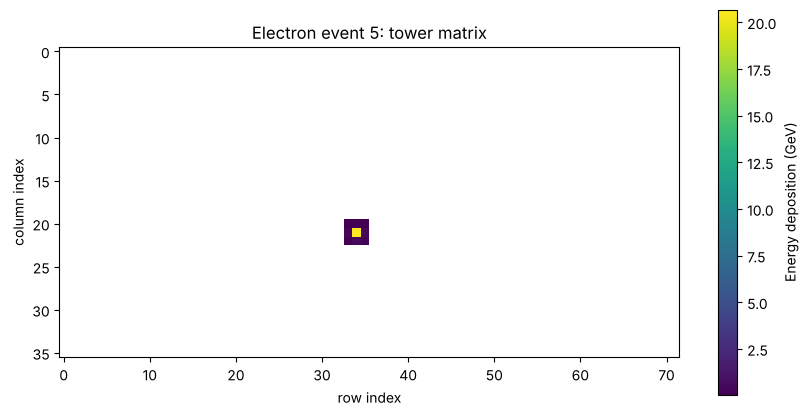

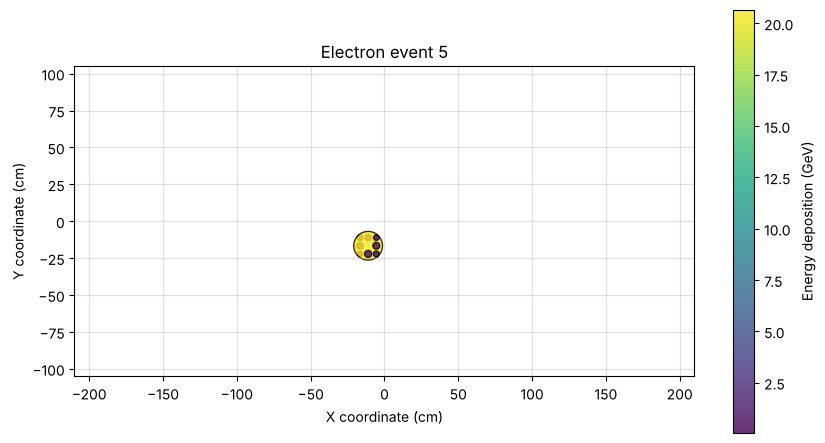

In [7]:
elmID, edep = ex3.get_hit_data('electron', 5)
edep = edep / ex3.sfc

# Plot without the conversion into spatial coordinates
mapped_matrix = map_channels_energies_to_matrix(elmID, edep)
plot_simple_energy_matrix(mapped_matrix, title='Electron event 5: tower matrix')

# Plot with the conversion into spatial coordinates
coordinates = channel_to_spatial_coordinates(elmID)
plot_spatial_energy_matrix(coordinates, edep, title='Electron event 5')

<div class="alert alert-info">
<strong>Exercise:</strong>
- What is the measured energy of the particle in event 5 of the electron sample?<br>
- What is the distribution of the measured energies of all events of the electron sample (and of the dielectron sample)?<br>
<strong>Hint</strong>: use <code>ex3.get_hit_data(sample, event)</code> in a loop.
</div>

Measured energy of electron event 5: 22.58 GeV
electron [ 6.9 40.3 43.7 34.9 72.  22.6 33.7 77.4 13.8 37.9]
dielectron [48.7 15.2 81.1 12.5 13.1 24.6 29.7 27.6 13.6 16.2]


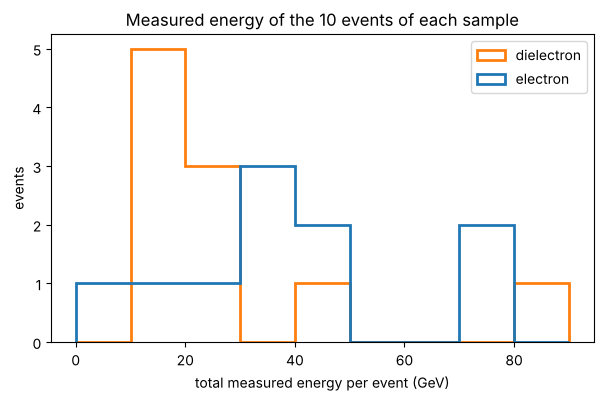

In [8]:
# --> enter your code

print(f'Measured energy of electron event 5: {np.sum(edep):.2f} GeV')

total_energy = {}
for sample in ['electron', 'dielectron']:
    total_energy[sample] = [np.sum(ex3.get_hit_data(sample, i)[1] / ex3.sfc) for i in range(10)]
    print(sample, np.round(total_energy[sample], 1))

plt.figure(figsize=(7, 4))
plt.hist(list(total_energy.values()), bins=np.linspace(0, 90, 10), label=list(total_energy.keys()), histtype='step', lw=2)
plt.xlabel('total measured energy per event (GeV)')
plt.ylabel('events')
plt.title('Measured energy of the 10 events of each sample')
plt.legend()
plt.show()

<a name='section_2_2'></a>
<hr style="height: 1px;">


<h3 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Problem 2.2: Cluster properties and moments</h3>

After having measured the energy deposited by all the hits of a cluster, we want to characterise the cluster and determine its properties. We use the moments of a distribution to do this.

For a calorimeter cluster, the relevant distribution is the **distribution of the deposited energy** over the face of the calorimeter, not the distribution of the hit towers: every hit must be weighted with its energy $E_i$. A tower with 20 GeV and a tower with 50 MeV should not count the same.

With weights $w_i = E_i$ and the weighted average $\langle f \rangle = \sum_i w_i f(x_i) / \sum_i w_i$, the moments of the $x$ (or $y$) distribution are:
- $\textbf{1st order (raw)}$:
    $$
    \text{Mean (energy-weighted centroid): } \mu = \langle x \rangle
    $$
- $\textbf{2nd order (central)}$:
    $$
    \text{Variance: } \sigma^2 = \langle (x - \mu)^2 \rangle, \qquad \text{width } \sigma
    $$
- $\textbf{3rd order (standardized)}$:
    $$
    \text{Skewness: }\gamma = \left\langle \left( \frac{x - \mu}{\sigma} \right)^3 \right\rangle
    $$
- $\textbf{4th order (standardized)}$:
    $$
    \text{Kurtosis: } g = \left\langle \left( \frac{x - \mu}{\sigma} \right)^4 \right\rangle
    $$

With all weights equal to one, these are the usual (unweighted) moments of the hit positions.

<div class="alert alert-info">
<strong>Exercise:</strong>
Using <i>numpy</i>, implement functions to calculate the mean, width ($\sigma$), standardized skewness and standardized kurtosis of the EMCal clusters. Each function takes the coordinates and optional <code>weights</code> (hint: <code>np.average</code> accepts weights).
</div>

In [9]:
# --> enter your code to complete the following functions

def f_mean(data, weights=None):
    return np.average(data, weights=weights)


def f_variance(data, weights=None):
    return np.average((data - f_mean(data, weights)) ** 2, weights=weights)


def f_width(data, weights=None):
    return np.sqrt(f_variance(data, weights))


def f_skewness(data, weights=None):
    mean, width = f_mean(data, weights), f_width(data, weights)
    return np.average(((data - mean) / width) ** 3, weights=weights)


def f_kurtosis(data, weights=None):
    mean, width = f_mean(data, weights), f_width(data, weights)
    return np.average(((data - mean) / width) ** 4, weights=weights)

<div class="alert alert-info">
<strong>Exercise:</strong>
Visualize some events from the electron sample and calculate the moments, once without and once with energy weights. Which moments look useful for identifying electrons, and why?
</div>

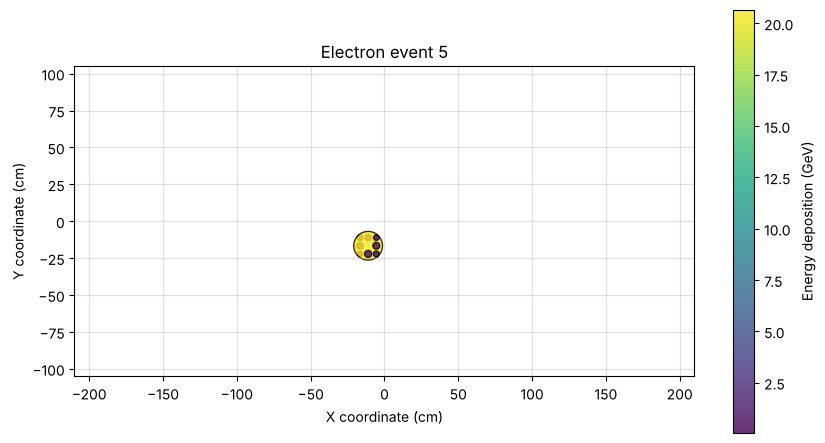

electron event 5  (9 hits, 22.6 GeV)
  unweighted     : mean = ( -11.07,  -16.61) cm | width = ( 4.52,  4.52) cm | skewness = ( 0.00,  0.00) | kurtosis = ( 1.50,  1.50)
  energy-weighted: mean = ( -11.01,  -16.73) cm | width = ( 1.26,  1.22) cm | skewness = ( 0.71, -1.85) | kurtosis = (19.08, 20.06)
electron event 2  (13 hits, 43.7 GeV)
  unweighted     : mean = ( -21.71,  -11.50) cm | width = (55.84,  5.52) cm | skewness = (-1.89,  0.15) | kurtosis = ( 4.64,  2.89)
  energy-weighted: mean = (  -5.75,  -11.13) cm | width = (31.55,  1.27) cm | skewness = (-4.45, -1.17) | kurtosis = (20.92, 31.94)
electron event 8  (8 hits, 13.8 GeV)
  unweighted     : mean = (  -6.23,  -11.76) cm | width = ( 4.32,  4.32) cm | skewness = ( 0.22,  0.22) | kurtosis = ( 1.67,  1.67)
  energy-weighted: mean = (  -5.73,  -11.10) cm | width = ( 1.43,  1.03) cm | skewness = (-1.65, -0.68) | kurtosis = (14.23, 28.83)


In [10]:
def print_moments(coordinates, energies, label=''):
    x, y = coordinates[:, 0], coordinates[:, 1]
    print(f'{label}  ({len(x)} hits, {np.sum(energies):.1f} GeV)')
    for name, w in [('unweighted     ', None), ('energy-weighted', energies)]:
        print(f'  {name}: mean = ({f_mean(x, w):7.2f}, {f_mean(y, w):7.2f}) cm | width = ({f_width(x, w):5.2f}, {f_width(y, w):5.2f}) cm'
              f' | skewness = ({f_skewness(x, w):5.2f}, {f_skewness(y, w):5.2f}) | kurtosis = ({f_kurtosis(x, w):5.2f}, {f_kurtosis(y, w):5.2f})')


for i in [5, 2, 8]:
    elmID, edep = ex3.get_hit_data('electron', i)
    edep = edep / ex3.sfc
    coordinates = channel_to_spatial_coordinates(elmID)
    if i == 5:
        plot_spatial_energy_matrix(coordinates, edep, title='Electron event 5')
    print_moments(coordinates, edep, label=f'electron event {i}')

<div class="alert alert-success">

*--> (put your text here)*

- **Unweighted moments** describe the pattern of towers above threshold, not the shower. For event 5 the nine hit towers form a 3×3 block, so the unweighted skewness is exactly 0 and the kurtosis exactly 1.5 (the moments of three equally spaced points), whatever the shower looks like.
- **Mean (weighted):** the energy-weighted centroid estimates the impact point, much better than the centre of the tower pattern (Problem 4.1 quantifies this).
- **Width (weighted):** the lateral size of the shower, about 1&ndash;3 cm. EM showers are compact (of order the Molière radius); hadronic showers are much wider. This is the most useful variable for identifying electrons and photons.
- **Skewness (weighted):** asymmetry of the deposit. For a single EM shower it reflects mainly where the particle hit the central tower; a bremsstrahlung photon displaced by the magnetic field would make it large.
- **Kurtosis (weighted):** how peaked the deposit is. A narrow core with a little energy in the tails gives a large value, typical of EM showers; broad hadronic or merged clusters give smaller values.

Note electron event 2: its weighted width in $x$ is about 30 cm, because it contains a second, displaced deposit (like event 0 below). The moments are only meaningful once the hits are grouped into clusters.
</div>

<div class="alert alert-info">
<strong>Exercise:</strong>
Standardization means rescaling data so that it has a mean of 0 and a standard deviation of 1.<br><br>
Implement functions to calculate skewness and kurtosis without "standardization" and compute them for a few events. Why do we usually use the standardized versions?
</div>

In [11]:
# --> enter your code to complete the following functions

def f_skewness_raw(data, weights=None):
    return np.average((data - f_mean(data, weights)) ** 3, weights=weights)


def f_kurtosis_raw(data, weights=None):
    return np.average((data - f_mean(data, weights)) ** 4, weights=weights)


for i in [5, 2, 8]:
    elmID, edep = ex3.get_hit_data('electron', i)
    edep = edep / ex3.sfc
    x = channel_to_spatial_coordinates(elmID)[:, 0]
    print(f'electron event {i} (x, energy-weighted): skewness = {f_skewness(x, edep):6.2f} (raw {f_skewness_raw(x, edep):9.2f} cm^3)'
          f' | kurtosis = {f_kurtosis(x, edep):6.2f} (raw {f_kurtosis_raw(x, edep):10.2f} cm^4)')

electron event 5 (x, energy-weighted): skewness =   0.71 (raw      1.43 cm^3) | kurtosis =  19.08 (raw      48.68 cm^4)
electron event 2 (x, energy-weighted): skewness =  -4.45 (raw -139690.36 cm^3) | kurtosis =  20.92 (raw 20732291.36 cm^4)
electron event 8 (x, energy-weighted): skewness =  -1.65 (raw     -4.83 cm^3) | kurtosis =  14.23 (raw      59.57 cm^4)


<div class="alert alert-success">

*--> (put your text here)*

The raw moments have units (cm$^3$, cm$^4$) and scale with the size of the shower ($\sigma^3$, $\sigma^4$). Their values mix "how wide" with "what shape" and cannot be compared between clusters or with a reference.
The standardized moments are dimensionless and describe only the shape. For a Gaussian, the skewness is 0 and the kurtosis 3, which gives an immediate reference point.
</div>

<div class="alert alert-info">
<strong>Exercise:</strong>
Visualize event 0 from the electron sample and event 6 from the dielectron sample and compute the moments. Do they still provide a good description in these cases? Why?
</div>

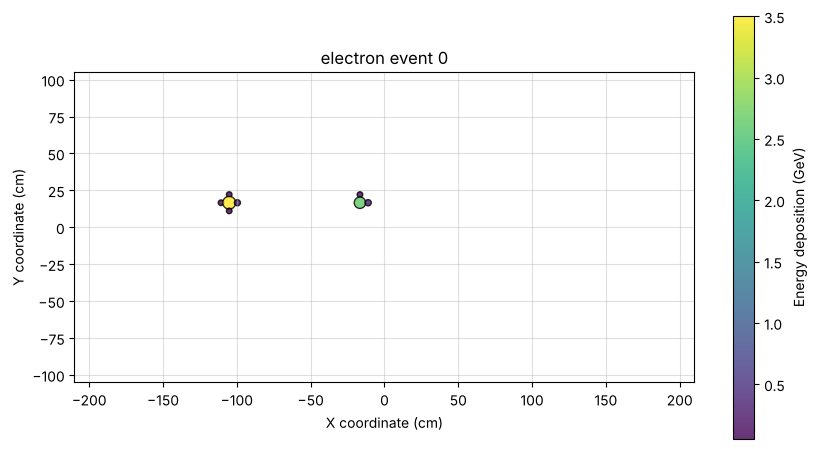

electron event 0  (8 hits, 6.9 GeV)
  unweighted     : mean = ( -71.26,   17.30) cm | width = (43.88,  3.32) cm | skewness = ( 0.51, -0.05) | kurtosis = ( 1.28,  2.69)
  energy-weighted: mean = ( -66.53,   16.68) cm | width = (44.05,  0.94) cm | skewness = ( 0.27,  2.51) | kurtosis = ( 1.08, 34.26)


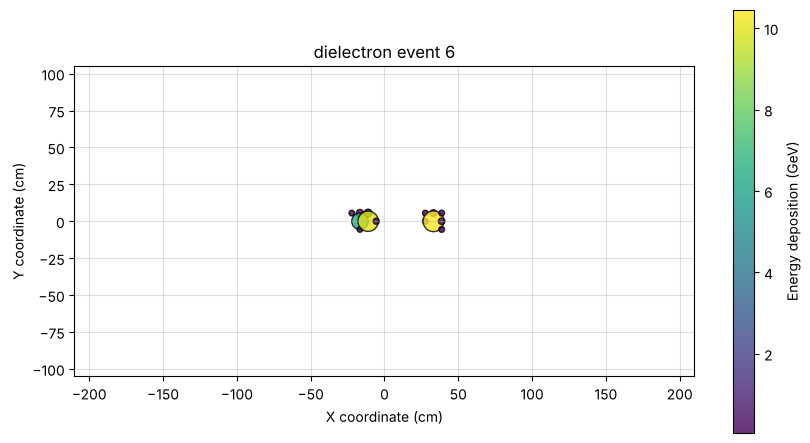

dielectron event 6  (14 hits, 29.7 GeV)
  unweighted     : mean = (   9.88,    1.58) cm | width = (24.59,  3.87) cm | skewness = (-0.01, -0.46) | kurtosis = ( 1.14,  2.10)
  energy-weighted: mean = (   5.02,    0.36) cm | width = (22.87,  1.51) cm | skewness = ( 0.42,  2.48) | kurtosis = ( 1.23, 11.56)


In [12]:
for sample, i in [('electron', 0), ('dielectron', 6)]:
    elmID, edep = ex3.get_hit_data(sample, i)
    edep = edep / ex3.sfc
    coordinates = channel_to_spatial_coordinates(elmID)
    plot_spatial_energy_matrix(coordinates, edep, title=f'{sample} event {i}')
    print_moments(coordinates, edep, label=f'{sample} event {i}')

<div class="alert alert-success">

*--> (put your text here)*

Moments summarise *one* distribution. With two separated deposits, the mean lies between them (where there is no energy at all), and the width measures their separation rather than the size of a shower. Skewness and kurtosis become meaningless.
Even the "single electron" event 0 has two clusters at the same $y$, about 90 cm apart in $x$: most likely the electron radiated a bremsstrahlung photon before reaching the calorimeter and was then deflected by the magnetic field.
We first need to group the hits into clusters (Section 3) and then compute the moments per cluster.
</div>

<a name='section_3_0'></a>
<hr style="height: 1px;">


<h1 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Section 3: Calorimetry and clustering</h1>

Due to the complex patterns of particle interactions, EMCal readouts can become dense and chaotic.
In these situations, clustering algorithms are essential to group hits that originate from a single particle, 
helping to reconstruct particle flows or analyze jets.

The $K$-means algorithm is a popular unsupervised machine learning technique used to partition data into $K$ distinct clusters based on feature similarity. 

- $\textbf{Initialize centroids}$: Randomly select $K$ hits; these hits will be the starting, $K$, centroids

- $\textbf{Assign clusters}$: Assign hits to the nearest centroid, forming $K$ clusters

- $\textbf{Update centroids and reassign hits}$: Calculate the centroid (mean of the coordinates) of each cluster; check if a hit in a cluster is closer to another centroid; if so, reallocate the hits to the closest cluster.

- $\textbf{Iterate}$: Repeat step 3 until no more hits change cluster (or until a certain tolerance).

- $\textbf{Output}$: The final centroids represent the centers of the $K$ clusters, and each hit is assigned to the cluster of its nearest centroid.

<a name='section_3_1'></a>
<hr style="height: 1px;">


<h3 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Problem 3.1: A homemade K-means clustering algorithm</h3>

For events with several particles, we perform clustering to group the hits associated with the different particles.

To test the clustering algorithms and check that they are implemented correctly, you can use the following function to randomly generate a number of clusters with a given number of points. It places the cluster centres uniformly over the face of the EMCal and draws Gaussian points around them:

```python
points = ex3.generate_2d_points()   # default: 3 clusters of 20 points with a spread of 4 cm
points = ex3.generate_2d_points(num_clusters=4, points_per_cluster=30, spread=2.0, random_seed=1)
```

<div class="alert alert-info">
<strong>Exercise:</strong>
Generate some points with the default settings (without passing arguments) and also with some custom settings, and visualize the generated datasets.
</div>

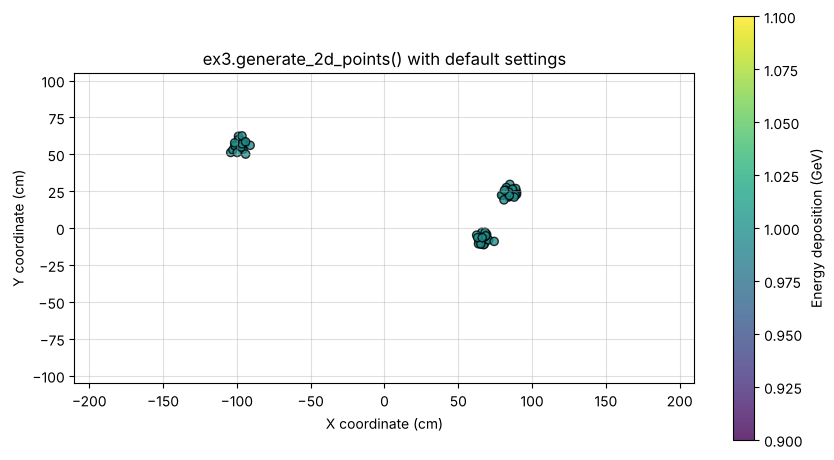

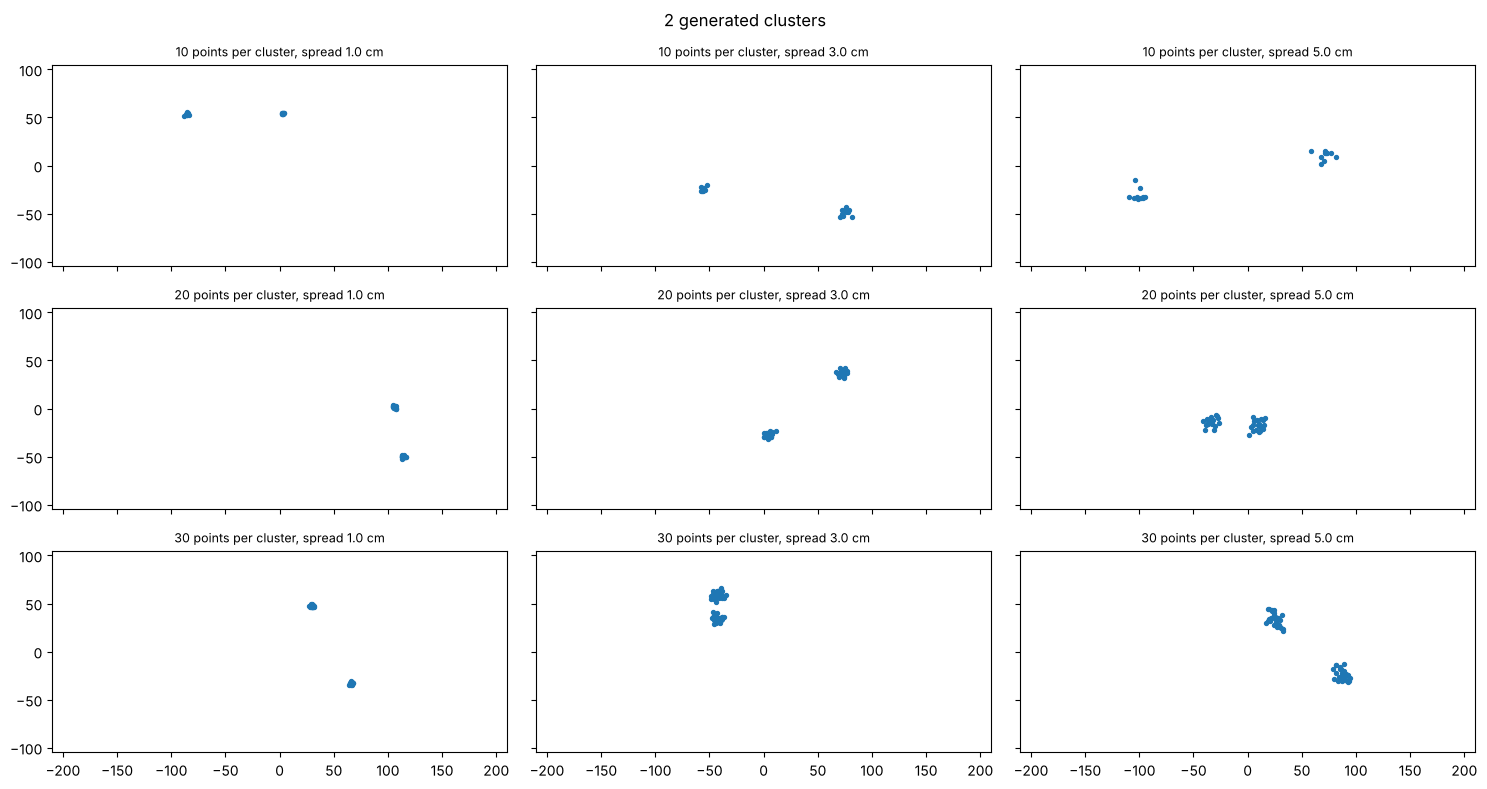

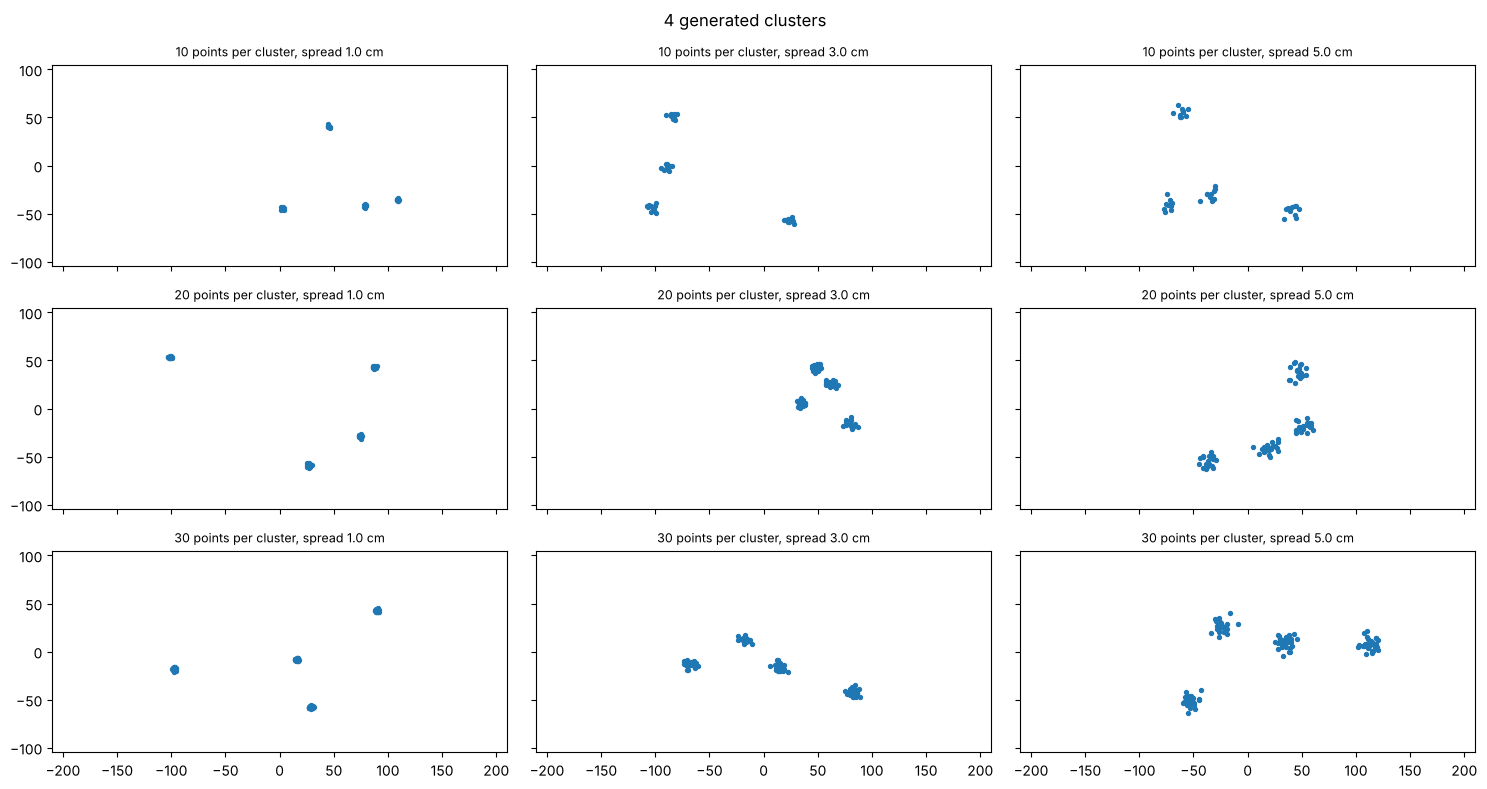

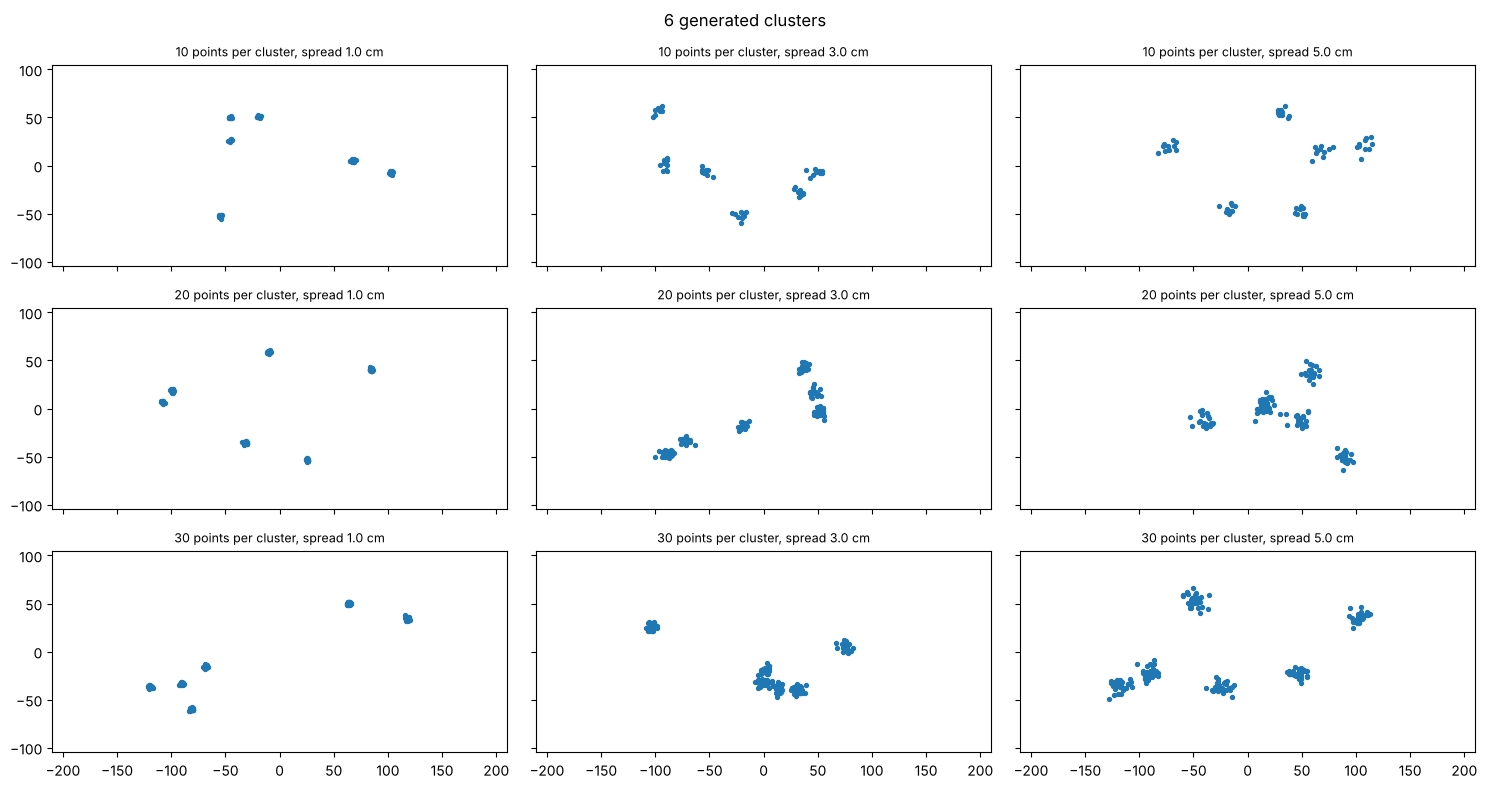

In [13]:
points = ex3.generate_2d_points()
plot_spatial_energy_matrix(points, np.ones(len(points)), title='ex3.generate_2d_points() with default settings')

i = 0
for n in [2, 4, 6]:
    fig, axes = plt.subplots(3, 3, figsize=(15, 8), sharex=True, sharey=True)
    for a, p in enumerate([10, 20, 30]):
        for b, s in enumerate([1., 3., 5.]):
            i += 1
            pts = ex3.generate_2d_points(num_clusters=n, points_per_cluster=p, spread=s, random_seed=i)
            axes[a, b].scatter(pts[:, 0], pts[:, 1], s=8)
            axes[a, b].set_title(f'{p} points per cluster, spread {s} cm', fontsize=9)
            axes[a, b].set_xlim(-210, 210)
            axes[a, b].set_ylim(-105, 105)
    fig.suptitle(f'{n} generated clusters')
    plt.tight_layout()
    plt.show()

<div class="alert alert-info" role="alert">

<h3>🧩 Exercise: K-Means Clustering</h3>

<hr>

<h4>What is Cluster Analysis?</h4>

<p>
Cluster analysis is the process of <strong>grouping together similar points into clusters</strong>.
A <em>point</em> can have 2, 3, or even hundreds of dimensions — meaning it’s a vector in some space.
</p>

<p>
In this exercise, a point is the position of a calorimeter hit, and a cluster is the group of hits produced by one particle.
The same method is used in many other fields, for example to group pixels of an image or customers with similar behaviour.
</p>

<hr>

<h4>Distances Between Points</h4>

<p>
To cluster data, we must measure <strong>how close or far</strong> points are from each other.
The <strong>Euclidean distance</strong> is the most common measure.
</p>

<p>For two 2D points:</p>
\[
d(p, q) = \sqrt{(p_x - q_x)^2 + (p_y - q_y)^2}
\]

<p>For two 3D points:</p>
\[
d(p, q) = \sqrt{(p_x - q_x)^2 + (p_y - q_y)^2 + (p_z - q_z)^2}
\]

<p>In general, for two \(n\)-dimensional points
\(p = (p_1, p_2, \dots, p_n)\) and \(q = (q_1, q_2, \dots, q_n)\):</p>
\[
d(p, q) = \sqrt{(p_1 - q_1)^2 + (p_2 - q_2)^2 + \cdots + (p_n - q_n)^2}
\]

<p><strong>Example:</strong></p>
\[
p = (0.1, 0.2, 0.3, 0.4), \quad q = (0.0, 0.2, 0.3, 0.2)
\]
\[
d(p, q) = \sqrt{(0.1-0.0)^2 + (0.2-0.2)^2 + (0.3-0.3)^2 + (0.4-0.2)^2} = 0.7071\ldots
\]

<hr>

<h4>Cluster Centroids</h4>

<p>
The <strong>centroid</strong> of a cluster is its <em>center of mass</em> — the <strong>average position</strong> of all points in that cluster.
Even though it’s the mean of all cluster points, the centroid does <em>not</em> need to be one of those points.
</p>

<p>To compute a centroid:</p>
\[
\text{centroid} = \frac{1}{N} \sum_{i=1}^{N} p_i
\]

<p>Vector operations:</p>
\[
p + q = (p_1 + q_1,\, p_2 + q_2,\, \dots,\, p_n + q_n)
\]
\[
\frac{p}{a} = \left(\frac{p_1}{a},\, \frac{p_2}{a},\, \dots,\, \frac{p_n}{a}\right)
\]

<hr>

<h4>The K-Means Algorithm</h4>

<p>
The <strong>idea</strong> behind K-Means is simple:
each point belongs to the cluster whose centroid (mean) it is <strong>closest</strong> to.
Because centroids depend on which points are assigned to them, and assignments depend on centroids, we solve this <em>chicken-and-egg</em> problem iteratively.
</p>

<h5>Step 1. Pick \(k\) Centroids</h5>

<p>
We start by choosing \(k\), the number of clusters we want.
Each centroid \(m_j\) is an \(n\)-dimensional point:
</p>
\[
m_j = (m_{j,1}, m_{j,2}, \dots, m_{j,n})
\]
<p>
We randomly select \(k\) points from the dataset as our <strong>initial centroids</strong>
(the <em>Forgy method</em>, <code>init="random"</code>).
A better choice is <strong>k-means++</strong> (<code>init="k-means++"</code>): the first centroid is a random point, and every further centroid is drawn with a probability proportional to the squared distance to the nearest centroid already chosen, which spreads the initial centroids out.
</p>

<h5>Step 2. Partition the Dataset</h5>

<p>
Assign each point to the <strong>nearest centroid</strong> by Euclidean distance.
If a point is equally close to multiple centroids, break ties arbitrarily.
This produces \(k\) sets \(S_1, S_2, \dots, S_k\),
where each \(S_j\) contains all points closest to centroid \(m_j\).
</p>

<h5>Step 3. Recompute the Means</h5>

<p>For each cluster \(S_j\), recompute its centroid:</p>
\[
m_j = \frac{1}{|S_j|} \sum_{q \in S_j} q
\]
<p>
Since centroids have changed, some points may now be closer to a different centroid —
so we repeat the assignment step.
</p>

<h5>Step 4. Repeat Until Convergence</h5>

<ul>
  <li>The centroids stop moving, or</li>
  <li>The assignments no longer change.</li>
</ul>

<p>
Sometimes convergence takes many iterations, so we often set a
<strong>maximum iteration limit</strong> to prevent infinite loops.
</p>

<hr>

<h4>Summary of the K-Means Algorithm</h4>

<ol>
  <li>Choose \(k\) and initialize centroids randomly.</li>
  <li>Assign each point to the nearest centroid.</li>
  <li>Recompute each centroid as the mean of its assigned points.</li>
  <li>Repeat steps 2–3 until centroids stop changing or max iterations reached.</li>
</ol>

<hr>

<p><strong>✅ Key Idea:</strong>  
K-Means minimizes the <em>within-cluster sum of squared errors</em> (inertia) —  
the total squared distance between points and their assigned centroids.</p>

</div>


<div class="alert alert-info">
<strong>Exercise:</strong>
Fill the missing parts in the following class to implement the k-means algorithm, with both initialisation schemes (<code>"random"</code> and <code>"k-means++"</code>).
</div>

In [14]:
import numpy as np


class KMeans:
    """
    Minimal NumPy-only K-Means with functionized steps.

    Parameters
    ----------
    n_clusters : int
        Number of clusters (K).
    init : {"k-means++", "random"}
        Initialization scheme.
    max_iter : int
        Maximum iterations.
    tol : float
        Convergence tolerance on centroid shift (Euclidean norm).
    random_state : int or None
        Seed of the NumPy random generator, for reproducibility.
    """

    def __init__(self, n_clusters, init="k-means++", max_iter=300, tol=1e-4, random_state=None):
        self.n_clusters   = int(n_clusters)
        self.init         = init
        self.max_iter     = int(max_iter)
        self.tol          = float(tol)
        self.random_state = random_state

        # Attributes set after fitting
        self.cluster_centers_ = None
        self.labels_          = None
        self.inertia_         = None
        self.n_iter_          = None

    # ---------- core primitives ----------

    def _euclidean_squared(self, a, b):
        """Squared Euclidean distances between rows of a (n, d) and rows of b (k, d) -> (n, k)."""
        a2 = np.sum(a * a, axis=1, keepdims=True)
        b2 = np.sum(b * b, axis=1)
        ab = a @ b.T
        return np.maximum(a2 - 2.0 * ab + b2, 0.0)

    def _kmeanspp_init(self, X, rng):
        """k-means++ initialization. Returns (K, d) array of initial centroids."""
        n_samples, n_features = X.shape
        centroids = np.empty((self.n_clusters, n_features), dtype=float)
        centroids[0] = X[rng.integers(0, n_samples)]
        closest_dist_sq = self._euclidean_squared(X, centroids[0:1]).ravel()
        for i in range(1, self.n_clusters):
            if closest_dist_sq.sum() > 0:
                idx = rng.choice(n_samples, p=closest_dist_sq / closest_dist_sq.sum())
            else:   # all points coincide with chosen centroids
                idx = rng.integers(0, n_samples)
            centroids[i] = X[idx]
            closest_dist_sq = np.minimum(closest_dist_sq, self._euclidean_squared(X, centroids[i:i + 1]).ravel())
        return centroids

    # ---------- step-by-step methods ----------

    def _initialize_centroids(self, X, rng):
        """Random (Forgy) initialization: K distinct samples of X."""
        indices = rng.choice(X.shape[0], size=self.n_clusters, replace=False)
        return X[indices].copy()

    def _assign(self, X, centroids):
        """Assignment step: return (labels, d2)."""
        d2 = self._euclidean_squared(X, centroids)
        return np.argmin(d2, axis=1), d2

    def _update(self, X, labels, rng):
        """Update step: new centroids as cluster means; re-seed empty clusters to a random point."""
        K, d = self.n_clusters, X.shape[1]
        new_centroids = np.empty((K, d), dtype=float)
        for j in range(K):
            mask = labels == j
            new_centroids[j] = X[mask].mean(axis=0) if np.any(mask) else X[rng.integers(0, X.shape[0])]
        return new_centroids

    def _converged(self, old_centroids, new_centroids, old_labels, new_labels):
        """Convergence: labels unchanged OR total centroid shift < tol."""
        if old_labels is not None and np.array_equal(old_labels, new_labels):
            return True
        shift = float(np.sqrt(np.sum((new_centroids - old_centroids) ** 2)))
        return shift < self.tol

    def _compute_inertia(self, X, labels, centroids):
        """Inertia (within-cluster sum of squared distances)."""
        return float(np.sum((X - centroids[labels]) ** 2))

    # ---------- public API ----------

    def fit(self, X):
        """Run K-Means on X."""
        X = np.asarray(X, dtype=float)
        rng = np.random.default_rng(self.random_state)

        if self.init == "k-means++":
            centroids = self._kmeanspp_init(X, rng)
        elif self.init == "random":
            centroids = self._initialize_centroids(X, rng)
        else:
            raise ValueError('init must be "k-means++" or "random"')
        labels = None

        for it in range(1, self.max_iter + 1):
            new_labels, _ = self._assign(X, centroids)
            new_centroids = self._update(X, new_labels, rng)
            done = self._converged(centroids, new_centroids, labels, new_labels)
            centroids, labels = new_centroids, new_labels
            if done:
                break
        labels, _ = self._assign(X, centroids)   # labels consistent with the final centroids

        self.cluster_centers_ = centroids
        self.labels_ = labels
        self.inertia_ = self._compute_inertia(X, labels, centroids)
        self.n_iter_ = it
        return self

    def predict(self, X):
        """Assign cluster indices for new samples using the fitted centroids."""
        if self.cluster_centers_ is None:
            raise RuntimeError("Model is not fitted. Call .fit(X) first.")
        labels, _ = self._assign(np.asarray(X, dtype=float), self.cluster_centers_)
        return labels

    def fit_predict(self, X):
        """Convenience: fit the model and return labels for X."""
        self.fit(X)
        return self.labels_

<div class="alert alert-info">
<strong>Unit test 1:</strong>
Use the cell below to evaluate the inertia and the number of iterations of the K-Means you have implemented, and compare with the scikit-learn implementation.
</div>

In [15]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans as SKKMeans
from sklearn.metrics import adjusted_rand_score

# ---- Load Iris dataset ----
iris = load_iris()
X = iris.data
y_true = iris.target

# ---- Your implementation ----
my_km = KMeans(n_clusters=3, init="k-means++", max_iter=300, tol=1e-4, random_state=42)
my_labels = my_km.fit_predict(X)

print("=== Your KMeans ===")
print(f"Iterations: {my_km.n_iter_}")
print(f"Inertia:    {my_km.inertia_:.4f}")
print(f"ARI vs true labels: {adjusted_rand_score(y_true, my_labels):.4f}")

# ---- scikit-learn implementation (same seed, but a different random stream: small differences are expected) ----
sk_km = SKKMeans(n_clusters=3, init="k-means++", n_init=1, max_iter=300, tol=1e-4,
                 algorithm="lloyd", random_state=42)
sk_labels = sk_km.fit_predict(X)

print("\n=== scikit-learn KMeans ===")
print(f"Iterations: {sk_km.n_iter_}")
print(f"Inertia:    {sk_km.inertia_:.4f}")
print(f"ARI vs true labels: {adjusted_rand_score(y_true, sk_labels):.4f}")

=== Your KMeans ===
Iterations: 3
Inertia:    78.8557
ARI vs true labels: 0.7163

=== scikit-learn KMeans ===
Iterations: 11
Inertia:    78.8557
ARI vs true labels: 0.7163


<div class="alert alert-info">
<strong>Unit test 2:</strong>
Run the external unit tests and check that your K-Means passes all of them.
</div>

In [16]:
%run -i ../../tests/exercise03/unit_test.py

Running KMeans standalone tests...
  ✓ test_basic_shapes_and_types
  ✓ test_determinism_with_seed
  ✓ test_predict_matches_training_assignment
  ✓ test_inertia_definition
  ✓ test_kmeanspp_init
All tests passed!


<a name='section_3_2'></a>
<hr style="height: 1px;">


<h3 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Problem 3.2: Finding optimal number of centroids</h3>

$K$-means is an efficient method that works well with large datasets, making it ideal for quickly organizing data into clusters based on similarity.
However, one limitation is that the number of clusters, $K$, must be predetermined, which can be challenging without prior knowledge of the data structure.
To address this, techniques such as the Elbow and the Silhouette methods are often used to find the optimal number of clusters, helping to ensure that the chosen $K$ best captures the natural groupings within the data.
In any case, for a given event, one must run the $K$-means algorithm multiple times, scanning different values of $K$ and identifying the optimal value of $K$.

$\textbf{Elbow method}$

The Elbow Method helps find the optimal number of clusters \( K \) by computing the within-cluster sum of squares (WCSS$_K$):
$$
    \text{WCSS}_K = \sum_{i=1}^{K} \sum_{x \in C_i} \| x - \mu_i \|^2
$$
where $K$ is the number of clusters, $C_i$ is the $i$-th cluster, $x$ is a hit in the cluster, $\mu_i$ is the centroid of the cluster $C_i$, and $\| x - \mu_i \|^2$ is the squared Euclidean distance between the hit and the centroid.
If you plot WCSS$_K$ as a function of $K$, you will notice that as \( K \) increases, WCSS$_K$ decreases.
The "elbow" point, where the decrease slows down "sharply", indicates the optimal \( K \).

To determine the elbow point more precisely, you can:
calculate the second derivative of WCSS with respect to \( K \) and identify the point with the largest change, indicating the most significant slowdown in the rate of decrease;
use algorithms such as the "Kneedle" algorithm, which automatically detects the "knee" or "elbow" in the curve by analyzing the curvature.

$\textbf{Silhouette method}$

The Silhouette method evaluates the quality of clustering by calculating a "silhouette score" for each hit, based on how similar it is to hits in its own cluster compared to hits in the nearest other cluster. For a given number of clusters \( K \), the average silhouette score $S$ ranges from -1 to 1: $S$ near 1 indicates well-clustered hits, close to their own cluster and far from others; $S$ near 0 indicates the presence of hits on the boundary between clusters (overlapping clusters); a negative $S$ indicates that many hits are assigned to the wrong cluster.

To determine the optimal \( K \), calculate the average silhouette score for different \( K \) values and choose the \( K \) that maximizes this score, indicating the best-defined clusters.
Here is a method to calculate the silhouette score $S$:

- Compute the intra-cluster distance $a_i$: for each hit $i$ in a cluster, compute the average Euclidean distance to all other points within the same cluster.
- Compute the nearest cluster distance $b_i$: for each hit $i$ in a cluster, compute the average euclidean distance to all points of another cluster; repeat for all clusters and take the smallest average distance computed.
- Compute silhouette hit score $s_i$: for each hit $i$ in a cluster, compute
    $$
    s_i = \frac{b_i - a_i}{\max(a_i, b_i)}
    $$
    and repeat it for all hits in the event.
- Calculate the average silhouette score $S$ of the event, i.e. the average of $s_i$ over all hits in the event.

<div class="alert alert-info">
<strong>Exercise:</strong>
Implement an elbow method for your K-means algorithm and test it on the generated datasets.
</div>

===== 2 generated clusters =====


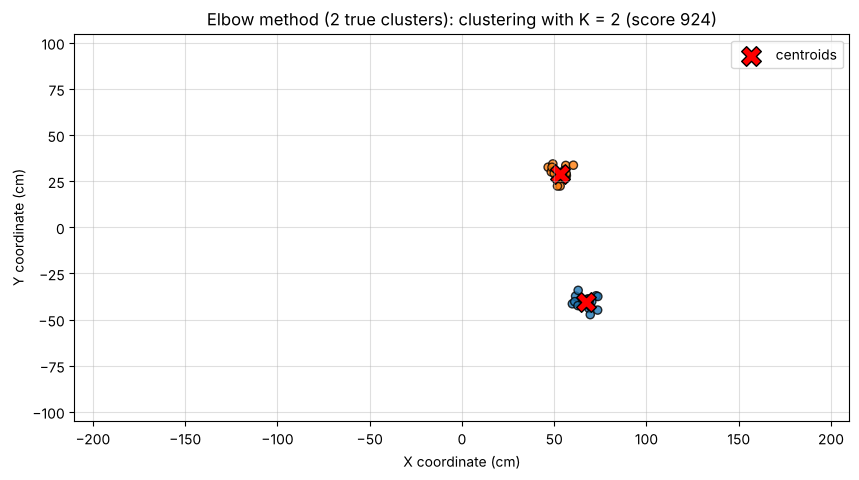

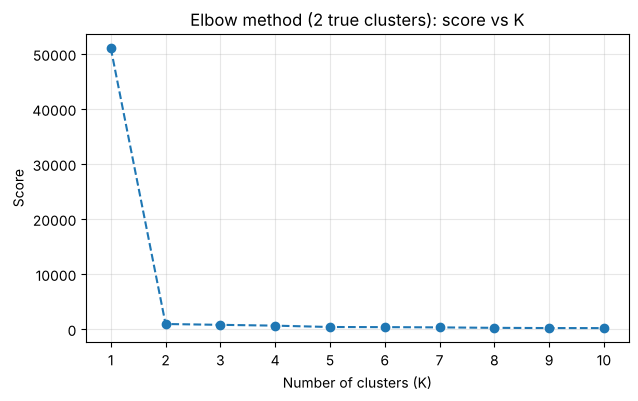

===== 4 generated clusters =====


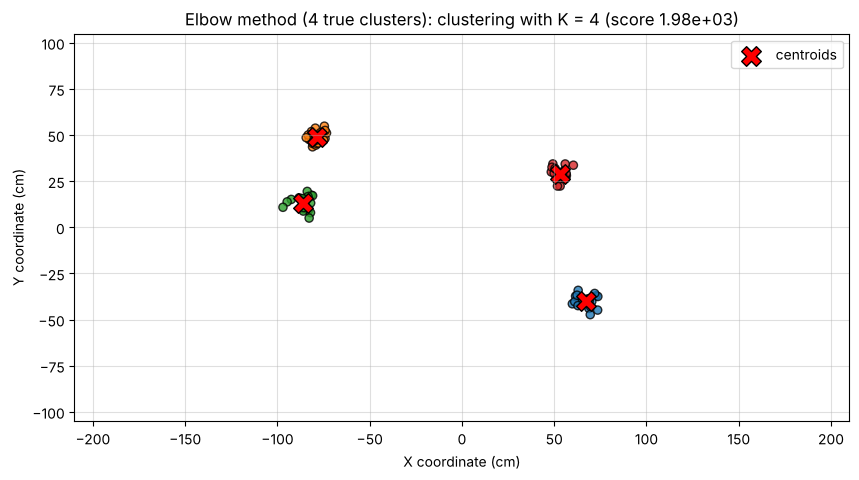

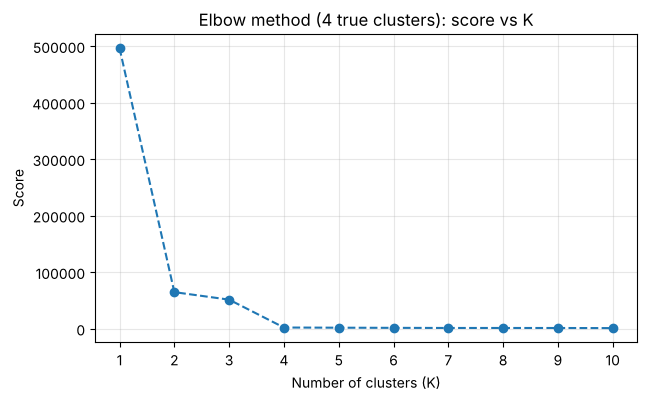

===== 6 generated clusters =====


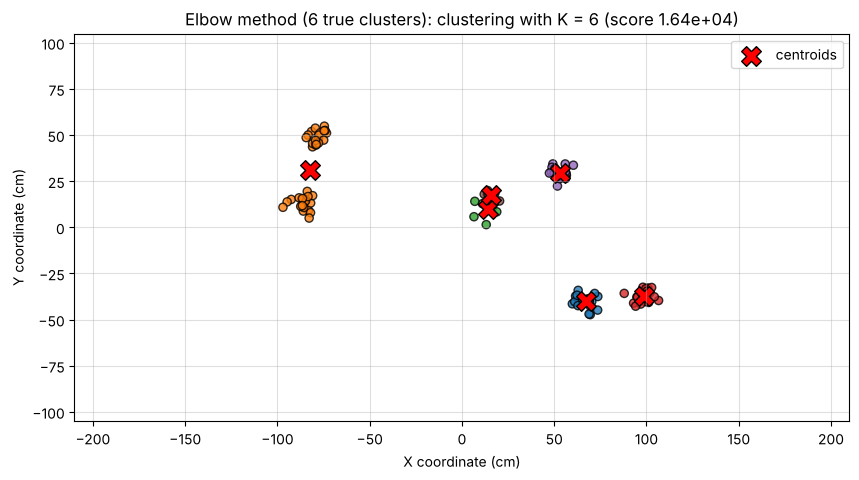

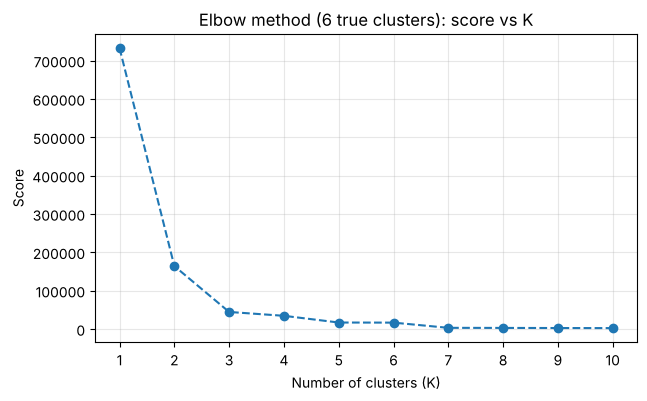

In [17]:
def evaluate_method(data, score_method, title_label, min_k=1, max_k=10, random_state=42, plot_k=None):
    """Score K = min_k..max_k with score_method(data, centroids, labels); plot the clustering for one K and the score vs K."""
    score_values = []
    plot_k = min_k if plot_k is None else plot_k
    for k in range(min_k, max_k + 1):
        kmeans = KMeans(n_clusters=k, init="k-means++", max_iter=300, tol=1e-4, random_state=random_state).fit(data)
        score = score_method(data, kmeans.cluster_centers_, kmeans.labels_)
        score_values.append(score)
        if k == plot_k:
            plot_spatial_energy_matrix(data, np.ones(len(data)), centroids=kmeans.cluster_centers_, labels=kmeans.labels_,
                                       title=f'{title_label}: clustering with K = {k} (score {score:.3g})')

    plt.figure(figsize=(7, 4))
    plt.plot(range(min_k, max_k + 1), score_values, marker='o', linestyle='--')
    plt.title(f"{title_label}: score vs K")
    plt.xticks(range(min_k, max_k + 1))
    plt.xlabel("Number of clusters (K)")
    plt.ylabel("Score")
    plt.grid(alpha=0.3)
    plt.show()
    return score_values


def wcss_score(data, centroids, labels):
    """Within-cluster sum of squares given centroids & labels."""
    wcss = 0.0
    for i in range(len(centroids)):
        cluster_points = data[labels == i]
        wcss += np.sum((cluster_points - centroids[i]) ** 2)
    return wcss


for n in [2, 4, 6]:
    print(f'===== {n} generated clusters =====')
    coordinates = ex3.generate_2d_points(num_clusters=n, points_per_cluster=20, spread=4.0, random_seed=999)
    evaluate_method(coordinates, wcss_score, f'Elbow method ({n} true clusters)', min_k=1, max_k=10, plot_k=n)

<div class="alert alert-info">
<strong>Exercise:</strong>
Implement a silhouette method for your K-means algorithm and test it on the generated datasets.
</div>

===== 2 generated clusters =====


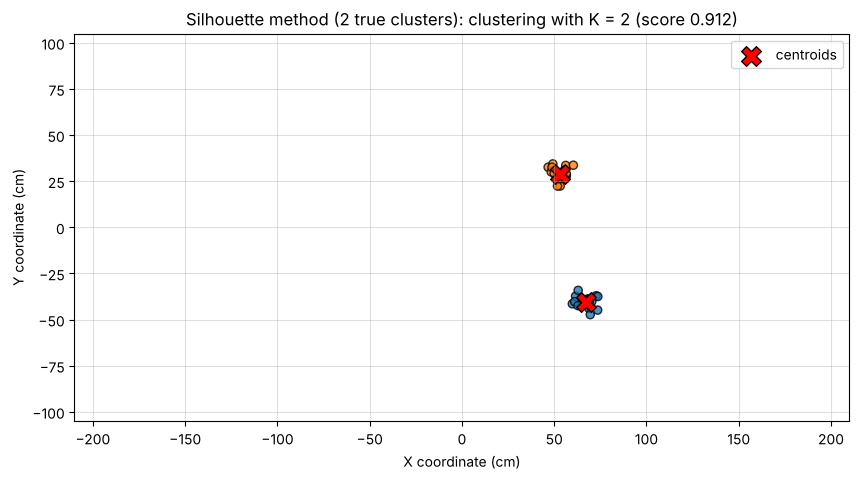

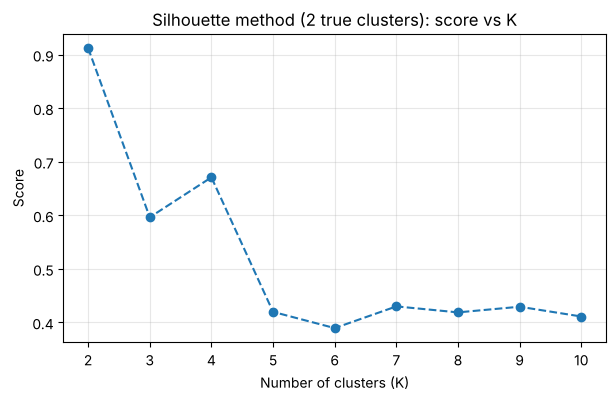

===== 4 generated clusters =====


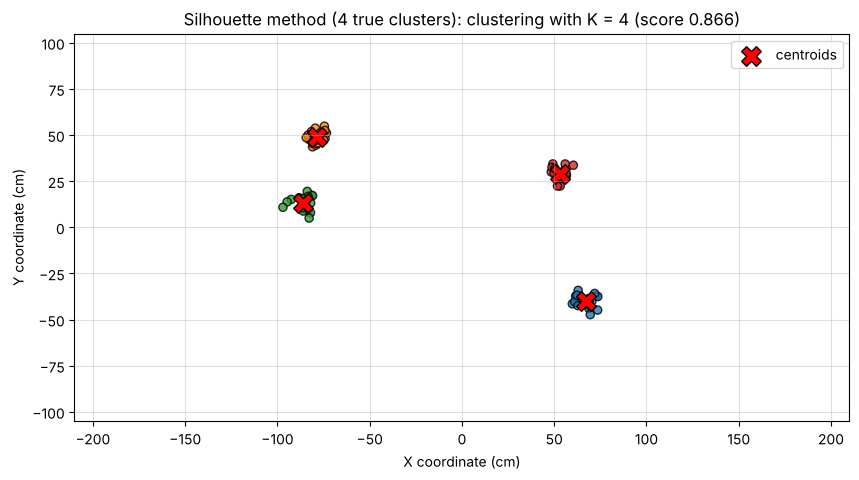

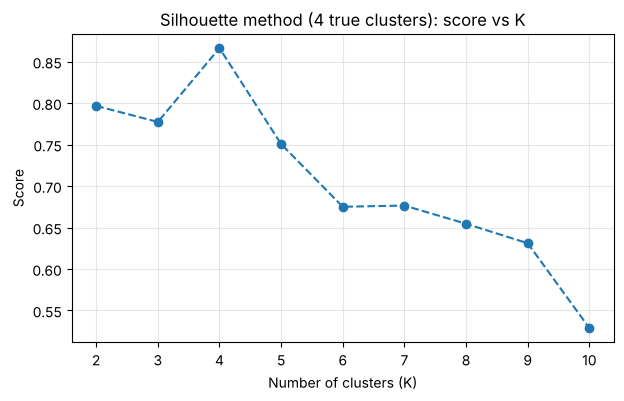

===== 6 generated clusters =====


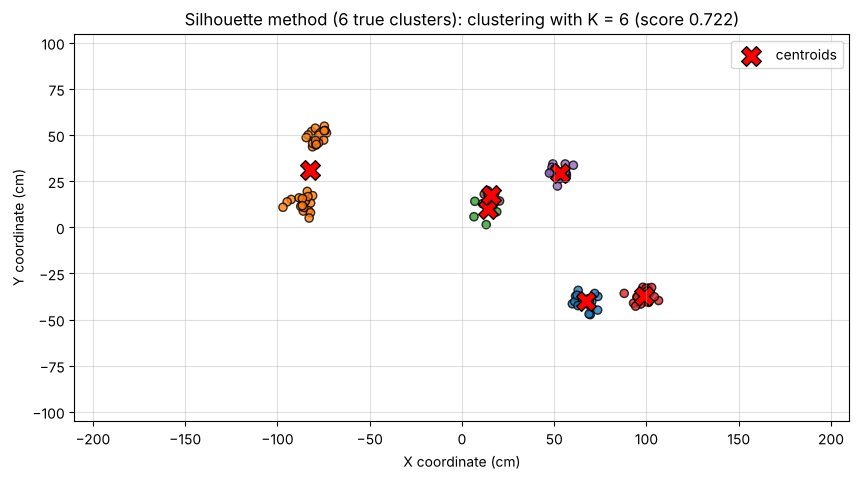

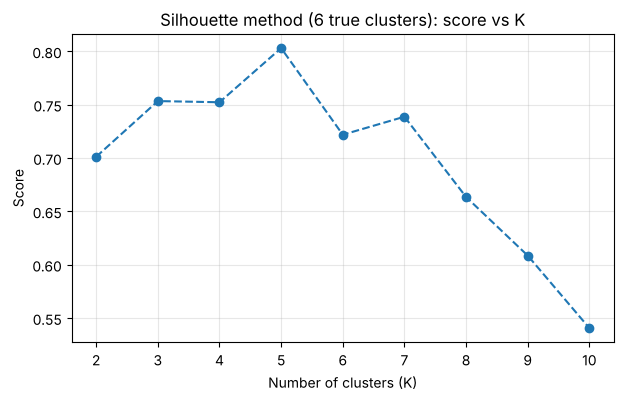

In [18]:
def silhouette_score(data, centroids, labels):
    """
    Compute the mean silhouette score given:
    - data: (N, d)
    - centroids: (K, d)  (not strictly needed but kept for API compatibility)
    - labels: (N,) with integer labels in [0, K-1]

    Returns: scalar mean silhouette score in [-1, 1].
    """
    data = np.asarray(data)
    labels = np.asarray(labels)
    n_samples = data.shape[0]
    k = len(centroids)

    total_score = 0.0

    for i in range(n_samples):
        point = data[i]
        point_label = labels[i]

        same_cluster_mask = (labels == point_label)
        same_cluster_points = data[same_cluster_mask]

        intra_distances = np.linalg.norm(same_cluster_points - point, axis=1)

        if intra_distances.size > 1:
            a_i = intra_distances.sum() / (intra_distances.size - 1)
        else:
            a_i = 0.0

        b_i = float("inf")
        for j in range(k):
            if j == point_label:
                continue  # skip own cluster

            other_cluster_points = data[labels == j]
            if other_cluster_points.size == 0:
                continue  # skip empty clusters, just in case

            inter_distances = np.linalg.norm(other_cluster_points - point, axis=1)
            mean_inter = inter_distances.mean()
            if mean_inter < b_i:
                b_i = mean_inter

        if b_i == float("inf"):
            s_i = 0.0
        else:
            denom = max(a_i, b_i)
            s_i = 0.0 if denom == 0 else (b_i - a_i) / denom

        total_score += s_i

    return total_score / n_samples


for n in [2, 4, 6]:
    print(f'===== {n} generated clusters =====')
    coordinates = ex3.generate_2d_points(num_clusters=n, points_per_cluster=20, spread=4.0, random_seed=999)
    evaluate_method(coordinates, silhouette_score, f'Silhouette method ({n} true clusters)', min_k=2, max_k=10, plot_k=n)


<div class="alert alert-info">
<strong>Exercise:</strong>
Apply both methods to the hits of dielectron event 6. Which $K$ do they suggest, and does it agree with what you see?
</div>

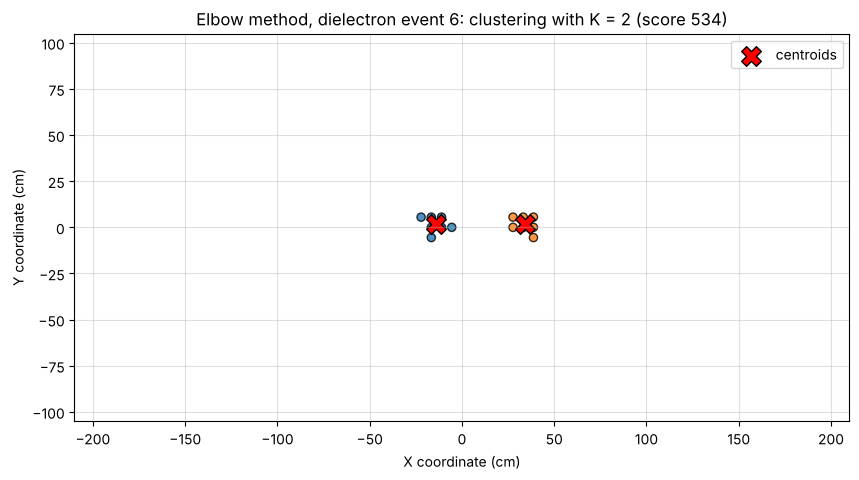

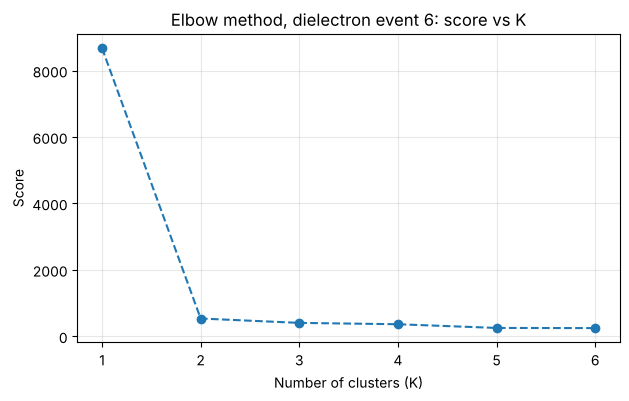

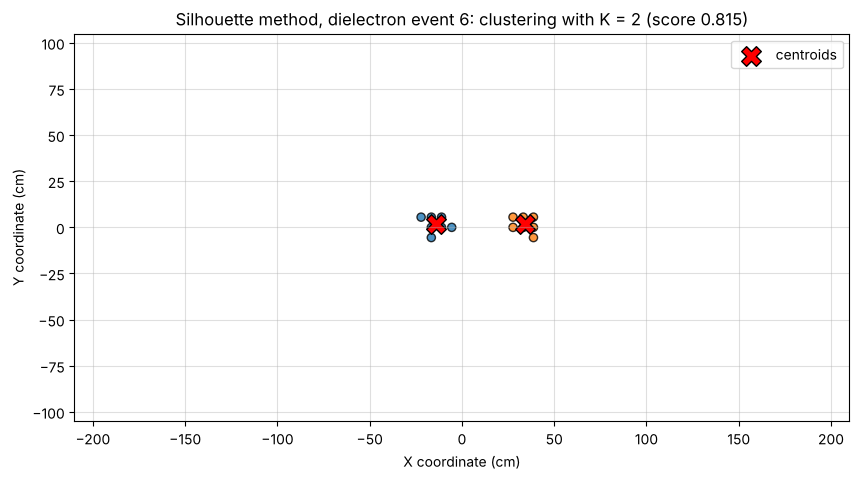

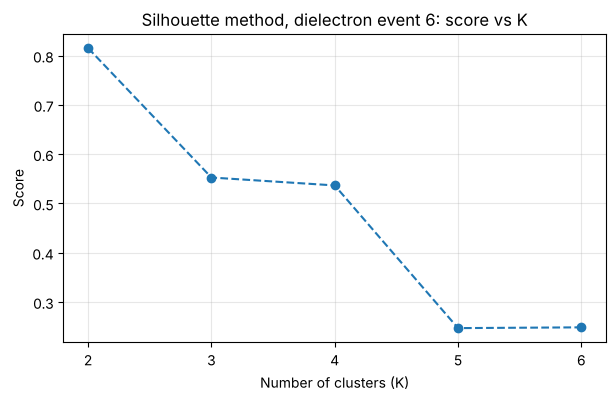

[np.float64(0.8153790262038042),
 np.float64(0.5526941147883605),
 np.float64(0.5366452819031854),
 np.float64(0.24699699892430194),
 np.float64(0.24855292986980188)]

In [19]:
elmID, edep = ex3.get_hit_data('dielectron', 6)
hits = channel_to_spatial_coordinates(elmID)
evaluate_method(hits, wcss_score, 'Elbow method, dielectron event 6', min_k=1, max_k=6, plot_k=2)
evaluate_method(hits, silhouette_score, 'Silhouette method, dielectron event 6', min_k=2, max_k=6, plot_k=2)

<div class="alert alert-success">

*--> (put your text here)*

- **Elbow:** for well-separated clusters the WCSS drops steeply up to the true $K$ and then flattens (clear for 2 and 4 clusters). The scan must start at $K=1$, otherwise an elbow at $K=2$ can never be seen. With 6 clusters, two of which are close, the curve is irregular. A single $k$-means++ start can end in a poor local minimum (one centroid sitting between two clusters), so the WCSS is not monotonic in quality, and the "elbow" is a matter of taste. Running several initialisations per $K$ and keeping the best one helps.
- **Silhouette:** it gives a single number to maximise and finds 2 and 4 correctly. For 6 clusters it prefers 5, because merging the two closest clusters costs little separation.
- **Dielectron event 6:** both methods favour $K=2$ (silhouette 0.82 at $K=2$, falling quickly; the elbow is weaker). Both methods ignore the energies: a low-energy tail hit counts as much as the 10 GeV seed tower, and every $K$ is fitted from scratch. Using the energy deposits directly, i.e. searching for energy seeds, is the physics-driven alternative of the next problem.
</div>

<div class="alert alert-info">
<strong>Exercise:</strong>
Compare the computational complexity of the elbow and silhouette methods, and give your reasoning.
</div>

<div class="alert alert-success">

*--> (put your text here)*

<h4> On the Computational Complexity of <em>Elbow</em> vs <em>Silhouette</em> Methods</h4>

<p>Let:</p>

<ul>
  <li>\( n \) — number of points</li>
  <li>\( d \) — dimensionality</li>
  <li>\( k \) — clusters</li>
  <li>\( I \) — K-Means iterations until convergence</li>
  <li>\( K_{\max} \) — maximum number of clusters you scan in your model selection loop</li>
</ul>

<hr>

<h5>A) Elbow Method (WCSS / Inertia)</h5>

<ol>
  <li>Run K-Means once per \(k\):  
      Cost \( \approx \mathcal{O}(n \cdot k \cdot I \cdot d) \) (standard Lloyd’s algorithm).</li>
  <li>Compute WCSS / inertia: obtained during the same pass; extra \( \mathcal{O}(n \cdot d) \).</li>
</ol>

<p>
Per \(k\):  
\[
\boxed{\mathcal{O}(n \cdot k \cdot I \cdot d)}
\]
Scan \(k = 2..K_{\max}\):  
\[
\boxed{\mathcal{O}(K_{\max} \cdot n \cdot k \cdot I \cdot d)}
\]
Memory: \( \mathcal{O}(n \cdot d) \)
</p>

<hr>

<h5>B) Silhouette Method</h5>

<p>
You still need to run K-Means per \(k\):  
\( \mathcal{O}(n \cdot k \cdot I \cdot d) \)
</p>

<p>Then compute silhouette:</p>

<ul>
  <li><strong>Naïve per-point:</strong> for each point, distances to all others  
      \( \Rightarrow \mathcal{O}(n^2 \cdot d) \)</li>
  <li><strong>Precompute distance matrix (per \(k\)):</strong>  
      \( \mathcal{O}(n^2 \cdot d) \) time and \( \mathcal{O}(n^2) \) memory,  
      then reuse to get \(a_i, b_i\) in \( \mathcal{O}(n) \).</li>
</ul>

<p>
Per \(k\) (naïve or precomputed):  
\[
\boxed{\mathcal{O}(n \cdot k \cdot I \cdot d) \;+\; \mathcal{O}(n^2 \cdot d)}
\]
Scan \(k = 2..K_{\max}\):  
\[
\boxed{\mathcal{O}\!\left(K_{\max} \cdot n \cdot k \cdot I \cdot d \;+\; K_{\max} \cdot n^2 \cdot d\right)}
\]
Memory (with precompute): \( \mathcal{O}(n^2) \)
</p>
</div>

$\textbf{Energy seeding}$

Now let's change our approach in the determination of \(K\) from the perspective of physics.
The EMCal readouts provide not only the hit position information, but also the energy deposition measured for each hit.
On top of that, we know that a particle typically deposits large part of its energy in one channel, with only small fractions leaking to the neighboring channels due to the lateral spread of the shower. We can exploit this knowledge to design an algorithm tailored to our physics case.

"Energy seeds" in calorimetry refer to localized points in the detector where the energy deposition is significantly higher than the surrounding areas. These seeds act as initial markers for clustering algorithms, helping to identify and group hits that are likely to belong to the same cluster. By starting with these high-energy regions, energy seed-based clustering improves accuracy in reconstructing particle trajectories and separating overlapping showers.

<div style="text-align: center;">
  <img src="figures/padding.png" width="40%">
  <figcaption style="margin-top: 6px; font-size: 90%;"> Seed search on a 15 × 15 example grid: red towers are seeds (local maxima above threshold), light blue shows their ±1 window, and the yellow border of empty towers is an alternative to clipping the window at the edges of the detector. </figcaption>
</div>

Here is an idea for a seed-searching algorithm:
- Fill the energies into the $72 \times 36$ tower matrix (e.g. with `map_channels_energies_to_matrix`; note that it returns the **transposed** matrix of shape $36 \times 72$, so keep track of which index is the row and which the column).
- Apply a minimum-energy threshold to select seed candidates: only a tower above the threshold can be a seed.
- For every candidate, look at the window of $\pm$`padding_size` towers around it (clipped at the edges of the detector). If any tower in the window has a higher energy than the candidate, the candidate is not a local maximum: discard it.
- Return the channel IDs (`elmID`) of the surviving seeds.

The seeds give the number of clusters $K$ and can be used as the starting centroids of the $K$-means algorithm (see Section 4).

<div class="alert alert-info">
<strong>Exercise:</strong>
Implement a seed-searching algorithm and test it on a few events of the dielectron sample.

Which parameters of the algorithm can you tune to improve its performance?
</div>

In [20]:
def seed_search(channels, energies, min_energy_threshold=1.0, padding_size=1, n_rows=72, n_columns=36):
    """Channel IDs of the local energy maxima above min_energy_threshold (GeV); None if there are none."""
    # Step 1: map energies to the 2D energy matrix (transposed: shape (n_columns, n_rows))
    energy_matrix = map_channels_energies_to_matrix(channels, energies, n_rows, n_columns)

    # Step 2: seed candidates above threshold
    candidates = np.argwhere(energy_matrix > min_energy_threshold)

    # Step 3: keep only local maxima within the padding window
    valid_seeds = []
    for x, y in candidates:            # x runs over n_columns, y over n_rows (transposed matrix)
        energy = energy_matrix[x, y]
        region = energy_matrix[max(0, x - padding_size):min(n_columns, x + padding_size + 1),
                               max(0, y - padding_size):min(n_rows, y + padding_size + 1)]
        if np.any(region > energy):
            continue
        valid_seeds.append(y * n_columns + x)   # back to elmID = row * n_columns + column

    return valid_seeds if valid_seeds else None

dielectron event 0: 3 seed(s) at [[-27.7, 11.1], [-11.1, 11.1], [11.1, 11.1]] cm


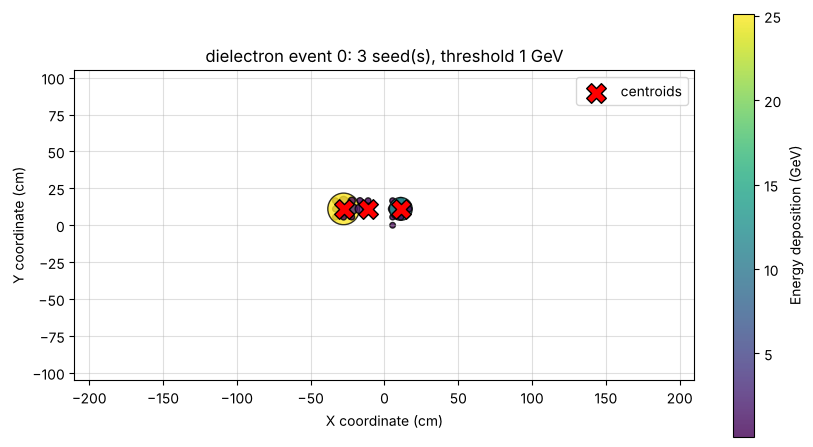

dielectron event 1: 3 seed(s) at [[-99.6, -5.5], [-38.7, -5.5], [44.3, -5.5]] cm


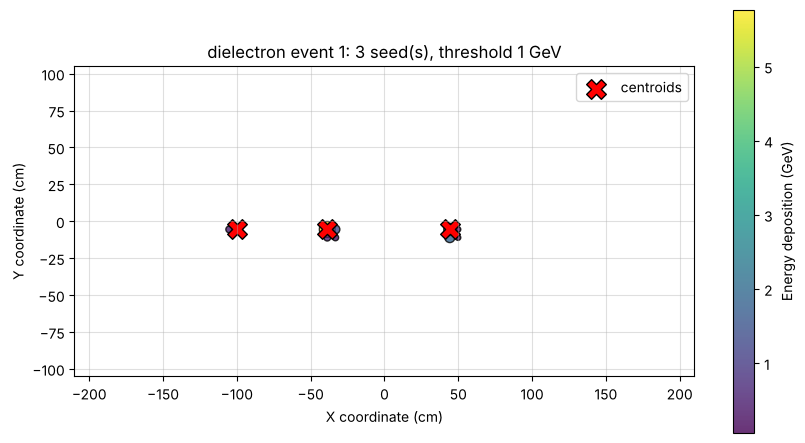

dielectron event 6: 2 seed(s) at [[-11.1, 0.0], [33.2, 0.0]] cm


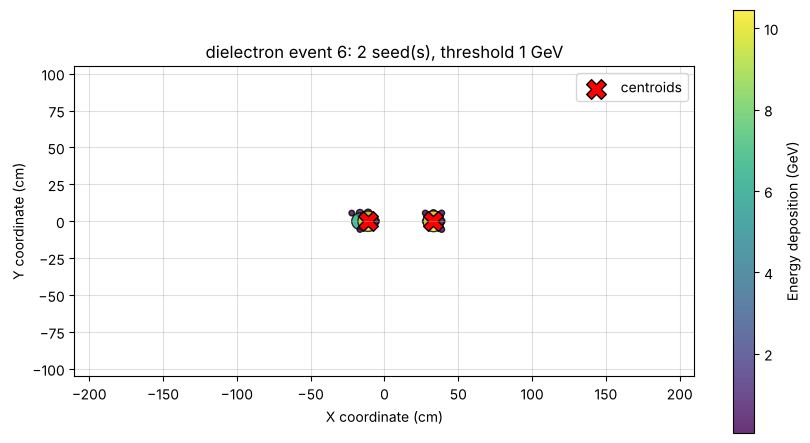

In [21]:
# Check the algorithm on a few events from the dielectron sample
for i in [0, 1, 6]:
    elmID, edep = ex3.get_hit_data('dielectron', i)
    edep = edep / ex3.sfc
    seeds = seed_search(elmID, edep, min_energy_threshold=1.0)
    seeds_xy = channel_to_spatial_coordinates(np.asarray(seeds)) if seeds else None
    n = 0 if seeds is None else len(seeds)
    print(f'dielectron event {i}: {n} seed(s) at {np.round(seeds_xy, 1).tolist() if n else "-"} cm')
    plot_spatial_energy_matrix(channel_to_spatial_coordinates(elmID), edep, centroids=seeds_xy,
                               title=f'dielectron event {i}: {n} seed(s), threshold 1 GeV')

<div class="alert alert-success">

*--> (put your text here)*

With a threshold of 1 GeV and a $3\times3$ window, event 6 gives the two expected seeds. Its 6.3 GeV tower next to the 10 GeV tower is correctly *not* a seed: it is part of the same shower.
Events 0 and 1 give a third seed each (2.4 GeV and 2.0 GeV). These are additional local maxima, most likely bremsstrahlung photons radiated upstream, which are real energy deposits but not separate primary electrons.
Parameters to tune:
- **Energy threshold:** too high and low-energy electrons are lost (the seed tower holds only 30&ndash;90&nbsp;% of the energy, depending on the impact point); too low and noise or shower fluctuations create fake seeds.
- **Window (padding) size:** a larger window suppresses fake maxima inside one shower but cannot resolve two showers closer than the window.
- **Further cuts:** a minimum cluster energy, merging seeds closer than a given distance, or matching seeds to tracks.

The seeds give $K$ and the starting centroids for $K$-means (Section 4).
</div>

<a name='section_4_0'></a>
<hr style="height: 1px;">


<h1 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Section 4: Latent-variable models &mdash; from K-means to EM to VAE</h1>


In Section 3 you clustered hits with $K$-means. In this section we look at the same problem through the lens of
**latent-variable models**, following the lecture *"Variational Autoencoder"* (K. He, MIT 6.S978).
You will see that $K$-means, the Expectation-Maximization (EM) algorithm and the Variational Autoencoder (VAE) are
three ways of maximising **the same objective**.

**The generative story.** A hidden (latent) variable $z$ is drawn from a prior $p(z)$ and a "generator" turns it into
what we observe, $x \sim p_\theta(x\,|\,z)$. In a calorimeter this is literally the physics:

| | latent $z$ | observed $x$ | generator $p_\theta(x\,|\,z)$ |
|---|---|---|---|
| **one hit** in an event | which particle produced the hit | the hit position $(x, y)$ | lateral shower profile around the impact point |
| **one shower** (image) | impact point, energy, shape, ... | the energies of the towers around the seed | the whole EM cascade + detector |

**The Evidence Lower BOund (ELBO).** For *any* distribution $q(z)$,

$$
\log p_\theta(x) \;=\; \underbrace{\mathbb{E}_{q(z)}\!\left[\log p_\theta(x\,|\,z)\right] \;-\; D_\mathrm{KL}\!\left(q(z)\,\|\,p(z)\right)}_{\text{ELBO}(q,\,\theta)} \;+\; \underbrace{D_\mathrm{KL}\!\left(q(z)\,\|\,p_\theta(z\,|\,x)\right)}_{\ge 0}
$$

so the ELBO is a lower bound on the log-likelihood, and it is tight when $q(z)$ equals the true posterior $p_\theta(z\,|\,x)$.
Two sets of unknowns must be optimised: the distribution $q$ and the generator parameters $\theta$.

| method | how $q$ is represented | how the ELBO is maximised | latent $z$ |
|---|---|---|---|
| **$K$-means** | one-hot ("hard") assignment | alternate: assign / update | discrete, $K$ values |
| **EM (Gaussian mixture)** | analytic posterior (soft responsibilities) | alternate: E-step / M-step (coordinate ascent) | discrete, $K$ values |
| **VAE** | a neural network $q_\phi(z\,|\,x)$ (encoder) | stochastic gradient descent on $\theta$ and $\phi$ jointly | continuous |

Plan of this section:
- **4.1** energy-weighted $K$-means (use the energy you have ignored so far!)
- **4.2** $K$-means is a special case of EM: Gaussian mixtures, energy sharing, model selection
- **4.3** $K$-means as an *autoencoder*: a codebook of shower shapes
- **4.4** a Variational Autoencoder for shower shapes, written in plain NumPy

<div class="alert alert-warning">
<strong>Note:</strong> this section uses the functions you wrote before: <code>channel_to_spatial_coordinates</code> (Problem 2.1),
your <code>KMeans</code> class (Problem 3.1) and <code>seed_search</code> (Problem 3.2). Make sure the corresponding cells have been executed.<br>
Only the cells marked <code># --> TODO</code> need your code (four of them). The analysis and plotting cells are provided: run them once your functions work and spend your time on interpreting the plots.
</div>

### A toy EMCal simulation with Monte-Carlo truth

The PHENIX samples contain only 10 events each and no information on *which particle produced which hit*.
To *measure* how good a clustering algorithm is, we need truth information, and for the VAE we need many thousands of showers.
We therefore provide a fast toy simulation in `exercise3_utils`:

- `ex3.generate_shower_event(n_showers, ...)` &rarr; an event in the **same format** as `ex3.process_event` (`elmID`, raw `edep`), plus the truth:
  `true_E`, `true_xy` (impact points in cm, same convention as your `channel_to_spatial_coordinates`) and
  `true_fraction` (for every hit, the fraction of its energy that belongs to each shower).
- `ex3.make_shower_images(n, size=7, kind="single" | "merged" | "mip")` &rarr; a dataset of $7\times 7$ tower windows centred on the seed tower.

Each shower is sampled from a two-component lateral profile $f(r) \propto r R^2/(r^2+R^2)^2$ (a narrow core and a wide tail),
tuned so that, as for the PHENIX electrons, 45&ndash;85&nbsp;% of the energy is in the seed tower (depending on where the particle hits the tower) and about 97&nbsp;% in the $3\times 3$ block.

Keep in mind that this is a toy: the showers are two-dimensional (no longitudinal development), the sampling fluctuations are modelled only roughly, and the noise is the same in every tower. It is good enough to study clustering, not to replace a full simulation (Geant4, Exercise 5).

The cell below defines a few plotting helpers used throughout the section and shows an event with two overlapping showers.

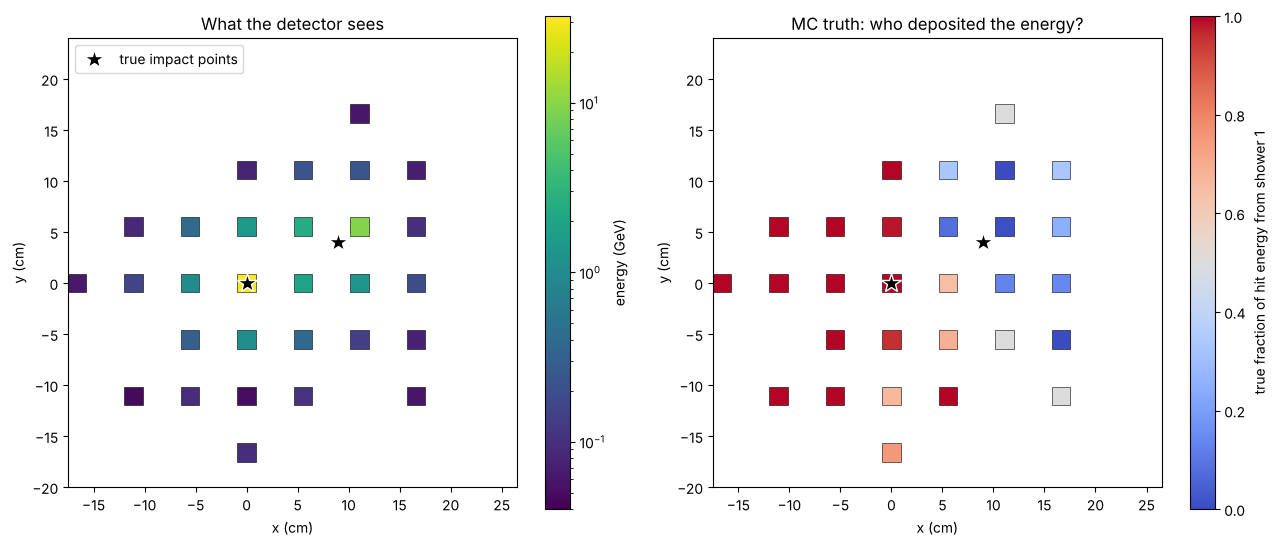

true energies (GeV): [40. 15.]  | measured total: 54.3 GeV


In [22]:
from matplotlib.patches import Ellipse
from matplotlib.colors import LogNorm

CELL = ex3.CELL_SIZE   # 5.535 cm
plt.rcParams['figure.dpi'] = 100


def event_to_xy_gev(event):
    '''(N,2) hit coordinates in cm and (N,) energies in GeV for an event dict.'''
    coords = channel_to_spatial_coordinates(np.asarray(event['elmID']))
    return coords, np.asarray(event['edep'], dtype=float) / ex3.sfc


def draw_towers(ax, coords, energies, c=None, cmap='viridis', vmin=None, vmax=None, norm=None, alpha=1.0, edge='k'):
    '''Draw every hit as a square tower; colour = energy (default) or any per-hit value c.'''
    c = energies if c is None else c
    sc = ax.scatter(coords[:, 0], coords[:, 1], c=c, cmap=cmap, vmin=vmin, vmax=vmax, norm=norm,
                    marker='s', s=180, edgecolor=edge, linewidth=0.4, alpha=alpha)
    ax.set_aspect('equal')
    ax.set_xlabel('x (cm)')
    ax.set_ylabel('y (cm)')
    return sc


def zoom(ax, centre, half_width=25):
    ax.set_xlim(centre[0] - half_width, centre[0] + half_width)
    ax.set_ylim(centre[1] - half_width, centre[1] + half_width)


def draw_cov_ellipse(ax, mean, cov, n_sigma=1.0, **kwargs):
    '''Draw the n-sigma ellipse of a 2D Gaussian.'''
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    w, h = 2 * n_sigma * np.sqrt(vals[::-1])
    ax.add_patch(Ellipse(mean, w, h, angle=angle, fill=False, **kwargs))


# --- an event with two overlapping showers -------------------------------------
demo = ex3.generate_shower_event(2, energies=[40., 15.], positions=[[0., 0.], [9., 4.]], random_seed=7)
coords, E = event_to_xy_gev(demo)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
sc = draw_towers(axes[0], coords, E, norm=LogNorm(vmin=0.04, vmax=E.max()))
plt.colorbar(sc, ax=axes[0], label='energy (GeV)')
axes[0].set_title('What the detector sees')
sc = draw_towers(axes[1], coords, E, c=demo['true_fraction'][:, 0], cmap='coolwarm', vmin=0, vmax=1)
plt.colorbar(sc, ax=axes[1], label='true fraction of hit energy from shower 1')
axes[1].set_title('MC truth: who deposited the energy?')
for ax in axes:
    ax.plot(*demo['true_xy'].T, 'k*', ms=15, mec='w', label='true impact points')
    zoom(ax, demo['true_xy'].mean(0), 22)
axes[0].legend(loc='upper left')
plt.tight_layout()
plt.show()
print('true energies (GeV):', demo['true_E'], ' | measured total:', round(E.sum(), 1), 'GeV')

Before continuing, the next cell checks the two functions from Sections 2 and 3 that this section relies on: the coordinate convention of `channel_to_spatial_coordinates` (Problem 2.1) and `seed_search` (Problem 3.2). If an assertion fails, fix the function first; otherwise the results below will be silently wrong.

In [23]:
test_channels = np.array([36 * 36 + 18, 0, 72 * 36 - 1])        # centre tower, first tower, last tower
expected = np.array([[0.0, 0.0], [-36 * CELL, 18 * CELL], [35 * CELL, -17 * CELL]])
xy = channel_to_spatial_coordinates(test_channels)
assert np.allclose(xy, expected), f'channel_to_spatial_coordinates does not follow the convention of Problem 2.1:\n{xy}\nexpected\n{expected}'

check = ex3.generate_shower_event(2, energies=[30., 20.], positions=[[-50., 0.], [50., 10.]], random_seed=0)
found = seed_search(check['elmID'], check['edep'] / ex3.sfc, min_energy_threshold=1.0) or []
assert len(found) == 2, f'seed_search found {len(found)} seed(s) for two well-separated showers (expected 2): check the window bounds'
print('Coordinate convention and seed finder: OK')

Coordinate convention and seed finder: OK


Notice the purple-ish towers in the right panel: some towers contain energy from **both** showers.
A hard assignment (every hit belongs to exactly one cluster, as in $K$-means) cannot describe this &mdash;
keep this picture in mind for Problem 4.2.

<a name='section_4_1'></a>
<hr style="height: 1px;">


<h3 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Problem 4.1: Energy-weighted K-means</h3>


Your $K$-means minimises $J = \sum_i \lVert x_i - \mu_{k(i)} \rVert^2$, i.e. every hit counts the same, whether it carries 20 GeV or 50 MeV.
Physically, the position of a particle is much better estimated by the **energy-weighted centroid** (the first moment of Problem 2.2, now weighted by energy):

$$
J_w = \sum_i w_i\,\lVert x_i - \mu_{k(i)} \rVert^2, \qquad
\mu_k = \frac{\sum_{i \in C_k} w_i\, x_i}{\sum_{i \in C_k} w_i}, \qquad w_i = E_i .
$$

As initial centroids we use the **seeds** found by your `seed_search` &mdash; this also fixes $K$ (Problem 3.2).

<div class="alert alert-info">
<strong>Exercise:</strong> 
Implement <code>weighted_kmeans(X, w, init_centers)</code>. It should return the final centroids, the labels and the history of the objective $J_w$ (one value per iteration).
Running it with <code>w = np.ones(N)</code> must reproduce ordinary $K$-means started from the same centroids.
</div>

In [24]:
def weighted_kmeans(X, w, init_centers, max_iter=100, tol=1e-6):
    '''K-means with per-point weights w, started from init_centers (K, d).

    Returns (centers (K, d), labels (N,), history of J_w (n_iter,)).
    '''
    X = np.asarray(X, dtype=float)
    w = np.asarray(w, dtype=float)
    centers = np.array(init_centers, dtype=float).copy()
    history = []
    for _ in range(max_iter):
        # assignment step (= hard E-step)
        d2 = np.sum((X[:, None, :] - centers[None, :, :]) ** 2, axis=2)
        labels = np.argmin(d2, axis=1)
        history.append(np.sum(w * d2[np.arange(len(X)), labels]))
        # update step (= M-step): weighted mean of the members
        new_centers = centers.copy()
        for k in range(len(centers)):
            members = labels == k
            if np.any(members) and w[members].sum() > 0:
                new_centers[k] = np.average(X[members], axis=0, weights=w[members])
        converged = np.allclose(new_centers, centers, atol=tol)
        centers = new_centers
        if converged:
            break
    return centers, labels, np.array(history)


def find_seeds_xy(elmID, edep_gev, threshold=1.0, padding=1):
    '''Seed positions (cm) from your seed_search, most energetic first; empty (0, 2) array if none.'''
    seeds = seed_search(np.asarray(elmID), np.asarray(edep_gev), min_energy_threshold=threshold, padding_size=padding)
    if seeds is None:
        return np.empty((0, 2))
    seeds = np.asarray(seeds)
    e_of = dict(zip(np.asarray(elmID).tolist(), np.asarray(edep_gev).tolist()))
    seeds = seeds[np.argsort([-e_of.get(int(ch), 0.0) for ch in seeds])]
    return channel_to_spatial_coordinates(seeds)

<div class="alert alert-info">
<strong>Exercise:</strong> 
Run both versions (unweighted and energy-weighted) on the demo event, starting from the seeds, and compare the centroids with the true impact points.
</div>

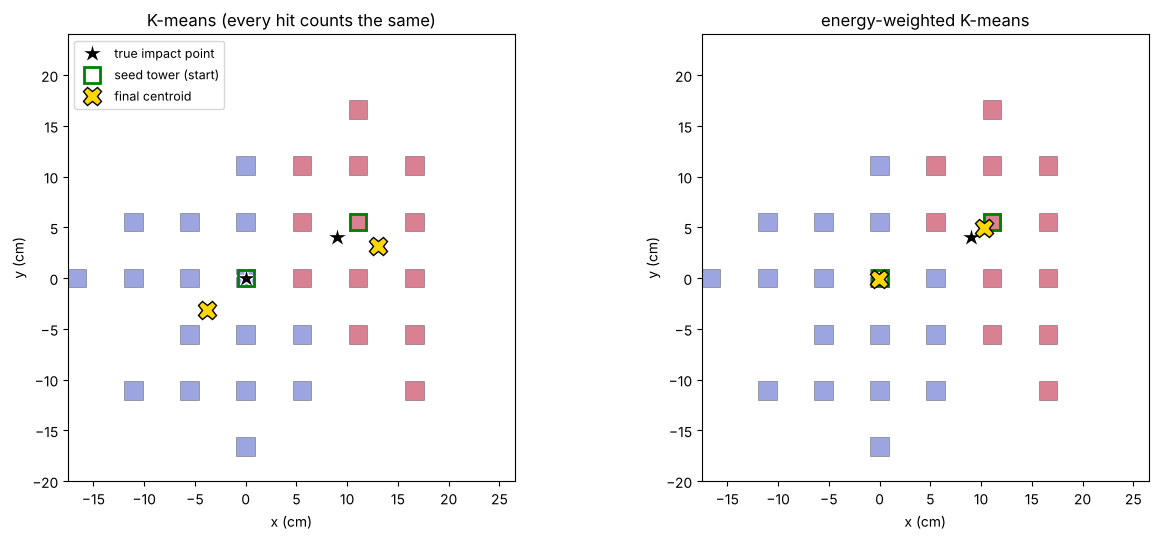

unweighted: distance centroid -> nearest true impact = [4.92 4.13] cm
weighted  : distance centroid -> nearest true impact = [0.07 1.6 ] cm


In [25]:
seeds = find_seeds_xy(demo['elmID'], E)
c_unw, lab_unw, _ = weighted_kmeans(coords, np.ones(len(E)), seeds)
c_w, lab_w, hist_w = weighted_kmeans(coords, E, seeds)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, centers, labels, title in [(axes[0], c_unw, lab_unw, 'K-means (every hit counts the same)'),
                                   (axes[1], c_w, lab_w, 'energy-weighted K-means')]:
    draw_towers(ax, coords, E, c=labels, cmap='coolwarm', alpha=0.5)
    ax.plot(*demo['true_xy'].T, 'k*', ms=16, mec='w', label='true impact point')
    ax.plot(*seeds.T, 's', ms=12, mfc='none', mec='green', mew=2, label='seed tower (start)')
    ax.plot(*centers.T, 'X', ms=13, color='gold', mec='k', label='final centroid')
    zoom(ax, demo['true_xy'].mean(0), 22)
    ax.set_title(title)
axes[0].legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

for name, c in [('unweighted', c_unw), ('weighted  ', c_w)]:
    d = np.linalg.norm(c[:, None] - demo['true_xy'][None], axis=2).min(axis=1)
    print(f'{name}: distance centroid -> nearest true impact = {np.round(d, 2)} cm')

<div class="alert alert-info">
<strong>Exercise:</strong> 
Quantify the effect on 300 toy events with two well-separated showers: histogram the distance between the reconstructed and the true impact point for (i) the centre of the seed tower, (ii) unweighted $K$-means and (iii) energy-weighted $K$-means. Which estimate is best, and why is even the best one limited to roughly a couple of cm?
</div>

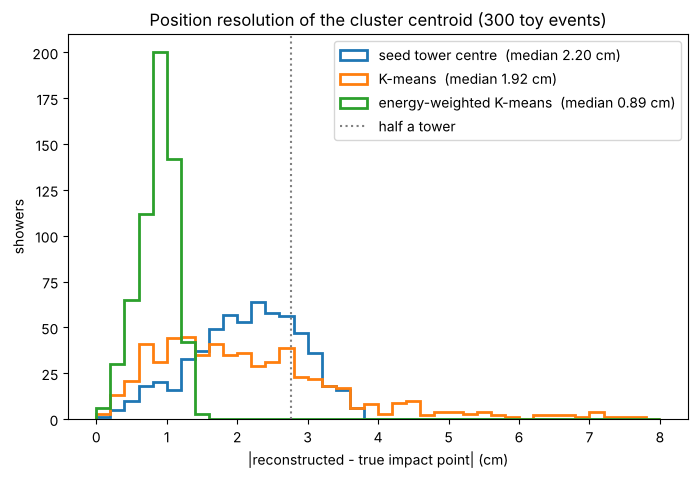

In [26]:
def match_to_truth(centers, true_xy):
    '''For each true particle, the index of the closest reconstructed centre (2 clusters: best permutation).'''
    d = np.linalg.norm(centers[:, None] - true_xy[None], axis=2)  # (n_reco, n_true)
    if d.shape == (2, 2):
        return (0, 1) if d[0, 0] + d[1, 1] <= d[0, 1] + d[1, 0] else (1, 0)
    return tuple(np.argmin(d, axis=0))


residuals = {'seed tower centre': [], 'K-means': [], 'energy-weighted K-means': []}
for s in range(300):
    ev = ex3.generate_shower_event(2, min_separation=20, max_separation=40, random_seed=1000 + s)
    X, Ev = event_to_xy_gev(ev)
    seeds = find_seeds_xy(ev['elmID'], Ev)
    if len(seeds) != 2:
        continue
    for name, centers in [('seed tower centre', seeds),
                          ('K-means', weighted_kmeans(X, np.ones(len(Ev)), seeds)[0]),
                          ('energy-weighted K-means', weighted_kmeans(X, Ev, seeds)[0])]:
        idx = match_to_truth(centers, ev['true_xy'])
        residuals[name] += list(np.linalg.norm(centers[list(idx)] - ev['true_xy'], axis=1))

plt.figure(figsize=(8, 5))
bins = np.linspace(0, 8, 41)
for name, r in residuals.items():
    plt.hist(r, bins=bins, histtype='step', lw=2, label=f'{name}  (median {np.median(r):.2f} cm)')
plt.axvline(CELL / 2, color='gray', ls=':', label='half a tower')
plt.xlabel('|reconstructed - true impact point| (cm)')
plt.ylabel('showers')
plt.title('Position resolution of the cluster centroid (300 toy events)')
plt.legend()
plt.show()

<div class="alert alert-success">

*--> (put your text here)*

- The seed-tower centre is quantised: the error is roughly uniform over a tower (up to $\approx\sqrt{2}\,\cdot$ 2.8 cm).
- Unweighted $K$-means pulls the centroid towards the many low-energy tail hits, which are distributed almost symmetrically around the seed &mdash; it is barely better than the seed position.
- The energy-weighted centroid uses the *sharing* of energy between the seed and its neighbours, and reaches a resolution well below the tower size.
- It is still biased towards the tower centre, because the shower core is narrower than a tower (most energy ends up in one tower whatever the exact impact point is). Real experiments correct for this, e.g. with logarithmic weights $w_i = \max\!\left(0,\, w_0 + \ln(E_i/E_\mathrm{tot})\right)$ or an "S-curve" correction.
</div>

<a name='section_4_2'></a>
<hr style="height: 1px;">


<h3 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Problem 4.2: K-means is a special case of EM &mdash; Gaussian mixtures</h3>


**Gaussian Mixture Model (GMM).** Model the hit positions of an event as coming from $K$ showers, each a 2D Gaussian:

$$
p_\theta(x) = \sum_{k=1}^{K} \pi_k\, \mathcal{N}(x\,|\,\mu_k, \Sigma_k), \qquad \theta = \{\pi_k, \mu_k, \Sigma_k\}.
$$

The latent variable $z_i \in \{1,\dots,K\}$ says which shower produced hit $i$. Every hit enters with a weight $w_i \propto E_i$
(normalised such that $\sum_i w_i = N$), as if a hit with twice the energy were two hits at the same place.

**E-step** (optimise $q$ with $\theta$ fixed) &mdash; the exact posterior, called the *responsibilities*:
$$
r_{ik} \;=\; q(z_i = k) \;=\; \frac{\pi_k\, \mathcal{N}(x_i\,|\,\mu_k,\Sigma_k)}{\sum_j \pi_j\, \mathcal{N}(x_i\,|\,\mu_j,\Sigma_j)}
$$

**M-step** (optimise $\theta$ with $q$ fixed) &mdash; weighted maximum likelihood, with $N_k = \sum_i w_i r_{ik}$:
$$
\pi_k = \frac{N_k}{\sum_i w_i}, \qquad
\mu_k = \frac{1}{N_k}\sum_i w_i r_{ik}\, x_i, \qquad
\Sigma_k = \frac{1}{N_k}\sum_i w_i r_{ik}\,(x_i-\mu_k)(x_i-\mu_k)^\mathsf{T} + \varepsilon\,\mathbb{1}
$$
Where does the $\varepsilon\,\mathbb{1}$ come from? A hit is a **tower**, not a point: its energy is spread over $5.5\times5.5$ cm$^2$. Averaging $\log\mathcal{N}(x\,|\,\mu_k,\Sigma_k)$ over a uniform distribution across the tower gives
$\log\mathcal{N}(x_i\,|\,\mu_k,\Sigma_k) - \tfrac{\varepsilon}{2}\,\mathrm{tr}\,\Sigma_k^{-1}$ with $\varepsilon = (5.5\,\text{cm})^2/12$, the variance of the uniform distribution
(this term is already included in the provided `log_gaussian`). Maximising this tower-averaged likelihood gives exactly the M-step above, including the $+\varepsilon\,\mathbb{1}$, which also prevents a Gaussian from collapsing onto a single tower.

**ELBO** of the weighted model (with $\log\mathcal{N}$ the tower-averaged log-density):
$$
\text{ELBO}(q,\theta) = \sum_i w_i \sum_k r_{ik}\Big[\log \pi_k + \log \mathcal{N}(x_i\,|\,\mu_k,\Sigma_k) - \log r_{ik}\Big]
\;\le\; \log p_\theta = \sum_i w_i \log \sum_k \pi_k\, \mathcal{N}(x_i\,|\,\mu_k,\Sigma_k).
$$
Both steps can only increase the ELBO &mdash; a *max-max* procedure &mdash; so EM converges monotonically.

**The link to $K$-means.** Fix $\Sigma_k = \sigma^2\mathbb{1}$ and $\pi_k = 1/K$. Then
$r_{ik} \propto \exp\!\left(-\lVert x_i-\mu_k\rVert^2 / 2\sigma^2\right)$, and for $\sigma \to 0$ the responsibilities become one-hot:
the E-step turns into "assign each hit to the nearest centroid" and the M-step into "centroid = (weighted) mean of its members". That is exactly (weighted) $K$-means.

**Why physicists like the soft version.** The cluster energy $E_k = \sum_i r_{ik} E_i$ *shares* the energy of towers between overlapping showers.
Modern calorimeter reconstruction does something very similar (for example, the CMS particle-flow clustering shares tower energies among neighbouring clusters with a Gaussian-mixture model and an iterative EM-like procedure).

<div class="alert alert-info">
<strong>Exercise:</strong> 
Complete the class <code>GaussianMixtureEM</code>: implement <code>e_step</code>, <code>m_step</code> and <code>elbo</code>. Use the provided <code>log_gaussian</code> and <code>logsumexp</code> to stay numerically stable (never compute $\mathcal{N}(x|\mu,\Sigma)$ itself, always its logarithm). Then run the unit tests.
</div>

In [27]:
def logsumexp(a, axis=None, keepdims=False):
    '''Numerically stable log(sum(exp(a))).'''
    a_max = np.max(a, axis=axis, keepdims=True)
    out = np.log(np.sum(np.exp(a - a_max), axis=axis, keepdims=True)) + a_max
    return out if keepdims else np.squeeze(out, axis=axis)


class GaussianMixtureEM:
    '''Energy-weighted Gaussian mixture fitted with EM.

    covariance = "full"  : a free 2x2 covariance per component
    covariance = "fixed" : Sigma_k = sigma^2 * I for all k (pi_k is still fitted)
    '''

    def __init__(self, n_components, covariance='full', sigma=3.0, max_iter=200, tol=1e-8,
                 reg=CELL ** 2 / 12, random_state=None):
        self.K = int(n_components)
        self.covariance = covariance
        self.sigma = float(sigma)
        self.max_iter = int(max_iter)
        self.tol = float(tol)
        self.reg = float(reg)
        self.random_state = random_state

    # ---------- provided building blocks ----------
    def log_gaussian(self, X):
        '''Tower-averaged log N(x_i | mu_k, Sigma_k) for all i, k  ->  (N, K).'''
        N, d = X.shape
        out = np.empty((N, self.K))
        for k in range(self.K):
            L = np.linalg.cholesky(self.covariances_[k])
            sol = np.linalg.solve(L, (X - self.means_[k]).T)
            out[:, k] = -0.5 * (np.sum(sol ** 2, axis=0) + 2 * np.sum(np.log(np.diag(L))) + d * np.log(2 * np.pi))
            # hits are towers, not points: average log N over the tower area -> -reg/2 * tr(Sigma^-1)
            out[:, k] -= 0.5 * self.reg * np.sum(np.linalg.solve(L, np.eye(d)) ** 2)
        return out

    def log_joint(self, X):
        '''log pi_k + log N(x_i | mu_k, Sigma_k)  ->  (N, K).'''
        return np.log(self.weights_)[None, :] + self.log_gaussian(X)

    def log_likelihood(self, X, w):
        return float(np.sum(w * logsumexp(self.log_joint(X), axis=1)))

    # ---------- the EM steps ----------
    def e_step(self, X):
        '''Responsibilities r (N, K): the posterior q(z_i = k).'''
        lj = self.log_joint(X)
        return np.exp(lj - logsumexp(lj, axis=1, keepdims=True))

    def m_step(self, X, w, r):
        '''Update weights_, means_, covariances_ from weighted responsibilities.'''
        wr = w[:, None] * r                      # (N, K)
        Nk = wr.sum(axis=0) + 1e-12              # (K,)
        self.weights_ = Nk / Nk.sum()
        self.means_ = (wr.T @ X) / Nk[:, None]
        d = X.shape[1]
        if self.covariance == 'full':
            covs = []
            for k in range(self.K):
                diff = X - self.means_[k]
                covs.append((wr[:, k, None] * diff).T @ diff / Nk[k] + self.reg * np.eye(d))
            self.covariances_ = np.array(covs)
        else:
            self.covariances_ = np.array([self.sigma ** 2 * np.eye(d)] * self.K)

    def elbo(self, X, w, r):
        '''ELBO(q = r, theta) = sum_i w_i sum_k r_ik [log pi_k + log N_ik - log r_ik].'''
        lj = self.log_joint(X)
        r_log_r = np.where(r > 0, r * np.log(np.clip(r, 1e-300, None)), 0.0)
        return float(np.sum(w[:, None] * (r * lj - r_log_r)))

    # ---------- driver ----------
    def fit(self, X, sample_weight=None, init_means=None):
        X = np.asarray(X, dtype=float)
        N, d = X.shape
        w = np.ones(N) if sample_weight is None else np.asarray(sample_weight, dtype=float)
        w = w * N / w.sum()                      # sum_i w_i = N
        rng = np.random.default_rng(self.random_state)
        if init_means is None:                   # energy-weighted random hits
            init_means = X[rng.choice(N, self.K, replace=False, p=w / w.sum())]
        self.means_ = np.array(init_means, dtype=float).copy()
        s0 = self.sigma if self.covariance == 'fixed' else CELL
        self.covariances_ = np.array([s0 ** 2 * np.eye(d)] * self.K)
        self.weights_ = np.full(self.K, 1.0 / self.K)

        self.history_ = []                       # (iteration, step, ELBO, log-likelihood)
        self.means_history_ = [self.means_.copy()]
        self.covariances_history_ = [self.covariances_.copy()]
        r = self.e_step(X)
        self.history_.append((0, 'E', self.elbo(X, w, r), self.log_likelihood(X, w)))
        for it in range(1, self.max_iter + 1):
            self.m_step(X, w, r)
            self.history_.append((it, 'M', self.elbo(X, w, r), self.log_likelihood(X, w)))
            r = self.e_step(X)
            self.history_.append((it, 'E', self.elbo(X, w, r), self.log_likelihood(X, w)))
            self.means_history_.append(self.means_.copy())
            self.covariances_history_.append(self.covariances_.copy())
            if abs(self.history_[-1][2] - self.history_[-3][2]) < self.tol * abs(self.history_[-1][2]):
                break
        self.n_iter_ = it
        self.responsibilities_ = r
        self.labels_ = np.argmax(r, axis=1)
        self._w = w
        return self

    # ---------- helpers ----------
    def predict_proba(self, X):
        return self.e_step(np.asarray(X, dtype=float))

    def cluster_energies(self, energies):
        '''Energy shared to each component: E_k = sum_i r_ik E_i.'''
        return self.responsibilities_.T @ np.asarray(energies, dtype=float)

    def n_parameters(self, d=2):
        n = (self.K - 1) + self.K * d
        if self.covariance == 'full':
            n += self.K * d * (d + 1) // 2
        return n

    def bic(self, X):
        '''Bayesian Information Criterion (lower is better), using the weights of the last fit.'''
        return -2 * self.log_likelihood(np.asarray(X, float), self._w) + self.n_parameters() * np.log(len(X))

<div class="alert alert-info">
<strong>Unit test 3:</strong>
Run the external unit test for your Gaussian mixture (it checks normalisation of the responsibilities, the M-step formulas against a brute-force calculation, the monotonic increase of the ELBO and that ELBO = log-likelihood right after an E-step).
</div>

In [28]:
%run -i ../../tests/exercise03/gmm_test.py

Running GaussianMixtureEM tests ...
  e_step ............ OK
  m_step ............ OK
  elbo .............. OK
  fit / monotonic ... OK
  sigma -> 0 limit .. OK
All GaussianMixtureEM tests passed!


<div class="alert alert-info">
<strong>Exercise:</strong> 
Fit a 2-component GMM (full covariance, seeded) to the demo event. Plot the ELBO and the log-likelihood after <em>every half-step</em> (after each M-step and after each E-step), and draw the Gaussians at a few iterations. Explain the "staircase": which step closes the gap between ELBO and log-likelihood, and why does the log-likelihood never decrease?
</div>

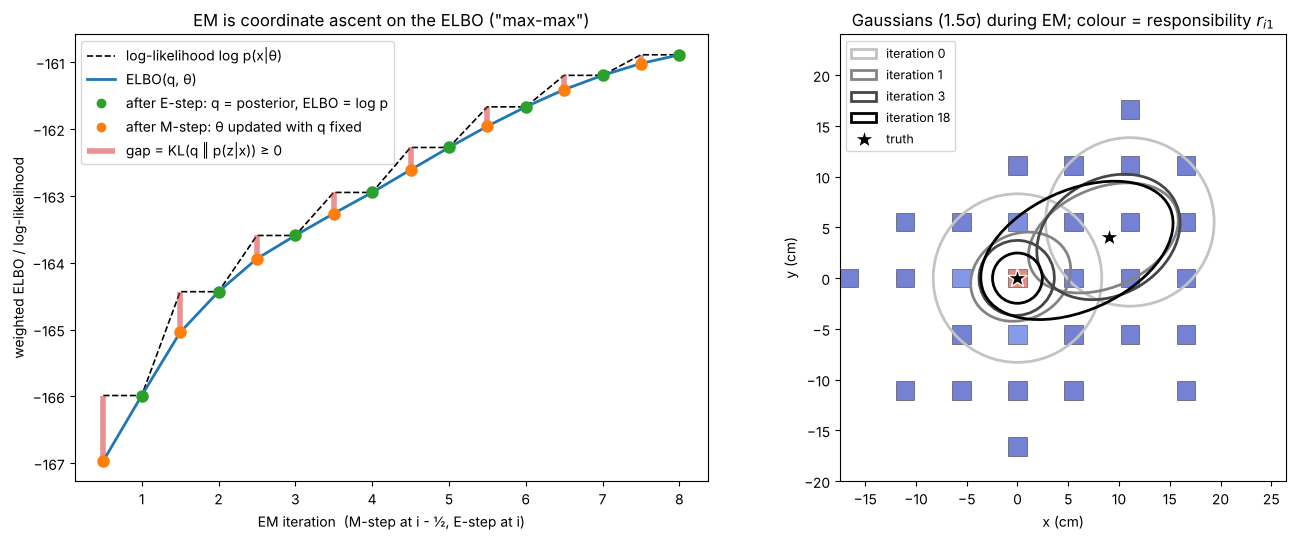

true energies                          : [40. 15.] GeV
EM, full covariance -> shared energies : [28.9 25.4] GeV
EM, fixed sigma     -> shared energies : [40.1 14.2] GeV


In [29]:
seeds = find_seeds_xy(demo['elmID'], E)
gmm = GaussianMixtureEM(2, covariance='full').fit(coords, sample_weight=E, init_means=seeds)
hist = gmm.history_

# x position of each half-step: iteration i -> M at i-0.5, E at i
xs = [h[0] - 0.5 if h[1] == 'M' else h[0] for h in hist]
elbo = np.array([h[2] for h in hist])
loglik = np.array([h[3] for h in hist])
sl = slice(1, min(len(xs), 2 * 8 + 1))  # skip the (very low) starting point, show 8 iterations

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ax = axes[0]
ax.plot(xs[sl], loglik[sl], 'k--', lw=1.2, label='log-likelihood log p(x|θ)')
ax.plot(xs[sl], elbo[sl], '-', color='C0', lw=2, label='ELBO(q, θ)')
for x, e, l, h in zip(xs[sl], elbo[sl], loglik[sl], hist[sl]):
    ax.plot(x, e, 'o', color='C1' if h[1] == 'M' else 'C2', ms=8, zorder=3)
    if h[1] == 'M':   # the gap KL(q || posterior) that opens after the M-step
        ax.vlines(x, e, l, color='C3', lw=4, alpha=0.5)
ax.plot([], [], 'o', color='C2', label='after E-step: q = posterior, ELBO = log p')
ax.plot([], [], 'o', color='C1', label='after M-step: θ updated with q fixed')
ax.vlines([], 0, 0, color='C3', lw=4, alpha=0.5, label='gap = KL(q ‖ p(z|x)) ≥ 0')
ax.set_xlabel('EM iteration  (M-step at i - ½, E-step at i)')
ax.set_ylabel('weighted ELBO / log-likelihood')
ax.set_title('EM is coordinate ascent on the ELBO ("max-max")')
ax.legend()

ax = axes[1]
draw_towers(ax, coords, E, c=gmm.responsibilities_[:, 0], cmap='coolwarm', vmin=0, vmax=1, alpha=0.7)
shown = [0, 1, 3, gmm.n_iter_]
for j, it in enumerate(shown):
    for k in range(2):
        draw_cov_ellipse(ax, gmm.means_history_[it][k], gmm.covariances_history_[it][k], n_sigma=1.5,
                         color=plt.cm.Greys(0.35 + 0.65 * j / (len(shown) - 1)), lw=2,
                         label=f'iteration {it}' if k == 0 else None)
ax.plot(*demo['true_xy'].T, 'k*', ms=15, mec='w', label='truth')
zoom(ax, demo['true_xy'].mean(0), 22)
ax.set_title('Gaussians (1.5σ) during EM; colour = responsibility $r_{i1}$')
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

print('true energies                          :', demo['true_E'], 'GeV')
print('EM, full covariance -> shared energies :', np.round(gmm.cluster_energies(E), 1), 'GeV')
g_fix = GaussianMixtureEM(2, covariance='fixed', sigma=2.7).fit(coords, sample_weight=E, init_means=seeds)
print('EM, fixed sigma     -> shared energies :', np.round(g_fix.cluster_energies(E), 1), 'GeV')

<div class="alert alert-success">

*--> (put your text here)*

- After every **E-step** the ELBO touches the log-likelihood: $q$ is set to the exact posterior, so $D_\mathrm{KL}(q\,\|\,p_\theta(z|x)) = 0$.
- The **M-step** increases the ELBO by changing $\theta$ with $q$ fixed. The log-likelihood increases by at least as much, because the KL gap that opens up is non-negative.
- The following E-step closes the gap again. Each step is a maximisation of the same function in one block of variables, so the sequence is monotonic &mdash; this is EM's convergence guarantee (to a local maximum).
- A higher likelihood is not automatically better physics: with a free covariance the Gaussian of the small shower grows until it also swallows the low-energy tails of the large shower, and the shared energies come out wrong. The lateral shower profile has long, non-Gaussian tails. Fixing the width to the physical shower width ($\sigma \approx 2.7$ cm, see below) gives energies close to the truth.
</div>

<div class="alert alert-info">
<strong>Exercise:</strong> 
Demonstrate that $K$-means is the $\sigma \to 0$ limit of EM: use <code>covariance="fixed"</code> and decrease $\sigma$ (e.g. 12, 6, 3, 1, 0.3 cm). Colour each hit by its responsibility and compare with the energy-weighted $K$-means partition. What happens to the shared energy $E_k$?
</div>

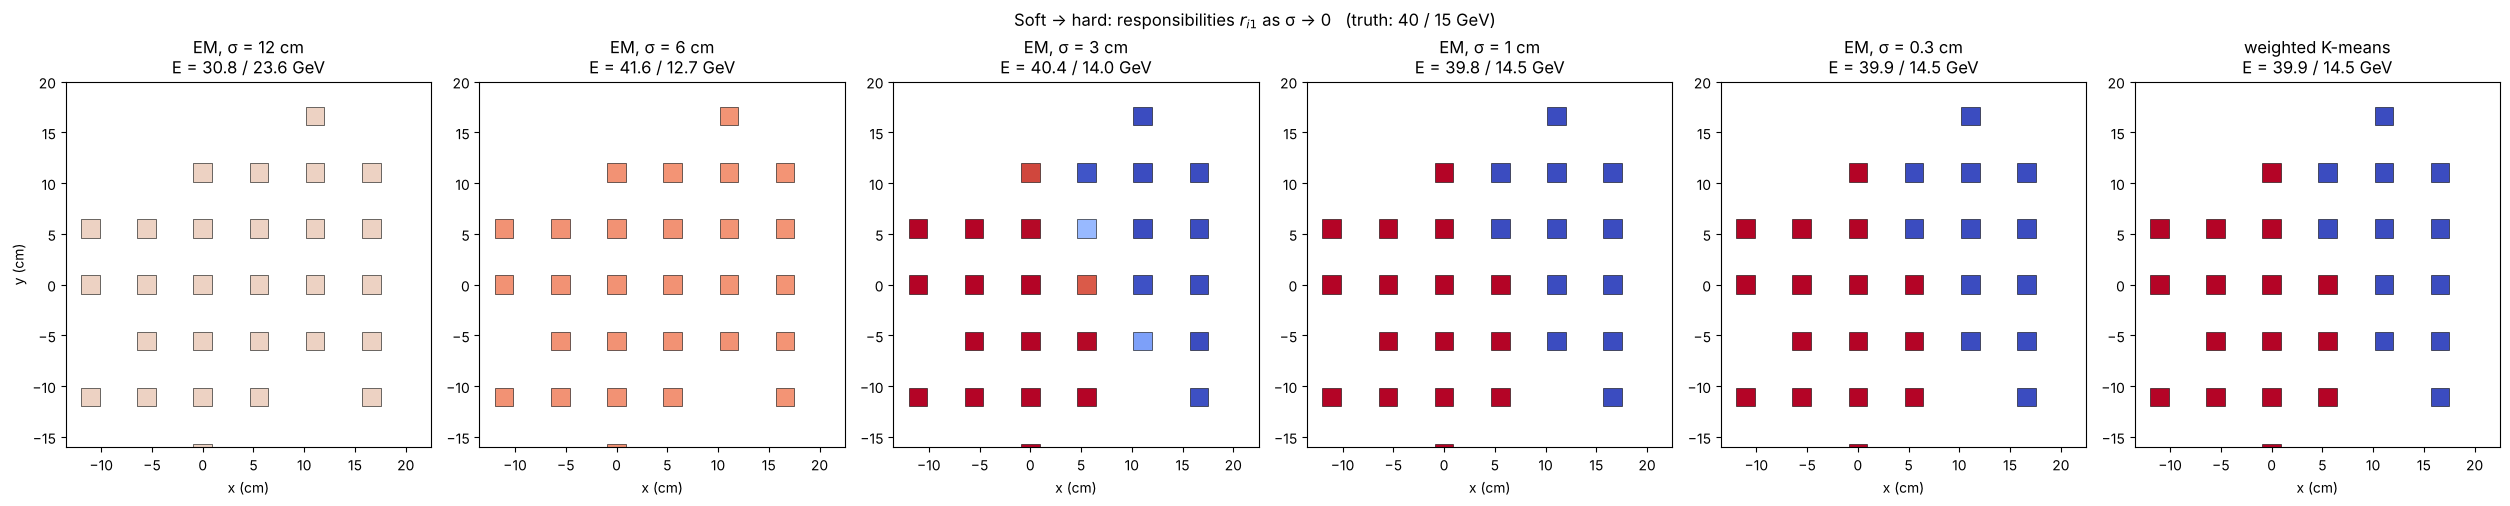

In [30]:
sigmas = [12, 6, 3, 1, 0.3]
_, lab_km, _ = weighted_kmeans(coords, E, seeds)

fig, axes = plt.subplots(1, len(sigmas) + 1, figsize=(4.2 * (len(sigmas) + 1), 4.6))
for ax, s in zip(axes, sigmas):
    g = GaussianMixtureEM(2, covariance='fixed', sigma=s).fit(coords, sample_weight=E, init_means=seeds)
    draw_towers(ax, coords, E, c=g.responsibilities_[:, 0], cmap='coolwarm', vmin=0, vmax=1)
    Ek = g.cluster_energies(E)
    ax.set_title(f'EM, σ = {s} cm\nE = {Ek[0]:.1f} / {Ek[1]:.1f} GeV')
    zoom(ax, demo['true_xy'].mean(0), 18)
ax = axes[-1]
draw_towers(ax, coords, E, c=1 - lab_km, cmap='coolwarm', vmin=0, vmax=1)
Ekm = [E[lab_km == k].sum() for k in range(2)]
ax.set_title(f'weighted K-means\nE = {Ekm[0]:.1f} / {Ekm[1]:.1f} GeV')
zoom(ax, demo['true_xy'].mean(0), 18)
for ax in axes[1:]:
    ax.set_ylabel('')
fig.suptitle(f'Soft → hard: responsibilities $r_{{i1}}$ as σ → 0   (truth: {demo["true_E"][0]:.0f} / {demo["true_E"][1]:.0f} GeV)', y=1.02)
plt.tight_layout()
plt.show()

<div class="alert alert-success">

*--> (put your text here)*

For large $\sigma$ every hit is shared by both components (responsibilities close to 0.5, energies pulled towards each other). As $\sigma$ decreases the responsibilities saturate at 0 or 1, and for $\sigma \ll$ tower size the partition, and therefore the cluster energies, are identical to energy-weighted $K$-means. Intermediate $\sigma$ (about the energy-weighted shower width, 2&ndash;3 cm) gives the most physical energy sharing.
</div>

<div class="alert alert-info">
<strong>Exercise:</strong> 
<strong>Energy sharing vs. shower separation.</strong> For two showers at distance $d$, compare the cluster energies from (i) energy-weighted $K$-means, (ii) EM with fixed $\sigma$ and (iii) EM with full covariance against the truth. As reference use the true <em>visible</em> energy of each shower, $E^\mathrm{vis}_k = \sum_i f^\mathrm{true}_{ik} E_i$ (from <code>true_fraction</code>), so that only the sharing is tested. Also record how often <code>seed_search</code> finds two seeds at all. Which value of $\sigma$ would you choose (hint: measure the energy-weighted width of single showers)?
</div>

energy-weighted width of a single shower (per coordinate): 2.66 cm


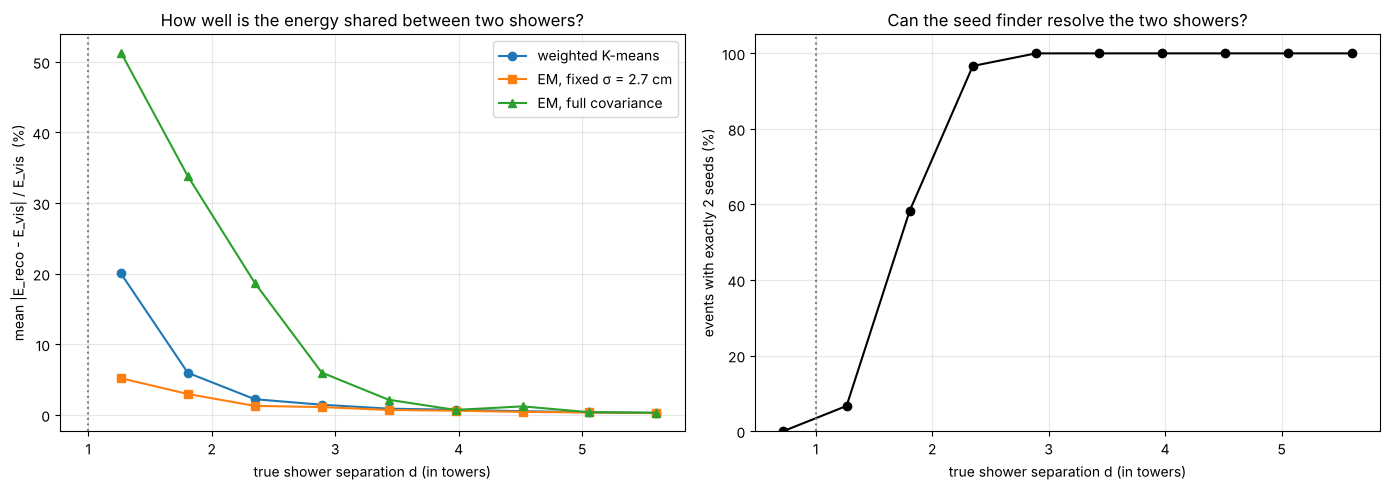

In [31]:
# energy-weighted width of single showers -> physical choice of sigma
widths = []
for s in range(200):
    ev = ex3.generate_shower_event(1, random_seed=5000 + s)
    X, Ev = event_to_xy_gev(ev)
    widths.append(np.sqrt(np.average(np.sum((X - np.average(X, axis=0, weights=Ev)) ** 2, axis=1), weights=Ev) / 2))
sigma_phys = float(np.median(widths))
print(f'energy-weighted width of a single shower (per coordinate): {sigma_phys:.2f} cm')

separations = np.arange(4, 34, 3.0)
methods = ['weighted K-means', f'EM, fixed σ = {sigma_phys:.1f} cm', 'EM, full covariance']
err = {m: [] for m in methods}
seed_eff = []
for d in separations:
    e_d = {m: [] for m in methods}
    n_two = 0
    n_try = 120
    for s in range(n_try):
        ev = ex3.generate_shower_event(2, min_separation=d, max_separation=d + 0.01, random_seed=int(10_000 * d) + s)
        X, Ev = event_to_xy_gev(ev)
        seeds_d = find_seeds_xy(ev['elmID'], Ev)
        if len(seeds_d) != 2:
            continue
        n_two += 1
        E_vis = ev['true_fraction'].T @ Ev
        c, lab, _ = weighted_kmeans(X, Ev, seeds_d)
        reco = {methods[0]: (c, np.array([Ev[lab == k].sum() for k in range(2)]))}
        for m, cov in zip(methods[1:], ['fixed', 'full']):
            g = GaussianMixtureEM(2, covariance=cov, sigma=sigma_phys).fit(X, sample_weight=Ev, init_means=seeds_d)
            reco[m] = (g.means_, g.cluster_energies(Ev))
        for m, (centers, Ek) in reco.items():
            idx = list(match_to_truth(centers, ev['true_xy']))
            e_d[m].append(np.mean(np.abs(Ek[idx] - E_vis) / E_vis))
    seed_eff.append(n_two / n_try)
    for m in methods:
        err[m].append(np.mean(e_d[m]) if e_d[m] else np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for m, mk in zip(methods, ['o-', 's-', '^-']):
    axes[0].plot(separations / CELL, 100 * np.array(err[m]), mk, label=m)
axes[0].set_xlabel('true shower separation d (in towers)')
axes[0].set_ylabel('mean |E_reco - E_vis| / E_vis  (%)')
axes[0].set_title('How well is the energy shared between two showers?')
axes[0].legend()
axes[1].plot(separations / CELL, 100 * np.array(seed_eff), 'ko-')
axes[1].set_xlabel('true shower separation d (in towers)')
axes[1].set_ylabel('events with exactly 2 seeds (%)')
axes[1].set_title('Can the seed finder resolve the two showers?')
axes[1].set_ylim(0, 105)
for ax in axes:
    ax.axvline(1, color='gray', ls=':')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<div class="alert alert-success">

*--> (put your text here)*

- For well-separated showers (several towers) all methods agree: almost no tower is shared.
- When the showers overlap (1&ndash;3 towers apart) the hard assignment of $K$-means gives every shared tower entirely to one cluster and the energy error grows quickly; EM with a fixed $\sigma$ shares those towers and stays several times closer to the truth.
- EM with a free covariance is the *worst* of the three for overlapping showers: a Gaussian with free width absorbs the non-Gaussian tails of its neighbour. A fixed, physically motivated $\sigma$ (the measured shower width) builds our physics knowledge into the model and has far fewer parameters to fit from a handful of towers.
- Below about one tower the seed finder usually sees only one local maximum: no clustering algorithm can split what was never seeded. This is where shower-shape information (Problem 4.4) helps.
</div>

<div class="alert alert-info">
<strong>Exercise:</strong> 
<strong>Choosing $K$ with a likelihood.</strong> A probabilistic model gives a principled alternative to the elbow and silhouette methods of Problem 3.2: the Bayesian Information Criterion
$$\mathrm{BIC}(K) = -2\log p_{\hat\theta}(x) + n_\mathrm{par}(K)\,\ln N ,$$
which trades the improvement of the fit against the number of parameters. Generate 100 events each with 1, 2 and 3 showers, choose $K \in \{1,\dots,5\}$ by minimal BIC (fixed $\sigma$, several random initialisations per $K$) and show the result as a confusion matrix.
</div>

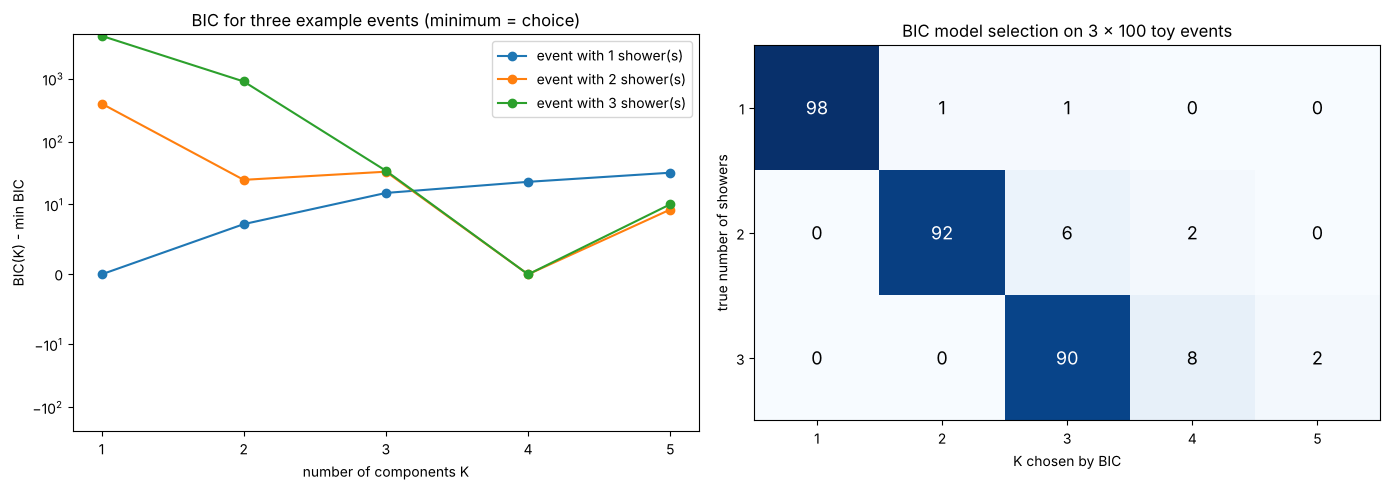

fraction correct: 0.93


In [32]:
def best_gmm(X, Ev, K, n_init=4, **kwargs):
    '''Best of several random initialisations (highest log-likelihood).'''
    best = None
    for seed in range(n_init):
        g = GaussianMixtureEM(K, random_state=seed, **kwargs).fit(X, sample_weight=Ev)
        ll = g.log_likelihood(X, g._w)
        if best is None or ll > best[0]:
            best = (ll, g)
    return best[1]


K_range = np.arange(1, 6)
true_K_values = [1, 2, 3]
confusion = np.zeros((len(true_K_values), len(K_range)), dtype=int)
example_bic = {}
for a, K_true in enumerate(true_K_values):
    for s in range(100):
        ev = ex3.generate_shower_event(K_true, min_separation=12, max_separation=45, random_seed=20_000 + 100 * K_true + s)
        X, Ev = event_to_xy_gev(ev)
        bics = [best_gmm(X, Ev, K, covariance='fixed', sigma=sigma_phys).bic(X) if K <= len(X) else np.inf for K in K_range]
        confusion[a, np.argmin(bics)] += 1
        if s == 0:
            example_bic[K_true] = bics

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for K_true, bics in example_bic.items():
    axes[0].plot(K_range, np.array(bics) - np.min(bics), 'o-', label=f'event with {K_true} shower(s)')
axes[0].set_xticks(K_range)
axes[0].set_xlabel('number of components K')
axes[0].set_ylabel('BIC(K) - min BIC')
axes[0].set_yscale('symlog', linthresh=10)
axes[0].set_title('BIC for three example events (minimum = choice)')
axes[0].legend()
im = axes[1].imshow(confusion, cmap='Blues')
for (i, j), v in np.ndenumerate(confusion):
    axes[1].text(j, i, v, ha='center', va='center', color='w' if v > 50 else 'k', fontsize=13)
axes[1].set_xticks(range(len(K_range)), K_range)
axes[1].set_yticks(range(len(true_K_values)), true_K_values)
axes[1].set_xlabel('K chosen by BIC')
axes[1].set_ylabel('true number of showers')
axes[1].set_title('BIC model selection on 3 x 100 toy events')
plt.tight_layout()
plt.show()
print(f'fraction correct: {np.trace(confusion[:, :3]) / confusion.sum():.2f}')

<div class="alert alert-success">

*--> (put your text here)*

BIC picks the correct number of showers in the large majority of events without any hand-tuned "elbow" criterion. Its typical failure is choosing one component too many, when a low-energy tail hit far from the core is cheaper to "explain" with an extra narrow Gaussian &mdash; the price of describing a non-Gaussian shower profile with Gaussians. Compared to the elbow/silhouette methods, the likelihood knows the expected shower width (through $\sigma$) and the energies of the hits.
</div>

<div class="alert alert-info">
<strong>Exercise:</strong> 
<strong>Real events.</strong> Apply the seeded, energy-weighted EM (fixed $\sigma$) to events of the A&prime; &rarr; e<sup>+</sup>e<sup>&minus;</sup> sample. <code>ex3.get_aprime_event(i)</code> returns the EMCal hits and the generated lepton energies and impact points. Compare the reconstructed cluster energies with the truth. What makes these events harder than the toy events?
</div>

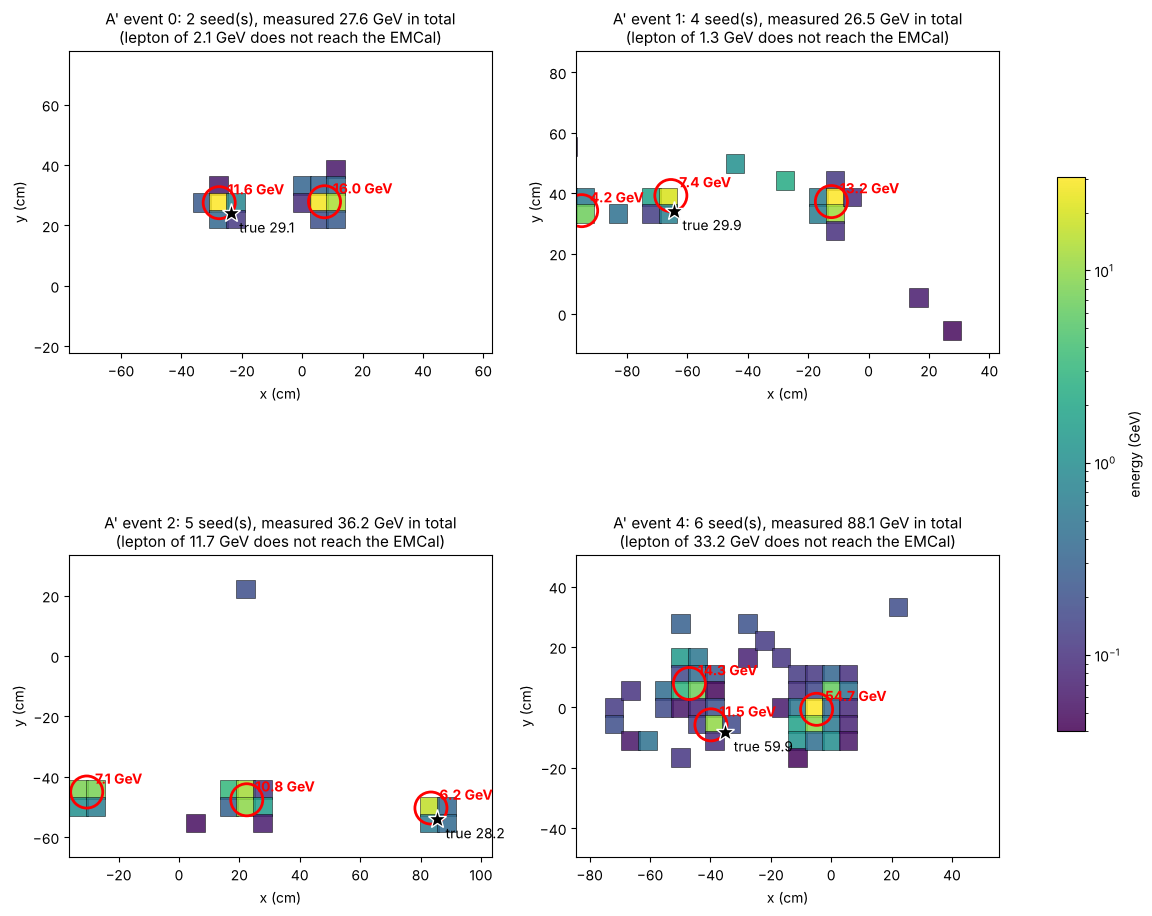

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, i in zip(axes.ravel(), [0, 1, 2, 4]):
    ev = ex3.get_aprime_event(i)
    X, Ev = event_to_xy_gev(ev)
    seeds_i = find_seeds_xy(ev['elmID'], Ev, threshold=1.0)
    sc = draw_towers(ax, X, Ev, norm=LogNorm(vmin=0.04, vmax=max(Ev.max(), 0.05)), alpha=0.85)
    if len(seeds_i) > 0:
        g = GaussianMixtureEM(len(seeds_i), covariance='fixed', sigma=sigma_phys).fit(X, sample_weight=Ev, init_means=seeds_i)
        for mu, Ek in zip(g.means_, g.cluster_energies(Ev)):
            ax.add_patch(plt.Circle(mu, 2 * sigma_phys, fill=False, color='r', lw=2))
            ax.annotate(f'{Ek:.1f} GeV', mu, xytext=(6, 6), textcoords='offset points', color='r', fontsize=10, weight='bold')
    for (x, y), Et in zip(ev['true_xy'], ev['true_E']):
        if np.isfinite(x):
            ax.plot(x, y, 'k*', ms=14, mec='w')
            ax.annotate(f'true {Et:.1f}', (x, y), xytext=(6, -14), textcoords='offset points', fontsize=10)
    missing = ', '.join(f'{Et:.1f}' for (x, _), Et in zip(ev['true_xy'], ev['true_E']) if not np.isfinite(x))
    ax.set_title(f"A' event {i}: {len(seeds_i)} seed(s), measured {Ev.sum():.1f} GeV in total" + (f'\n(lepton of {missing} GeV does not reach the EMCal)' if missing else ''), fontsize=11)
    centre = np.average(X, axis=0, weights=Ev)
    ax.set_xlim(centre[0] - 70, centre[0] + 70)
    ax.set_ylim(centre[1] - 50, centre[1] + 50)
plt.colorbar(sc, ax=axes, label='energy (GeV)', shrink=0.6)
plt.show()

<div class="alert alert-success">

*--> (put your text here)*

A lepton reaching the EMCal often produces *several* clusters: the electron itself and the bremsstrahlung photons it radiated in the material upstream, displaced by the magnetic field (event 0: 11.6 + 16.0 GeV for a 29.1 GeV electron). The sum of these clusters is close to, and slightly below, the generated energy (energy lost in front of the calorimeter and below threshold). These events are harder than the toy events: bremsstrahlung splits one particle into several clusters; some leptons never reach the calorimeter; and the shower profile is not Gaussian. Matching clusters to tracks (Problem 1.3) is what an experiment does next.
</div>

<a name='section_4_3'></a>
<hr style="height: 1px;">


<h3 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Problem 4.3: K-means as an autoencoder &mdash; a codebook of shower shapes</h3>


So far a *data point* was a hit. Now we change the point of view, as in the second part of the lecture: a **data point is a whole shower**,
i.e. the $7\times 7 = 49$ tower energies around the seed (normalised to a sum of 1). Every shower is a point in a 49-dimensional space,
and $K$-means works there exactly as in 2D (recall: *"a point can have 2, 3, or even hundreds of dimensions"*).

The lecture interprets $K$-means as an **autoencoder** with a discrete bottleneck:

$$
x \;\xrightarrow{\ \text{encoder: } \arg\min_k \lVert x-\mu_k\rVert\ }\; z \in \{0,\dots,K-1\} \text{ (one-hot)} \;\xrightarrow{\ \text{decoder: } z \mapsto \mu_z\ }\; x' = \mu_z
$$

The centroids $\{\mu_k\}$ are a **codebook** of shower templates, the inertia is the reconstruction loss, and sampling $z$ uniformly and decoding gives a (poor) **generative model**.

training set: (20000, 7, 7) | each image sums to 1.0


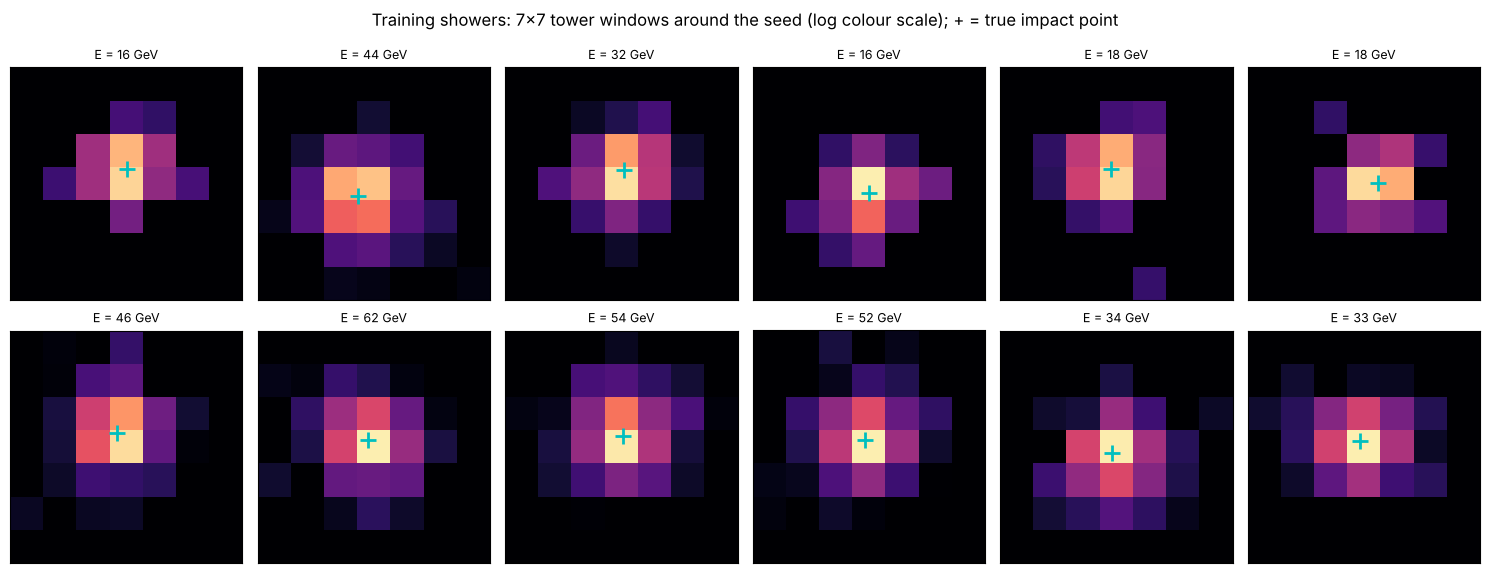

In [34]:
SIZE = 7
X_img, truth_img = ex3.make_shower_images(20_000, size=SIZE, kind='single', random_seed=1)
X_val, truth_val = ex3.make_shower_images(4_000, size=SIZE, kind='single', random_seed=2)
X_flat, X_val_flat = X_img.reshape(len(X_img), -1), X_val.reshape(len(X_val), -1)
print('training set:', X_img.shape, '| each image sums to', X_img[0].sum().round(3))

extent = [-(SIZE / 2) * CELL, (SIZE / 2) * CELL] * 2
fig, axes = plt.subplots(2, 6, figsize=(15, 6.0))
for ax, i in zip(axes.ravel(), range(12)):
    ax.imshow(X_img[i] + 1e-4, origin='lower', extent=extent, norm=LogNorm(1e-3, 1), cmap='magma')
    ax.plot(truth_img['dx'][i], truth_img['dy'][i], 'c+', ms=12, mew=2)
    ax.set_title(f"E = {truth_img['E'][i]:.0f} GeV", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Training showers: 7x7 tower windows around the seed (log colour scale); + = true impact point')
plt.tight_layout()
plt.show()

<div class="alert alert-info">
<strong>Exercise:</strong> 
Train <strong>your</strong> <code>KMeans</code> class (Problem 3.1) with $K=16$ on the 49-dimensional shower vectors. Plot the 16 codewords as images. For each codeword, also compute the mean true impact point $(\Delta x, \Delta y)$ of the showers assigned to it. What physical property does the codeword index encode?
</div>

In [35]:
K_code = 16
km16 = KMeans(n_clusters=K_code, max_iter=300, random_state=0).fit(X_flat)
codebook = km16.cluster_centers_.reshape(K_code, SIZE, SIZE)
codes = km16.labels_

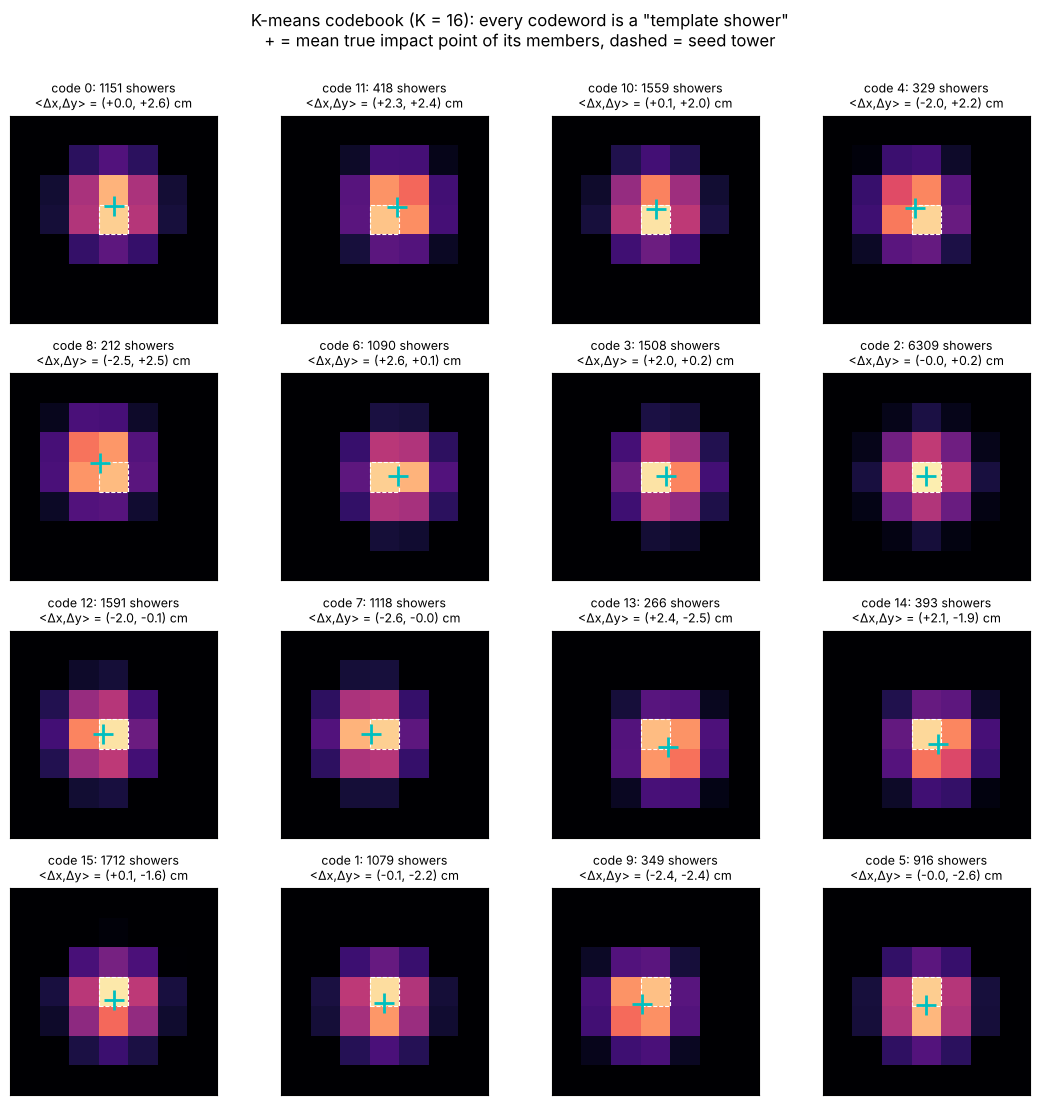

In [36]:
order = np.lexsort([[truth_img['dx'][codes == k].mean() for k in range(K_code)],
                     [np.round(truth_img['dy'][codes == k].mean(), 0) for k in range(K_code)]])[::-1]
fig, axes = plt.subplots(4, 4, figsize=(11, 11))
for ax, k in zip(axes.ravel(), order):
    ax.imshow(np.clip(codebook[k], 1e-4, None), origin='lower', extent=extent, norm=LogNorm(1e-3, 1), cmap='magma')
    mdx, mdy = truth_img['dx'][codes == k].mean(), truth_img['dy'][codes == k].mean()
    ax.plot(mdx, mdy, 'c+', ms=14, mew=2)
    ax.add_patch(plt.Rectangle((-CELL / 2, -CELL / 2), CELL, CELL, fill=False, color='w', lw=0.8, ls='--'))
    ax.set_title(f'code {k}: {np.sum(codes == k)} showers\n<Δx,Δy> = ({mdx:+.1f}, {mdy:+.1f}) cm', fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('K-means codebook (K = 16): every codeword is a "template shower"\n'
             '+ = mean true impact point of its members, dashed = seed tower', y=1.0)
plt.tight_layout()
plt.show()

<div class="alert alert-success">

*--> (put your text here)*

The codewords differ mainly in **where inside the seed tower the particle hit**: central impacts (almost all energy in the seed), impacts near an edge (energy leaking into one neighbour) and near a corner (leaking into three neighbours). The codeword index is a coarse, discrete measurement of the impact point &mdash; $K$-means discovered the most important latent variable of the shower without being told. The energy is hardly visible because the images are normalised.
</div>

<div class="alert alert-info">
<strong>Exercise:</strong> 
Use the codebook as an autoencoder: encode a few validation showers (<code>km16.predict</code>), decode them (look up the codeword) and plot original, reconstruction and residual. Then repeat the training for $K = 2, 4, \dots, 64$ and plot (a) the reconstruction error and (b) the impact-point resolution obtained by predicting $(\Delta x, \Delta y)$ as the mean of the codeword, both against the size of the code, $\log_2 K$ bits.
</div>

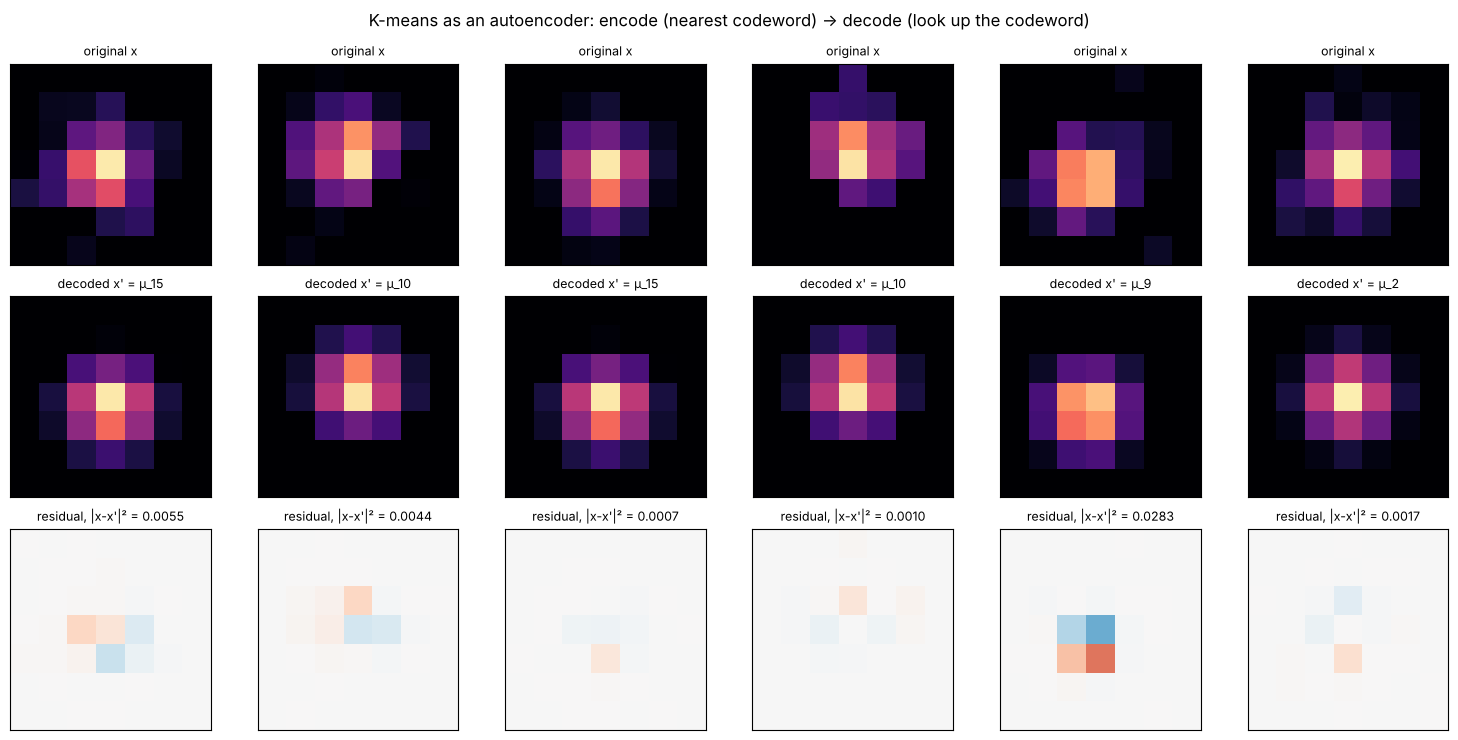

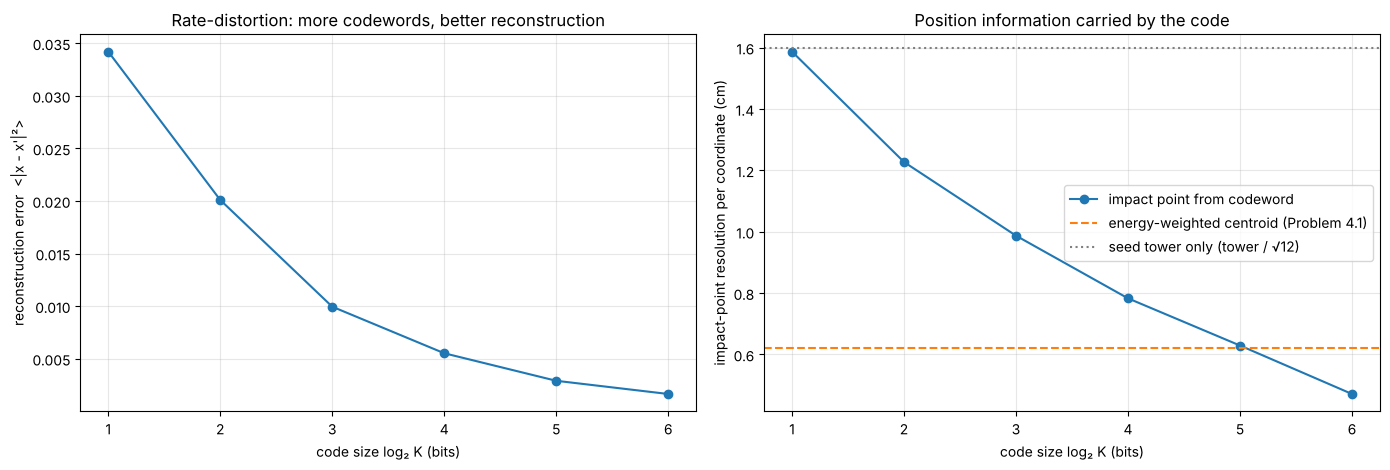

In [37]:
z_val = km16.predict(X_val_flat)
recon = km16.cluster_centers_[z_val].reshape(-1, SIZE, SIZE)
fig, axes = plt.subplots(3, 6, figsize=(15, 7.5))
for j in range(6):
    for row, (img, name) in enumerate([(X_val[j], 'original x'), (recon[j], f'decoded x\' = μ_{z_val[j]}')]):
        axes[row, j].imshow(np.clip(img, 1e-4, None), origin='lower', norm=LogNorm(1e-3, 1), cmap='magma')
        axes[row, j].set_title(name, fontsize=9)
    res = X_val[j] - recon[j]
    axes[2, j].imshow(res, origin='lower', cmap='RdBu_r', vmin=-0.2, vmax=0.2)
    axes[2, j].set_title(f'residual, |x-x\'|² = {np.sum(res ** 2):.4f}', fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('K-means as an autoencoder: encode (nearest codeword) → decode (look up the codeword)')
plt.tight_layout()
plt.show()

K_list = [2, 4, 8, 16, 32, 64]
mse, pos_res = [], []
for K in K_list:
    km = KMeans(n_clusters=K, max_iter=300, random_state=0).fit(X_flat)
    z_tr, z_va = km.labels_, km.predict(X_val_flat)
    mse.append(np.mean(np.sum((X_val_flat - km.cluster_centers_[z_va]) ** 2, axis=1)))
    mean_dx = np.array([truth_img['dx'][z_tr == k].mean() if np.any(z_tr == k) else 0 for k in range(K)])
    mean_dy = np.array([truth_img['dy'][z_tr == k].mean() if np.any(z_tr == k) else 0 for k in range(K)])
    pos_res.append(np.sqrt(np.mean((mean_dx[z_va] - truth_val['dx']) ** 2 + (mean_dy[z_va] - truth_val['dy']) ** 2) / 2))

centroid_dx = np.array([np.average(np.arange(-3, 4) * CELL, weights=img.sum(0)) for img in X_val])
centroid_dy = np.array([np.average(np.arange(-3, 4) * CELL, weights=img.sum(1)) for img in X_val])
res_centroid = np.sqrt(np.mean((centroid_dx - truth_val['dx']) ** 2 + (centroid_dy - truth_val['dy']) ** 2) / 2)

bits = np.log2(K_list)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(bits, mse, 'o-')
axes[0].set_ylabel('reconstruction error  <|x - x\'|²>')
axes[0].set_title('Rate-distortion: more codewords, better reconstruction')
axes[1].plot(bits, pos_res, 'o-', label='impact point from codeword')
axes[1].axhline(res_centroid, color='C1', ls='--', label='energy-weighted centroid (Problem 4.1)')
axes[1].axhline(CELL / np.sqrt(12), color='gray', ls=':', label='seed tower only (tower / √12)')
axes[1].set_ylabel('impact-point resolution per coordinate (cm)')
axes[1].set_title('Position information carried by the code')
axes[1].legend()
for ax in axes:
    ax.set_xlabel('code size log₂ K (bits)')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<div class="alert alert-success">

*--> (put your text here)*

- The reconstruction error falls steadily with $K$, roughly like a power law: each extra bit of code buys a fixed fraction of improvement.
- With about 5 bits (32 codewords) the code carries as much impact-point information as the energy-weighted centroid, and with 64 codewords the codebook beats it: it effectively learns the non-linear "S-curve" correction that the linear centroid misses.
- As a generative model, $K$-means can only ever produce $K$ distinct showers (the codewords themselves) &mdash; *"a valid generative model, but not a good one"*. To get a continuum of showers we need a continuous latent variable: the VAE.
</div>

<a name='section_4_4'></a>
<hr style="height: 1px;">


<h3 style="border:1px; border-style:solid; padding: 0.25em; color: #FFFFFF; background-color: #FFA500">Problem 4.4: A Variational Autoencoder for shower shapes</h3>


Replace the discrete code by a **continuous latent** $z \in \mathbb{R}^2$ with prior $p(z) = \mathcal{N}(0, \mathbb{1})$, and the analytic E-step by an **encoder network**:

$$
x \;\xrightarrow{\ \text{encoder } q_\phi(z|x) = \mathcal{N}(\mu_\phi(x),\,\mathrm{diag}\,\sigma^2_\phi(x))\ }\; z \;\xrightarrow{\ \text{decoder } p_\theta(x|z)\ }\; x'
$$

**Decoder likelihood.** Our images are *energy fractions* (they sum to 1). A natural model is that the shower energy arrives in $N_q$ independent
"quanta" (think of photo-electrons), each landing in tower $j$ with probability $p_j = \mathrm{softmax}(\text{decoder}(z))_j$. The log-likelihood is then a multinomial,

$$
\log p_\theta(x|z) = N_q \sum_j x_j \log p_j(z) + \text{const},
$$

i.e. $N_q$ times a cross-entropy. $N_q$ sets how precisely a shower is measured; it plays the role of $1/\beta$ in a $\beta$-VAE.

**Loss** = $-$ELBO, averaged over a mini-batch (one Monte-Carlo sample of $z$ per shower):

$$
\mathcal{L}(x) \;=\; \underbrace{-N_q \sum_j x_j \log p_j(z)}_{\text{reconstruction}} \;+\; \underbrace{\tfrac{1}{2}\sum_{l}\left(\mu_l^2 + \sigma_l^2 - \log\sigma_l^2 - 1\right)}_{D_\mathrm{KL}(q_\phi(z|x)\,\|\,\mathcal{N}(0,\mathbb{1}))}
$$

**Reparametrisation trick.** Sampling $z \sim \mathcal{N}(\mu,\sigma^2)$ is not differentiable, but $z = \mu + \sigma \odot \varepsilon$ with $\varepsilon \sim \mathcal{N}(0,\mathbb{1})$ is:
$\partial z/\partial \mu = 1$ and $\partial z/\partial \log\sigma^2 = \tfrac12\,\sigma\,\varepsilon$. The randomness is moved into an input $\varepsilon$.

To see every term of the ELBO (and of its gradient) we write the VAE in plain **NumPy**: one hidden layer (tanh) in encoder and decoder, trained with the Adam optimiser and back-propagation written out by hand.
Compared with the lecture's table: the network replaces the analytic posterior of EM, and SGD replaces the alternating steps.

<div class="alert alert-info">
<strong>Exercise:</strong> 
Implement the three ingredients of the VAE loss:
<ul>
<li><code>reparametrize(mu, logvar, eps)</code> &rarr; $z$</li>
<li><code>kl_divergence(mu, logvar)</code> &rarr; the KL term per sample <em>and</em> its gradients with respect to <code>mu</code> and <code>logvar</code></li>
<li><code>reconstruction_loss(x, logits)</code> &rarr; the cross-entropy $-\sum_j x_j \log\mathrm{softmax}(\text{logits})_j$ per sample <em>and</em> its gradient with respect to the logits (it is remarkably simple: $p\,\sum_j x_j - x$)</li>
</ul>
Verify your gradients with the finite-difference check below.
</div>

In [38]:
def softmax(a):
    a = a - a.max(axis=1, keepdims=True)
    e = np.exp(a)
    return e / e.sum(axis=1, keepdims=True)


def reparametrize(mu, logvar, eps):
    '''z = mu + sigma * eps, with sigma = exp(logvar / 2).'''
    return mu + np.exp(0.5 * logvar) * eps


def kl_divergence(mu, logvar):
    '''KL(N(mu, sigma^2) || N(0, 1)) summed over latent dims.

    Returns (kl (B,), dkl/dmu (B, L), dkl/dlogvar (B, L)).
    '''
    kl = 0.5 * np.sum(mu ** 2 + np.exp(logvar) - logvar - 1.0, axis=1)
    return kl, mu, 0.5 * (np.exp(logvar) - 1.0)


def reconstruction_loss(x, logits):
    '''Cross-entropy -sum_j x_j log softmax(logits)_j.

    Returns (loss (B,), dloss/dlogits (B, D)).
    '''
    a = logits - logits.max(axis=1, keepdims=True)
    log_p = a - np.log(np.sum(np.exp(a), axis=1, keepdims=True))
    loss = -np.sum(x * log_p, axis=1)
    grad = np.exp(log_p) * x.sum(axis=1, keepdims=True) - x
    return loss, grad

In [39]:
# finite-difference check of your gradients
rng_chk = np.random.default_rng(0)
mu_t, lv_t = rng_chk.normal(size=(4, 2)), rng_chk.normal(size=(4, 2))
x_t, lg_t = softmax(rng_chk.normal(size=(4, 9))), rng_chk.normal(size=(4, 9))
h = 1e-6


def numerical_grad(f, a):
    g = np.zeros_like(a)
    for idx in np.ndindex(a.shape):
        ap, am = a.copy(), a.copy()
        ap[idx] += h
        am[idx] -= h
        g[idx] = (f(ap).sum() - f(am).sum()) / (2 * h)
    return g


_, g_mu, g_lv = kl_divergence(mu_t, lv_t)
_, g_lg = reconstruction_loss(x_t, lg_t)
checks = {'dKL/dmu': (g_mu, numerical_grad(lambda m: kl_divergence(m, lv_t)[0], mu_t)),
          'dKL/dlogvar': (g_lv, numerical_grad(lambda v: kl_divergence(mu_t, v)[0], lv_t)),
          'dCE/dlogits': (g_lg, numerical_grad(lambda l: reconstruction_loss(x_t, l)[0], lg_t))}
for name, (analytic, numeric) in checks.items():
    print(f'{name:12s}: max |analytic - numerical| = {np.max(np.abs(analytic - numeric)):.2e}',
          'OK' if np.allclose(analytic, numeric, atol=1e-5) else 'WRONG')
z_t = reparametrize(np.zeros((1, 2)), np.log(np.full((1, 2), 4.0)), np.ones((1, 2)))
print('reparametrize(0, log 4, 1) =', z_t, '(expected [[2, 2]])')
print('KL(N(0,1) || N(0,1)) =', kl_divergence(np.zeros((1, 2)), np.zeros((1, 2)))[0], '(expected [0])')

dKL/dmu     : max |analytic - numerical| = 3.28e-10 OK
dKL/dlogvar : max |analytic - numerical| = 1.81e-10 OK
dCE/dlogits : max |analytic - numerical| = 1.43e-09 OK
reparametrize(0, log 4, 1) = [[2. 2.]] (expected [[2, 2]])
KL(N(0,1) || N(0,1)) = [0.] (expected [0])


The VAE itself is provided. Read through `loss_and_grads`: it is the chain rule applied to
encoder $\to$ reparametrisation $\to$ decoder $\to$ loss, and it uses your three functions.

In [40]:
class ShowerVAE:
    '''A tiny VAE in NumPy: x -> [tanh] -> (mu, logvar) -> z -> [tanh] -> softmax(logits) = p.'''

    def __init__(self, n_in, n_hidden=128, n_latent=2, seed=0):
        rng = np.random.default_rng(seed)
        def init(fan_in, fan_out):
            return rng.normal(0, np.sqrt(1.0 / fan_in), (fan_in, fan_out))
        self.p = {'W1': init(n_in, n_hidden), 'b1': np.zeros(n_hidden),
                  'Wmu': init(n_hidden, n_latent), 'bmu': np.zeros(n_latent),
                  'Wlv': init(n_hidden, n_latent) * 0.1, 'blv': np.zeros(n_latent),
                  'W2': init(n_latent, n_hidden), 'b2': np.zeros(n_hidden),
                  'W3': init(n_hidden, n_in), 'b3': np.zeros(n_in)}
        self.m = {k: np.zeros_like(v) for k, v in self.p.items()}   # Adam moments
        self.v = {k: np.zeros_like(v) for k, v in self.p.items()}
        self.t = 0
        self.n_latent = n_latent

    # ---------- forward ----------
    def encode(self, x):
        h = np.tanh(x @ self.p['W1'] + self.p['b1'])
        return h @ self.p['Wmu'] + self.p['bmu'], h @ self.p['Wlv'] + self.p['blv'], h

    def decode_logits(self, z):
        g = np.tanh(z @ self.p['W2'] + self.p['b2'])
        return g @ self.p['W3'] + self.p['b3'], g

    def decode(self, z):
        '''Decoder mean: energy fraction per tower, p(z).'''
        return softmax(self.decode_logits(z)[0])

    # ---------- loss and backward pass ----------
    def loss_and_grads(self, x, n_quanta, rng):
        B = len(x)
        mu, logvar, h = self.encode(x)
        eps = rng.standard_normal(mu.shape)
        z = reparametrize(mu, logvar, eps)
        logits, g = self.decode_logits(z)
        rec, d_logits = reconstruction_loss(x, logits)
        kl, d_mu_kl, d_lv_kl = kl_divergence(mu, logvar)
        loss = np.mean(n_quanta * rec + kl)

        grads = {}
        d_logits = n_quanta * d_logits / B                      # decoder
        grads['W3'], grads['b3'] = g.T @ d_logits, d_logits.sum(0)
        d_g = (d_logits @ self.p['W3'].T) * (1 - g ** 2)
        grads['W2'], grads['b2'] = z.T @ d_g, d_g.sum(0)
        d_z = d_g @ self.p['W2'].T
        d_mu = d_z + d_mu_kl / B                                # reparametrisation: dz/dmu = 1
        d_lv = d_z * 0.5 * np.exp(0.5 * logvar) * eps + d_lv_kl / B   # dz/dlogvar = sigma*eps/2
        grads['Wmu'], grads['bmu'] = h.T @ d_mu, d_mu.sum(0)    # encoder
        grads['Wlv'], grads['blv'] = h.T @ d_lv, d_lv.sum(0)
        d_h = (d_mu @ self.p['Wmu'].T + d_lv @ self.p['Wlv'].T) * (1 - h ** 2)
        grads['W1'], grads['b1'] = x.T @ d_h, d_h.sum(0)
        return loss, np.mean(n_quanta * rec), np.mean(kl), grads

    def adam_step(self, grads, lr=1e-3, b1=0.9, b2=0.999, eps=1e-8):
        self.t += 1
        for k in self.p:
            self.m[k] = b1 * self.m[k] + (1 - b1) * grads[k]
            self.v[k] = b2 * self.v[k] + (1 - b2) * grads[k] ** 2
            m_hat, v_hat = self.m[k] / (1 - b1 ** self.t), self.v[k] / (1 - b2 ** self.t)
            self.p[k] -= lr * m_hat / (np.sqrt(v_hat) + eps)

    # ---------- evaluation ----------
    def negative_elbo(self, x, n_quanta, n_samples=10, seed=0):
        '''Monte-Carlo estimate of -ELBO per shower (lower = more "shower-like").'''
        rng = np.random.default_rng(seed)
        mu, logvar, _ = self.encode(x)
        kl = kl_divergence(mu, logvar)[0]
        rec = np.zeros(len(x))
        for _ in range(n_samples):
            z = reparametrize(mu, logvar, rng.standard_normal(mu.shape))
            rec += reconstruction_loss(x, self.decode_logits(z)[0])[0] / n_samples
        return n_quanta * rec + kl


def train_vae(vae, X_train, X_valid, n_quanta, epochs=40, batch_size=128, lr=2e-3, seed=0):
    rng = np.random.default_rng(seed)
    log = {'loss': [], 'rec': [], 'kl': [], 'val': []}
    for epoch in range(epochs):
        perm = rng.permutation(len(X_train))
        tot = np.zeros(3)
        for start in range(0, len(X_train), batch_size):
            batch = X_train[perm[start:start + batch_size]]
            loss, rec, kl, grads = vae.loss_and_grads(batch, n_quanta, rng)
            vae.adam_step(grads, lr=lr)
            tot += np.array([loss, rec, kl]) * len(batch)
        tot /= len(X_train)
        for key, val in zip(['loss', 'rec', 'kl'], tot):
            log[key].append(val)
        log['val'].append(np.mean(vae.negative_elbo(X_valid, n_quanta, n_samples=1, seed=epoch)))
        if epoch % 10 == 0 or epoch == epochs - 1:
            print(f'epoch {epoch:3d}:  -ELBO = {tot[0]:7.2f}  (rec {tot[1]:7.2f} + KL {tot[2]:5.2f})   validation -ELBO = {log["val"][-1]:7.2f}')
    return log

<div class="alert alert-info">
<strong>Exercise:</strong> 
Train the VAE with a 2-dimensional latent space and $N_q = 200$ on the 20 000 training showers (this takes about a minute). Plot the training curves. Why does the KL term first increase before it settles?
</div>

epoch   0:  -ELBO =  329.86  (rec  326.63 + KL  3.23)   validation -ELBO =  279.82


epoch  10:  -ELBO =  242.34  (rec  237.33 + KL  5.01)   validation -ELBO =  241.63


epoch  20:  -ELBO =  241.47  (rec  236.94 + KL  4.53)   validation -ELBO =  240.89


epoch  30:  -ELBO =  240.86  (rec  236.82 + KL  4.04)   validation -ELBO =  240.22


epoch  39:  -ELBO =  240.72  (rec  236.78 + KL  3.94)   validation -ELBO =  240.11


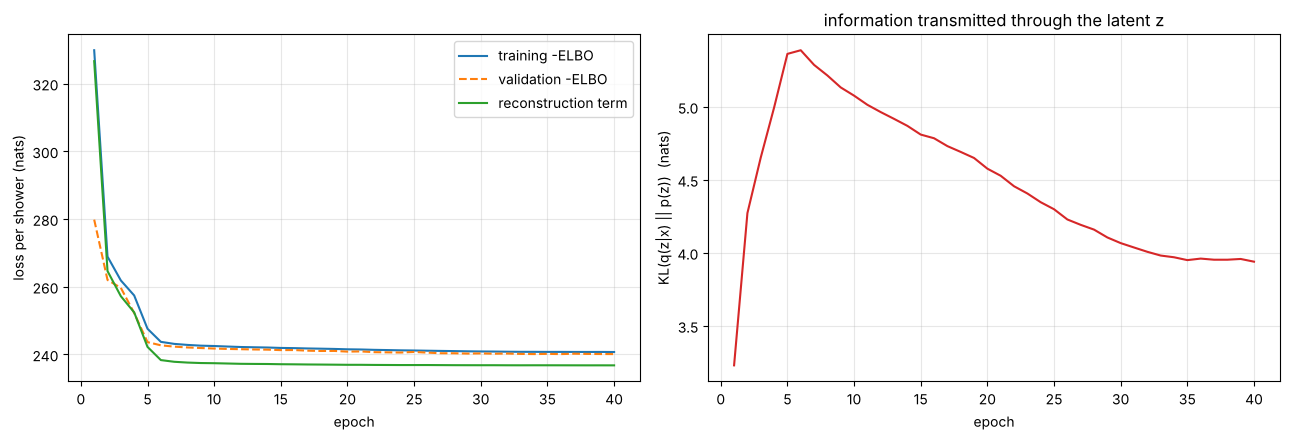

In [41]:
N_Q = 200
vae = ShowerVAE(n_in=SIZE * SIZE, n_hidden=128, n_latent=2, seed=0)
log = train_vae(vae, X_flat, X_val_flat, n_quanta=N_Q, epochs=40)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ep = np.arange(1, len(log['loss']) + 1)
axes[0].plot(ep, log['loss'], label='training -ELBO')
axes[0].plot(ep, log['val'], '--', label='validation -ELBO')
axes[0].plot(ep, log['rec'], label='reconstruction term')
axes[0].set_ylabel('loss per shower (nats)')
axes[0].legend()
axes[1].plot(ep, log['kl'], color='C3')
axes[1].set_ylabel('KL(q(z|x) || p(z))  (nats)')
axes[1].set_title('information transmitted through the latent z')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

<div class="alert alert-success">

*--> (put your text here)*

At the start the decoder ignores $z$ (KL $\approx 0$, every shower is reconstructed as the average shower). Reconstruction improves only if the encoder starts *transmitting information* about each shower through $z$, which costs KL. The KL term grows until the gain in reconstruction no longer pays for the extra nats; $N_q$ sets the exchange rate (larger $N_q$ = more precise showers = more information in $z$). The validation curve follows the training curve: no over-fitting with 20 000 showers and a few thousand parameters.
</div>

<div class="alert alert-info">
<strong>Exercise:</strong> 
<strong>What did the VAE learn?</strong> Encode the validation showers and plot the latent means $\mu_\phi(x)$, coloured by the true impact point $\Delta x$, $\Delta y$ and by the energy. Then decode a regular grid of $z$ values (the "shower manifold", compare with the MNIST examples in the lecture).
</div>

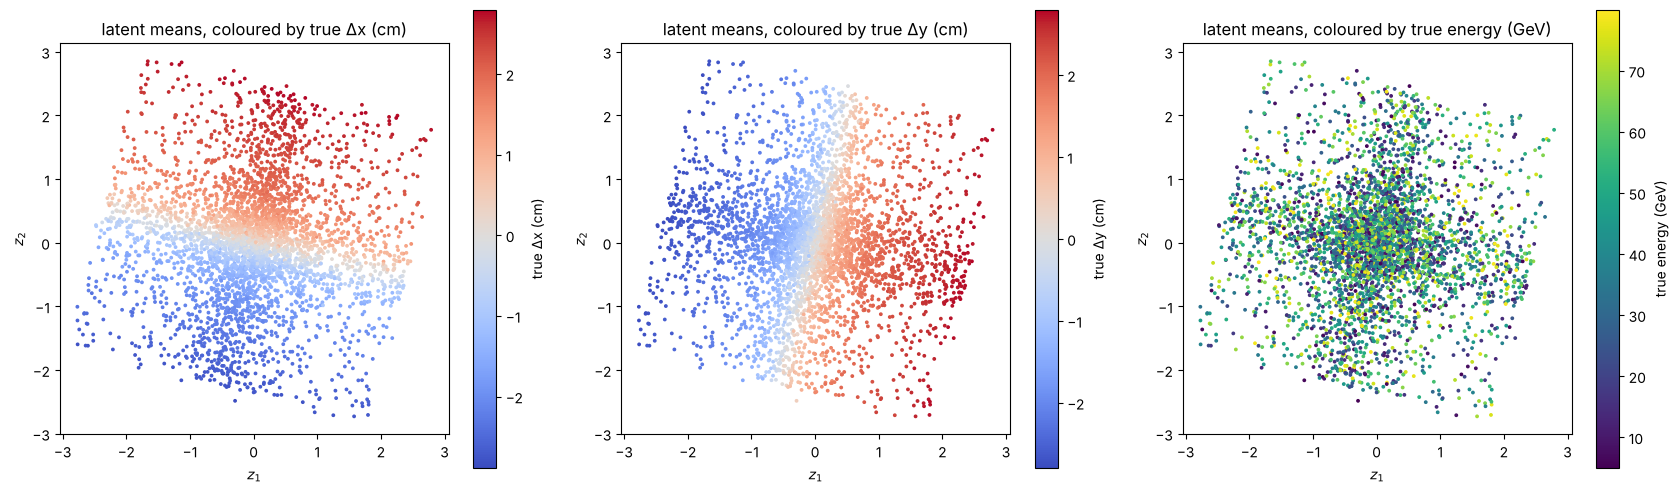

correlation of (z1, z2) with [true dx, true dy, centroid x, centroid y]:
[[ 0.23  0.93  0.24  0.97]
 [ 0.93 -0.22  0.97 -0.23]]


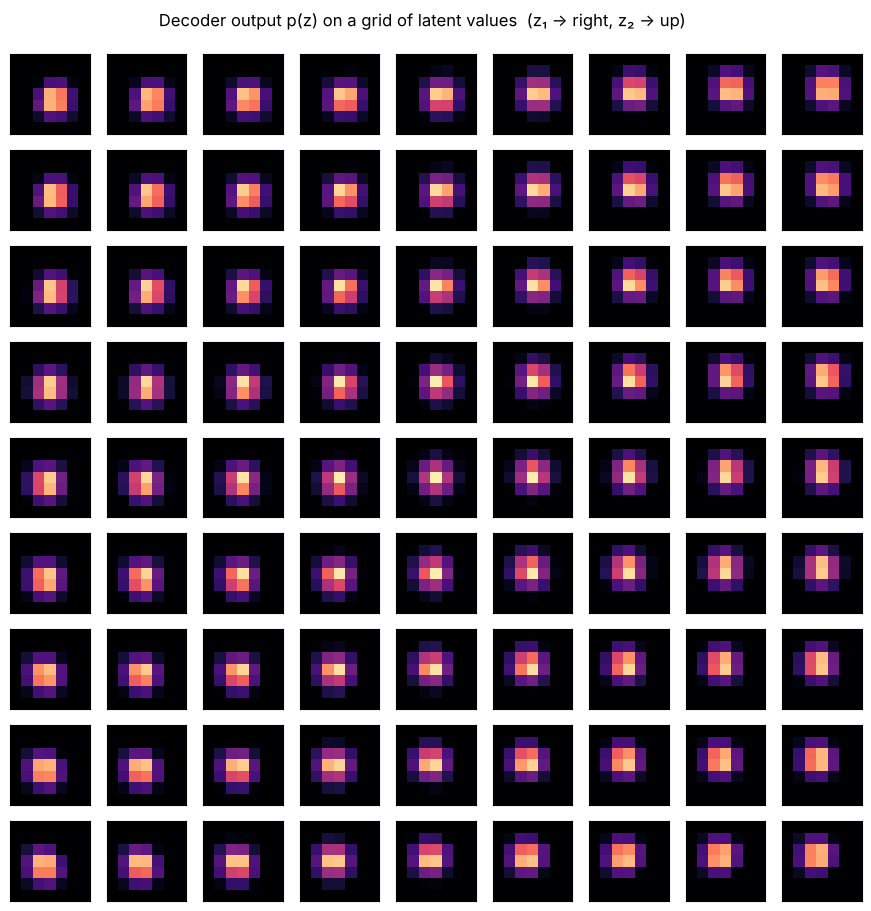

In [42]:
mu_val, logvar_val, _ = vae.encode(X_val_flat)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, key, label, cmap in [(axes[0], 'dx', 'true Δx (cm)', 'coolwarm'), (axes[1], 'dy', 'true Δy (cm)', 'coolwarm'),
                             (axes[2], 'E', 'true energy (GeV)', 'viridis')]:
    sc = ax.scatter(mu_val[:, 0], mu_val[:, 1], c=truth_val[key], s=3, cmap=cmap)
    plt.colorbar(sc, ax=ax, label=label)
    ax.set_xlabel('$z_1$')
    ax.set_ylabel('$z_2$')
    ax.set_aspect('equal')
    ax.set_title(f'latent means, coloured by {label}')
plt.tight_layout()
plt.show()

corr = np.corrcoef(np.c_[mu_val, truth_val['dx'], truth_val['dy'], centroid_dx, centroid_dy].T)[:2, 2:]
print('correlation of (z1, z2) with [true dx, true dy, centroid x, centroid y]:')
print(np.round(corr, 2))

n_grid = 9
grid = np.linspace(-2.2, 2.2, n_grid)
fig, axes = plt.subplots(n_grid, n_grid, figsize=(11, 11))
for a, z2 in enumerate(grid[::-1]):
    for b, z1 in enumerate(grid):
        img = vae.decode(np.array([[z1, z2]])).reshape(SIZE, SIZE)
        axes[a, b].imshow(img, origin='lower', norm=LogNorm(1e-3, 1), cmap='magma')
        axes[a, b].set_xticks([]); axes[a, b].set_yticks([])
fig.suptitle('Decoder output p(z) on a grid of latent values  (z₁ → right, z₂ → up)', y=0.92)
plt.show()

<div class="alert alert-success">

*--> (put your text here)*

The two latent directions encode the impact point inside the seed tower: the latent space is (up to a rotation and a non-linear stretch) a map of $(\Delta x, \Delta y)$ &mdash; strongly correlated with the energy-weighted centroid of Problem 4.1, i.e. the VAE has rediscovered the first moment, without labels. The energy is *not* encoded: we normalised it away, and the shower shape depends only weakly on energy. The decoded grid moves the shower continuously across the tower, from corner to centre to the opposite corner &mdash; something the 16 discrete codewords of $K$-means could not do.
</div>

<div class="alert alert-info">
<strong>Exercise:</strong> 
<strong>Generation.</strong> Sample showers from both generative models: $K$-means (pick a random codeword) and the VAE ($z \sim \mathcal{N}(0,\mathbb{1})$, decode, then draw $N_q$ quanta from the multinomial). Compare the distributions of two shower-shape observables with the simulated showers: the fraction of energy in the seed tower and the energy-weighted width.
</div>

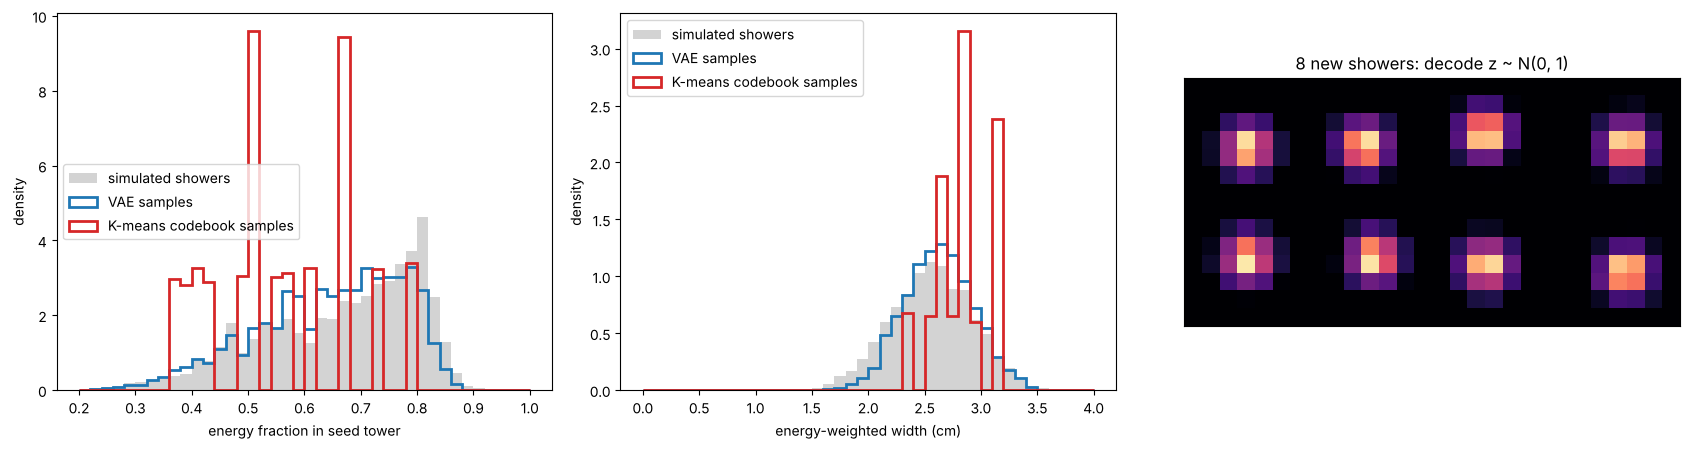

In [43]:
rng_gen = np.random.default_rng(3)
n_gen = 4000

def multinomial_images(P, n_quanta, rng):
    return np.array([rng.multinomial(n_quanta, p / p.sum()) for p in P]) / n_quanta

gen_km = km16.cluster_centers_[rng_gen.integers(0, K_code, n_gen)]
gen_vae = multinomial_images(vae.decode(rng_gen.standard_normal((n_gen, 2))), N_Q, rng_gen)
ref = multinomial_images(X_val_flat, N_Q, rng_gen)   # same measurement precision for a fair comparison

def seed_fraction(F):
    return F.reshape(-1, SIZE, SIZE)[:, SIZE // 2, SIZE // 2]

def shower_width(F):
    imgs = F.reshape(-1, SIZE, SIZE)
    pos = (np.arange(SIZE) - SIZE // 2) * CELL
    out = []
    for img in imgs:
        px, py = img.sum(0), img.sum(1)
        mx, my = np.sum(px * pos), np.sum(py * pos)
        out.append(np.sqrt((np.sum(px * (pos - mx) ** 2) + np.sum(py * (pos - my) ** 2)) / 2))
    return np.array(out)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, f, xlabel, bins in [(axes[0], seed_fraction, 'energy fraction in seed tower', np.linspace(0.2, 1, 41)),
                            (axes[1], shower_width, 'energy-weighted width (cm)', np.linspace(0, 4, 41))]:
    ax.hist(f(ref), bins=bins, density=True, color='lightgray', label='simulated showers')
    ax.hist(f(gen_vae), bins=bins, density=True, histtype='step', lw=2, color='C0', label='VAE samples')
    ax.hist(f(gen_km), bins=bins, density=True, histtype='step', lw=2, color='C3', label='K-means codebook samples')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('density')
    ax.legend()
new = vae.decode(rng_gen.standard_normal((8, 2))).reshape(8, SIZE, SIZE)
mosaic = np.concatenate([np.concatenate(list(new[:4]), 1), np.concatenate(list(new[4:]), 1)], 0)
axes[2].imshow(mosaic, origin='lower', norm=LogNorm(1e-3, 1), cmap='magma')
axes[2].set_title('8 new showers: decode z ~ N(0, 1)')
axes[2].set_xticks([]); axes[2].set_yticks([])
plt.tight_layout()
plt.show()

<div class="alert alert-success">

*--> (put your text here)*

The VAE samples follow the continuous distributions of the simulated showers well (small differences in the tails come from the tiny network and the 2D latent). The $K$-means generator produces spikes: only 16 different showers exist. Note the remaining limitation pointed out in the lecture: the VAE prior models one shower at a time; to generate a whole *event* (several correlated showers) one would need a model of the joint distribution (autoregressive, masked or diffusion models).
</div>

<div class="alert alert-info">
<strong>Exercise:</strong> 
<strong>The ELBO as a shower-shape test.</strong> $-\mathrm{ELBO}(x)$ is an upper bound on $-\log p_\theta(x)$, so it measures how "typical" a shower is. Compute it for (i) validation single showers, (ii) <em>merged</em> showers (two showers less than two towers apart, which the seed finder sees as one cluster) and (iii) MIP-like deposits (muons, Problem 1.2). Plot the distributions and the ROC curve for separating single from merged showers. Is the MIP result what you expected?
</div>

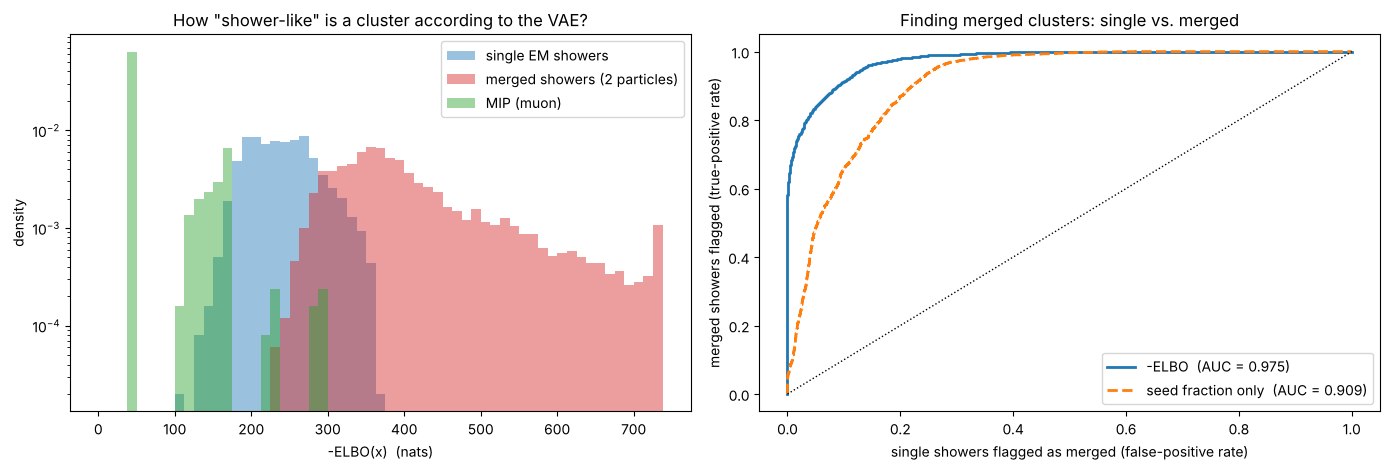

In [44]:
from sklearn.metrics import roc_curve, roc_auc_score

X_merged, _ = ex3.make_shower_images(4000, size=SIZE, kind='merged', random_seed=4)
X_mip, _ = ex3.make_shower_images(1000, size=SIZE, kind='mip', random_seed=5)
nelbo = {'single EM showers': vae.negative_elbo(X_val_flat, N_Q),
         'merged showers (2 particles)': vae.negative_elbo(X_merged.reshape(len(X_merged), -1), N_Q),
         'MIP (muon)': vae.negative_elbo(X_mip.reshape(len(X_mip), -1), N_Q)}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
bins = np.linspace(0, np.percentile(nelbo['merged showers (2 particles)'], 99), 60)
for (name, v), col in zip(nelbo.items(), ['C0', 'C3', 'C2']):
    axes[0].hist(np.clip(v, bins[0], bins[-1]), bins=bins, density=True, histtype='stepfilled', alpha=0.45, color=col, label=name)
axes[0].set_xlabel('-ELBO(x)  (nats)')
axes[0].set_ylabel('density')
axes[0].set_yscale('log')
axes[0].set_title('How "shower-like" is a cluster according to the VAE?')
axes[0].legend()

y = np.r_[np.zeros(len(nelbo['single EM showers'])), np.ones(len(nelbo['merged showers (2 particles)']))]
s = np.r_[nelbo['single EM showers'], nelbo['merged showers (2 particles)']]
fpr, tpr, _ = roc_curve(y, s)
axes[1].plot(fpr, tpr, lw=2, label=f'-ELBO  (AUC = {roc_auc_score(y, s):.3f})')
s_seed = -np.r_[seed_fraction(X_val_flat), seed_fraction(X_merged.reshape(len(X_merged), -1))]
fpr2, tpr2, _ = roc_curve(y, s_seed)
axes[1].plot(fpr2, tpr2, lw=2, ls='--', label=f'seed fraction only  (AUC = {roc_auc_score(y, s_seed):.3f})')
axes[1].plot([0, 1], [0, 1], 'k:', lw=1)
axes[1].set_xlabel('single showers flagged as merged (false-positive rate)')
axes[1].set_ylabel('merged showers flagged (true-positive rate)')
axes[1].set_title('Finding merged clusters: single vs. merged')
axes[1].legend()
plt.tight_layout()
plt.show()

<div class="alert alert-success">

*--> (put your text here)*

- Merged showers are atypical for a model trained on single showers and get a large $-$ELBO: the VAE flags clusters that should be split, more efficiently than a single hand-made variable such as the seed fraction. This closes the loop with Section 3: it tells us when $K$ should be larger than the number of seeds.
- The MIPs, however, get an even *smaller* $-$ELBO than real showers, although the VAE never saw a muon! A MIP puts all energy in a single tower; that is the "simplest" image, close to a centrally hitting shower, and the likelihood of simple inputs is high. This is a well-known pitfall of likelihood-based anomaly detection with generative models. The fix here is physics: we normalised the energy away; the total energy (0.3 GeV vs. tens of GeV) or the track momentum (Problem 1.3) identifies the muon immediately.
</div>

### Summary

| | data point | latent $z$ | $q(z)$ | optimisation | in this exercise |
|---|---|---|---|---|---|
| $K$-means | hit (Sec. 3, 4.1) or shower (4.3) | discrete, one-hot | hard assignment | alternating (hard EM) | clustering, shower codebook |
| EM / GMM | hit | discrete | exact posterior (soft) | alternating E/M steps | energy sharing, BIC for $K$ |
| VAE | shower | continuous | encoder network $q_\phi(z|x)$ | SGD + reparametrisation | shower manifold, generation, merged-cluster tagging |
| VQ-VAE | shower / image | discrete codebook | encoder + nearest codeword | SGD + straight-through | (bonus question) |

<div class="alert alert-info">
<strong>Bonus question:</strong> The VQ-VAE of the lecture puts a $K$-means codebook <em>inside</em> the bottleneck of an autoencoder.
Sketch how you would combine the codebook of Problem 4.3 with the encoder/decoder of Problem 4.4. Which loss terms are needed, and how would you back-propagate through the $\arg\min$ (the "straight-through" trick)?
What would be the advantage of a discrete code ("tokens") for a detector with millions of channels?
</div>

<div class="alert alert-success">

*--> (put your text here)*

Encoder $\to z_e \in \mathbb{R}^L$, replace $z_e$ by its nearest codeword $e_k$, decoder reconstructs from $e_k$. Loss = reconstruction + $\lVert \mathrm{sg}[z_e] - e_k\rVert^2$ (moves the codewords, i.e. the $K$-means M-step) + $\beta \lVert z_e - \mathrm{sg}[e_k]\rVert^2$ (commitment: keeps the encoder close to the codebook). In the backward pass the gradient with respect to $e_k$ is copied to $z_e$ (straight-through: forward uses the hard argmin, backward pretends it was the identity). Discrete tokens compress the detector read-out (a few bits per cluster instead of 49 floats) and can be modelled by sequence models (transformers) to generate or analyse whole events.
</div>